# Local RGB-D Grasp Refinement

Close-range (approximately 0.25-0.35 m) local refinement for one target at a time.

This notebook:

- supports live aligned RealSense RGB-D capture and offline RGB/raw-depth input;
- outputs pixel coordinates and `camera_color_optical_frame` coordinates only;
- does **not** transform points into robot base frame because hand-eye calibration is not available;
- never uses a depth colormap image for 3D calculation.

For base holes, the pixel is the center of the true black hole, while depth is sampled from the surrounding silver ring.

## Part 1: Imports and parameters

In [1]:
from __future__ import annotations

import csv
import itertools
import json
import math
import time
from pathlib import Path
from typing import Any

import cv2
import matplotlib.pyplot as plt
import numpy as np

try:
    import pyrealsense2 as rs
    REALSENSE_AVAILABLE = True
except ImportError:
    rs = None
    REALSENSE_AVAILABLE = False

CAMERA_FRAME_ID = "camera_color_optical_frame"
VALID_TARGET_TYPES = {
    "base", "gear_large", "gear_small", "gear_compound",
    "shaft_large", "shaft_small", "screw",
}

# Input selection.
INPUT_MODE = "live"  # "offline" or "live"
TARGET_TYPE = "shaft_small"  # Must be in VALID_TARGET_TYPES.
# Painted-black grasp-marker samples:
# gear_small:    20260610_141104
# screw:         20260610_141142
# gear_large:    20260610_141237
# gear_compound: 20260610_141258
OFFLINE_COLOR_PATH = Path("realsense_pic/realsense_color_20260615_170349.png")
OFFLINE_DEPTH_PATH = Path("realsense_pic/realsense_depth_raw_20260615_170349.npy")

# Existing saved RealSense raw files are uint16 millimeters. Multiplying by
# 0.001 converts them to meters. Set to 1.0 when the .npy already stores meters.
OFFLINE_DEPTH_SCALE_TO_M = 0.001

# Fill these with the color intrinsics captured at the same resolution.
# Keep None to test pixel detection without producing misleading 3D values.
OFFLINE_INTRINSICS = None
# Example structure only:
# OFFLINE_INTRINSICS = {"fx": ..., "fy": ..., "ppx": ..., "ppy": ...}

LIVE_WIDTH = 640
LIVE_HEIGHT = 480
LIVE_FPS = 30
LIVE_WARMUP_FRAMES = 20

OUTPUT_DIR = Path("local_rgbd_refinement_results")
OUTPUT_JSON = OUTPUT_DIR / "local_refinement_result.json"
OUTPUT_CSV = OUTPUT_DIR / "local_refinement_result.csv"
OUTPUT_ANNOTATED = OUTPUT_DIR / "local_refinement_annotated.png"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Red target segmentation.
# Keep saturated red gears separate from the lower-saturation warm cast that
# the Shaft_small supplemental white branch accepts.
RED_MIN_SATURATION = 160
RED_LOW_1 = np.array([0, RED_MIN_SATURATION, 40], dtype=np.uint8)
RED_HIGH_1 = np.array([12, 255, 255], dtype=np.uint8)
RED_LOW_2 = np.array([165, RED_MIN_SATURATION, 40], dtype=np.uint8)
RED_HIGH_2 = np.array([179, 255, 255], dtype=np.uint8)
RED_OPEN_KERNEL = 3
RED_CLOSE_KERNEL = 9
GEAR_MIN_AREA_PX = 2500
SCREW_MIN_AREA_PX = 120
SCREW_MAX_AREA_PX = 6000
SCREW_MAX_DIM_PX = 130

# Black target segmentation.
BLACK_MAX_VALUE = 95

# White shaft segmentation on the new black work background.
SHAFT_WHITE_MAX_SATURATION = 95
SHAFT_WHITE_MIN_VALUE = 130
SHAFT_WHITE_MIN_L = 135
SHAFT_WHITE_LAB_A_TOL = 32
SHAFT_WHITE_LAB_B_TOL = 40
SHAFT_WHITE_OPEN_KERNEL = 3
SHAFT_WHITE_CLOSE_KERNEL = 5
# Shaft_small only: tolerate the stable warm/red cast seen under the fixed
# Local camera profile.  Shaft_large deliberately keeps the original neutral
# white mask because its current detection is reliable and less ROI-constrained.
SHAFT_SMALL_CAST_MAX_SATURATION = 150
SHAFT_SMALL_CAST_MIN_VALUE = 115
SHAFT_SMALL_CAST_MIN_L = 115
SHAFT_SMALL_CAST_LAB_A_TOL = 45
SHAFT_SMALL_CAST_LAB_B_TOL = 45

# Painted grasp-marker segmentation. This is separate from shaft segmentation:
# gear markers are thin black strips, while the screw marker is a wider patch.
BLACK_GRASP_MARKER_MAX_VALUE = 100
BLACK_GRASP_MARKER_OPEN_KERNEL = 3
BLACK_GRASP_MARKER_CLOSE_KERNEL = 3
GEAR_BLACK_MARKER_CENTER_RADIUS_RATIO = 0.56
GEAR_BLACK_MARKER_MIN_AREA_PX = 100
GEAR_BLACK_MARKER_MAX_AREA_PX = 1800
GEAR_BLACK_MARKER_MIN_ASPECT_RATIO = 4.0
GEAR_BLACK_MARKER_MIN_LONG_SIDE_PX = 20
GEAR_BLACK_MARKER_MAX_LONG_SIDE_PX = 100
GEAR_BLACK_MARKER_MAX_PARALLEL_ANGLE_DEG = 18
GEAR_BLACK_MARKER_MAX_AXIS_DOT = 0.42
GEAR_BLACK_MARKER_MIN_SEPARATION_PX = 20
GEAR_SMALL_SQUARE_MIN_AREA_PX = 250
GEAR_SMALL_SQUARE_MAX_AREA_RATIO = 0.18
GEAR_SMALL_SQUARE_MIN_RECTANGULARITY = 0.62
GEAR_SMALL_SQUARE_MIN_ASPECT = 0.58
GEAR_SMALL_SQUARE_CENTER_RADIUS_RATIO = 0.45
GEAR_SMALL_CAD_HANDLE_EDGE_MODE = "long"
GEAR_SMALL_CAD_SIDE_PAIR_SCORE_WEIGHT = 3.0
GEAR_SMALL_SQUARE_GRASP_OFFSET_RATIO = 0.55
GEAR_SMALL_SQUARE_STRIP_WIDTH_RATIO = 0.38
GEAR_SMALL_SQUARE_DEPTH_PATCH_RADIUS = 7
GEAR_SMALL_SQUARE_DEPTH_BUMP_MIN_M = 0.002
GEAR_SMALL_SQUARE_DEPTH_SCORE_WEIGHT = 4.0
GEAR_SMALL_SQUARE_RAISED_SCORE_WEIGHT = 2.0
GEAR_SMALL_SQUARE_DEPTH_VALID_SCORE_WEIGHT = 1.2
GEAR_SMALL_SQUARE_SHADOW_LUMA_DELTA = 22
GEAR_SMALL_SQUARE_SHADOW_SCORE_WEIGHT = 1.0
GEAR_SMALL_SQUARE_RED_SCORE_WEIGHT = 1.0
GEAR_LARGE_SQUARE_MIN_AREA_PX = 350
GEAR_LARGE_SQUARE_MAX_AREA_RATIO = 0.12
GEAR_LARGE_SQUARE_MIN_RECTANGULARITY = 0.58
GEAR_LARGE_SQUARE_MIN_ASPECT = 0.55
GEAR_LARGE_SQUARE_CENTER_RADIUS_RATIO = 0.35
GEAR_LARGE_CUTOUT_MIN_AREA_PX = 500
GEAR_LARGE_CUTOUT_MIN_PROJECTION_RATIO = 0.70
GEAR_LARGE_CUTOUT_MAX_PROJECTION_RATIO = 3.20
GEAR_LARGE_CUTOUT_MAX_LATERAL_RATIO = 1.60
GEAR_LARGE_SQUARE_TO_CUTOUT_MID_RATIO = 0.50
GEAR_LARGE_SQUARE_GRASP_OFFSET_RATIO = 0.65
GEAR_LARGE_DEPTH_PATCH_RADIUS = 8
GEAR_LARGE_DEPTH_VALID_MIN_FRACTION = 0.30
GEAR_LARGE_DEPTH_BUMP_MIN_M = 0.002
GEAR_LARGE_DEPTH_SCORE_WEIGHT = 4.0
GEAR_LARGE_DEPTH_VALID_SCORE_WEIGHT = 1.5
GEAR_LARGE_RED_SCORE_WEIGHT = 1.0
GEAR_LARGE_HANDLE_RGB_SCORE_WEIGHT = 2.5
GEAR_LARGE_HANDLE_LUMA_PERCENTILE_LOW = 35
GEAR_LARGE_HANDLE_LUMA_PERCENTILE_HIGH = 90
GEAR_LARGE_HANDLE_EDGE_SCORE_WEIGHT = 0.8
GEAR_COMPOUND_CENTER_HOLE_MIN_AREA_PX = 180
GEAR_COMPOUND_CENTER_HOLE_MAX_AREA_RATIO = 0.08
GEAR_COMPOUND_CENTER_HOLE_MIN_CIRCULARITY = 0.55
GEAR_COMPOUND_CENTER_HOLE_MIN_ASPECT = 0.55
GEAR_COMPOUND_CENTER_HOLE_RADIUS_RATIO = 0.36
GEAR_COMPOUND_AXIS_SAMPLES = 18
GEAR_COMPOUND_GRASP_RADIUS_RATIO = 0.42
GEAR_COMPOUND_HANDLE_CENTER_RADIUS_RATIO = 0.34
GEAR_COMPOUND_HANDLE_WINDOW_LENGTH_RATIO = 0.26
GEAR_COMPOUND_HANDLE_WINDOW_WIDTH_RATIO = 0.11
GEAR_COMPOUND_BLACK_MARKER_SCORE_WEIGHT = 0.0
GEAR_COMPOUND_DEPTH_VALID_SCORE_WEIGHT = 1.2
GEAR_COMPOUND_GRASP_MIN_HOLE_RADIUS_RATIO = 2.8
GEAR_COMPOUND_SCORE_PROBE_RADIUS_RATIO = 0.72
GEAR_COMPOUND_DEPTH_PATCH_RADIUS = 9
GEAR_COMPOUND_EXPANDED_DEPTH_PATCH_RADIUS = 16
GEAR_COMPOUND_CENTER_SHIFT_DEPTH_RATIO = 0.25
GEAR_COMPOUND_HANDLE_MIN_PIXELS = 12
GEAR_COMPOUND_DEPTH_BUMP_MIN_M = 0.002
GEAR_COMPOUND_DEPTH_SCORE_WEIGHT = 4.0
GEAR_COMPOUND_HANDLE_RGB_SCORE_WEIGHT = 2.3
GEAR_COMPOUND_RED_SCORE_WEIGHT = 2.0
GEAR_COMPOUND_BLACK_CUTOUT_PENALTY_WEIGHT = 2.5
GEAR_COMPOUND_HANDLE_MIN_RED_FRACTION = 0.28
GEAR_COMPOUND_HANDLE_LUMA_PERCENTILE_LOW = 35
GEAR_COMPOUND_HANDLE_LUMA_PERCENTILE_HIGH = 90
GEAR_COMPOUND_HANDLE_EDGE_SCORE_WEIGHT = 0.8
GEAR_COMPOUND_CAD_CUTOUT_RADIUS_RATIO = 0.38
GEAR_COMPOUND_CAD_CUTOUT_WINDOW_LENGTH_RATIO = 0.24
GEAR_COMPOUND_CAD_CUTOUT_WINDOW_WIDTH_RATIO = 0.13
GEAR_COMPOUND_CAD_CUTOUT_SCORE_WEIGHT = 3.0
GEAR_COMPOUND_CAD_CUTOUT_RED_PENALTY_WEIGHT = 1.5
GEAR_COMPOUND_ANOMALY_MIN_RADIUS_RATIO = 0.15
GEAR_COMPOUND_ANOMALY_MAX_RADIUS_RATIO = 0.46
GEAR_COMPOUND_ANOMALY_MIN_AREA_PX = 16
GEAR_COMPOUND_ANOMALY_MAX_AREA_RATIO = 0.18
GEAR_COMPOUND_ANOMALY_DEPTH_DELTA_M = 0.0010
GEAR_COMPOUND_ANOMALY_OPPOSITE_DOT_MAX = -0.25
GEAR_COMPOUND_ANOMALY_PAIR_CENTER_MAX_RATIO = 0.22

GEAR_CENTERED_GRASP_LINE_CONFIG = {
    "gear_compound": {
        "direction_mode": "raw_pad_axis",
        "contact_half_length_ratio": 0.46,
        "min_contact_half_length_ratio": 0.16,
        "max_contact_half_length_ratio": 0.55,
        "extended_half_length_ratio": 0.65,
        "max_line_shift_error_ratio": 0.22,
    },
}
SCREW_BLACK_MARKER_MIN_AREA_PX = 250
SCREW_BLACK_MARKER_MAX_AREA_PX = 5000
SCREW_BLACK_MARKER_MIN_ASPECT_RATIO = 1.30
SCREW_BLACK_MARKER_MAX_CENTER_OFFSET_RATIO = 0.42
BLACK_MARKER_EDGE_RATIO = 0.46

SHAFT_MIN_AREA_PX = 350
SHAFT_MAX_AREA_PX = 30000
SHAFT_MIN_RECTANGULARITY = 0.55
# Shaft_small uses the same segmentation, area and rectangularity limits as
# Shaft_large.  Its target-centred square ROI and near-square shape constraint
# reject elongated silver-Base fragments before area-rank selection.
SHAFT_SMALL_SQUARE_MAX_ASPECT_RATIO = 1.65
SHAFT_SMALL_ORIENTATION_AMBIGUOUS_MAX_ASPECT_RATIO = 1.25
SHAFT_SMALL_ROI_HALF_SIZE_RATIO = 0.38
SHAFT_SMALL_IMAGE_BORDER_MARGIN_PX = 8
_SHAFT_SMALL_PREVIOUS_YAW_DEG = None

# Neutral silver base segmentation.
SILVER_MAX_SATURATION = 75
SILVER_MIN_VALUE = 45
SILVER_MAX_VALUE = 210
SILVER_MAX_L = 205
SILVER_LAB_A_TOL = 34
SILVER_LAB_B_TOL = 42
BASE_MIN_AREA_PX = 5000

# Base black-hole filtering.
HOLE_MIN_AREA_PX = 180
HOLE_MAX_AREA_PX = 12000
HOLE_MIN_RADIUS_PX = 18
HOLE_MAX_RADIUS_PX = 75
HOLE_MIN_CIRCULARITY = 0.66
HOLE_MIN_ASPECT_RATIO = 0.55
HOLE_MIN_ELLIPSE_ASPECT_RATIO = 0.72
HOLE_MIN_ENCLOSING_FILL_RATIO = 0.58
HOLE_MAX_ENCLOSING_TO_EQUIV_RADIUS = 1.18
HOLE_SLOT_RECTANGULARITY_REJECT = 0.86
HOLE_MIN_SILVER_RING_FRACTION = 0.12
HOLE_IMAGE_BORDER_MARGIN_PX = 8
HOLE_RING_INNER_PAD_PX = 3
HOLE_RING_OUTER_PAD_PX = 13
HOLE_HOUGH_MIN_DISTANCE_PX = 45
HOLE_HOUGH_PARAM2 = 18
HOLE_HOUGH_DARK_MAX_VALUE = 135
HOLE_HOUGH_MIN_DARK_FRACTION = 0.35
HOLE_CENTER_CORE_RADIUS_RATIO = 0.45
HOLE_CENTER_STRICT_DARK_MAX_VALUE = 85
HOLE_CENTER_MIN_STRICT_DARK_FRACTION = 0.30
HOLE_HOUGH_CORE_MIN_RADIUS_PX = 12
HOLE_HOUGH_CORE_MAX_CENTER_OFFSET_RATIO = 0.45
HOLE_DUPLICATE_CENTER_DISTANCE_PX = 35
HOLE_GEOMETRY_MIN_SEPARATION_RATIO = 0.16
HOLE_GEOMETRY_MAX_SLOT_ASPECT_RATIO = 1.35
HOLE_GEOMETRY_MIN_TRIANGLE_AREA_RATIO = 0.018
HOLE_GEOMETRY_MAX_CANDIDATES = 8
HOLE_GEOMETRY_MAX_RADIUS_RATIO = 1.30
HOLE_GEOMETRY_RADIUS_SCORE_WEIGHT = 0.35
HOLE_HOUGH_MAX_ENCLOSING_TO_EQUIV_RADIUS = 1.35
HOLE_FINAL_MAX_ENCLOSING_TO_EQUIV_RADIUS = 1.15
BASE_HOLE_TEMPLATE_CAD_MM = {
    "hole_small": np.array([0.0, 0.0], dtype=np.float64),
    "hole_large": np.array([127.0, 0.182], dtype=np.float64),
    "hole_screw": np.array([44.292, -44.292], dtype=np.float64),
}
BASE_SLOT_TEMPLATE_CAD_MM = {
    "slot_left": np.array([0.0, -65.0], dtype=np.float64),
    "slot_right": np.array([65.0, 0.0], dtype=np.float64),
}
BASE_HOLE_TEMPLATE_MAX_FIT_ERROR_RATIO = 0.16
BASE_HOLE_TEMPLATE_SCORE_WEIGHT = 0.75
HOLE_LABEL_SIZE_SCORE_WEIGHT = 0.70
HOLE_LABEL_LARGE_SMALL_MARGIN_FOR_FULL_SCORE = 0.20
BASE_SLOT_TEMPLATE_REJECT_RADIUS_RATIO = 0.18
BASE_SLOT_TEMPLATE_SCORE_PENALTY = 0.85
HOLE_CENTER_REFINE_ROI_RADIUS_FACTOR = 1.35
HOLE_CENTER_REFINE_DARK_MAX_VALUE = 80
HOLE_CENTER_REFINE_MIN_AREA_PX = 80
HOLE_CENTER_REFINE_MAX_SHIFT_RATIO = 0.35
HOLE_CENTER_REFINE_TEMPLATE_WEIGHT = 0.85

# Depth sampling and top-surface extraction.
POINT_DEPTH_WINDOW = 7
MIN_VALID_DEPTH_M = 0.05
MAX_VALID_DEPTH_M = 2.0
TOP_SURFACE_PERCENTILE = 20
TOP_SURFACE_MIN_VALID_COUNT = 50
TOP_SURFACE_OPEN_KERNEL = 3
TOP_SURFACE_CLOSE_KERNEL = 7
TOP_SURFACE_DETREND_PLANE = True

# Gear top protrusion selection. The inner radius explicitly excludes outer teeth.
GEAR_INNER_RADIUS_RATIO = 0.46
GEAR_TOP_COMPONENT_MIN_AREA_PX = 80
GEAR_TOP_COMPONENT_ERODE_PX = 3
GEAR_MIN_COMPONENT_SEPARATION_PX = 12

# Screw top-bar grasp geometry.
SCREW_TOP_MIN_AREA_PX = 80
SCREW_TOP_CENTER_ROI_RATIO = 0.55
SCREW_TOP_DEPTH_TOLERANCE_M = 0.0005
SCREW_TOP_MIN_ASPECT_RATIO = 1.25
SCREW_TOP_MAX_CENTER_OFFSET_RATIO = 0.22
SCREW_GRASP_SHORT_AXIS_RATIO = 0.45
SCREW_MIN_GRASP_SEPARATION_PX = 8

DRAW_COLORS = {
    "contour": (0, 220, 0),
    "center": (255, 255, 0),
    "left": (255, 100, 20),
    "right": (20, 20, 255),
    "midpoint": (0, 255, 255),
    "yaw": (255, 0, 255),
    "hole": (255, 255, 0),
    "top_surface": (255, 0, 255),
    "selected_top": (255, 255, 0),
}

print("pyrealsense2 available:", REALSENSE_AVAILABLE)
print("Target:", TARGET_TYPE)
print("3D output frame:", CAMERA_FRAME_ID)


pyrealsense2 available: True
Target: shaft_small
3D output frame: camera_color_optical_frame


## Part 2: RealSense aligned RGB-D capture

In [2]:
def start_realsense_pipeline(
    width: int = LIVE_WIDTH,
    height: int = LIVE_HEIGHT,
    fps: int = LIVE_FPS,
):
    """Start color and depth streams and create depth-to-color alignment."""
    if not REALSENSE_AVAILABLE:
        raise RuntimeError("pyrealsense2 is unavailable; use offline mode.")
    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.color, width, height, rs.format.bgr8, fps)
    config.enable_stream(rs.stream.depth, width, height, rs.format.z16, fps)
    profile = pipeline.start(config)
    color_sensor = profile.get_device().first_color_sensor()
    if color_sensor is not None:
        if color_sensor.supports(rs.option.power_line_frequency):
            color_sensor.set_option(rs.option.power_line_frequency, 1)
        if color_sensor.supports(rs.option.brightness):
            color_sensor.set_option(rs.option.brightness, -35)
    fixed_settings = globals().get("apply_fixed_realsense_rgbd_settings")
    if callable(fixed_settings):
        fixed_settings(profile, rs)
    create_depth_filters = globals().get("create_fixed_realsense_depth_filters")
    globals()["ACTIVE_REALSENSE_DEPTH_FILTERS"] = (
        create_depth_filters(rs) if callable(create_depth_filters) else []
    )
    align_to_color = rs.align(rs.stream.color)
    depth_scale = float(profile.get_device().first_depth_sensor().get_depth_scale())
    return pipeline, align_to_color, depth_scale


def capture_aligned_rgbd(
    pipeline,
    align_to_color,
    depth_scale: float,
    warmup_frames: int = LIVE_WARMUP_FRAMES,
):
    """Capture BGR, aligned raw depth in meters, and true color intrinsics."""
    frames = None
    for _ in range(max(1, int(warmup_frames))):
        frames = pipeline.wait_for_frames()
    aligned_frames = align_to_color.process(frames)
    color_frame = aligned_frames.get_color_frame()
    depth_frame = aligned_frames.get_depth_frame()
    if not color_frame or not depth_frame:
        raise RuntimeError("Could not obtain aligned color and depth frames.")
    depth_filters = globals().get("ACTIVE_REALSENSE_DEPTH_FILTERS", [])
    apply_depth_filters = globals().get("apply_fixed_realsense_depth_filters")
    if depth_filters and callable(apply_depth_filters):
        depth_frame = apply_depth_filters(depth_frame, depth_filters)

    color_bgr = np.asanyarray(color_frame.get_data()).copy()
    depth_raw = np.asanyarray(depth_frame.get_data()).copy()
    depth_m = depth_raw.astype(np.float32) * float(depth_scale)
    color_intr = color_frame.profile.as_video_stream_profile().intrinsics
    intrinsics = {
        "fx": float(color_intr.fx),
        "fy": float(color_intr.fy),
        "ppx": float(color_intr.ppx),
        "ppy": float(color_intr.ppy),
    }
    return color_bgr, depth_m, intrinsics


def capture_live_once():
    """Safely capture one aligned frame set and stop the camera."""
    pipeline, align_to_color, depth_scale = start_realsense_pipeline()
    try:
        return capture_aligned_rgbd(pipeline, align_to_color, depth_scale)
    finally:
        pipeline.stop()


In [3]:
# Optional fixed RealSense RGB-D settings for the current experiment setup.
# Run this cell before live/capture cells to use the tuned fixed camera parameters.
# To restore the original notebook behavior, restart the kernel and do not run this cell.

FIXED_REALSENSE_RGBD_SETTINGS_ENABLED = True
FIXED_REALSENSE_DEPTH_FILTERS_ENABLED = True
FIXED_DEPTH_DISPLAY_MIN_M = 0.15
FIXED_DEPTH_DISPLAY_MAX_M = 1.20

FIXED_RGB_SETTINGS = {
    "enable_auto_exposure": False,
    "auto_exposure_priority": 0,
    "power_line_frequency": 1,  # 50 Hz
    "exposure": 220,
    "gain": 96,
    "enable_auto_white_balance": False,
    "white_balance": 4600,
    "brightness": 0,
    "contrast": 45,
    "saturation": 58,
    "sharpness": 35,
    "gamma": 300,
}

FIXED_DEPTH_SETTINGS = {
    "enable_auto_exposure": False,
    "exposure": 6000,
    "gain": 16,
    "emitter_enabled": 1,
    "emitter_always_on": None,
    "laser_power": 150,
    "visual_preset": 4,
}

# Match the tuning notebook post-processing: mild spatial + temporal filters,
# no hole filling. This still produces metric depth, not a visualization colormap.
FIXED_DEPTH_FILTER_SETTINGS = {
    "enable_spatial": True,
    "enable_temporal": True,
    "enable_hole_filling": False,
    "spatial_filter_magnitude": 1,
    "spatial_smooth_alpha": 0.4,
    "spatial_smooth_delta": 10,
    "temporal_smooth_alpha": 0.4,
    "temporal_smooth_delta": 20,
}


def _set_rs_option_safe(sensor, rs_module, option_attr, value, label, retries=3):
    if value is None:
        return None
    if sensor is None:
        print(f"{label}: sensor not found")
        return None
    if not hasattr(rs_module.option, option_attr):
        print(f"{label}: option enum not available")
        return None
    option = getattr(rs_module.option, option_attr)
    for attempt in range(1, int(retries) + 1):
        try:
            if not sensor.supports(option):
                print(f"{label}: not supported")
                return None
            sensor.set_option(option, float(value))
            actual = sensor.get_option(option)
            print(f"{label}: set to {actual}")
            return actual
        except Exception as exc:
            if attempt >= int(retries):
                print(f"{label}: failed to set {value}: {exc}")
                return None
            import time as _time
            _time.sleep(0.1)


def apply_fixed_realsense_rgbd_settings(profile, rs_module):
    if not FIXED_REALSENSE_RGBD_SETTINGS_ENABLED:
        print("Fixed RealSense RGB-D settings disabled; using notebook defaults.")
        return

    device = profile.get_device()
    color_sensor = device.first_color_sensor()
    depth_sensor = device.first_depth_sensor()

    print("Applying fixed RealSense RGB-D settings")
    for option_attr, value in FIXED_RGB_SETTINGS.items():
        _set_rs_option_safe(color_sensor, rs_module, option_attr, value, f"RGB {option_attr}")
    for option_attr, value in FIXED_DEPTH_SETTINGS.items():
        _set_rs_option_safe(depth_sensor, rs_module, option_attr, value, f"Depth {option_attr}")


def create_fixed_realsense_depth_filters(rs_module):
    if not FIXED_REALSENSE_DEPTH_FILTERS_ENABLED:
        return []
    filters = []
    if FIXED_DEPTH_FILTER_SETTINGS["enable_spatial"]:
        spatial = rs_module.spatial_filter()
        spatial.set_option(rs_module.option.filter_magnitude, FIXED_DEPTH_FILTER_SETTINGS["spatial_filter_magnitude"])
        spatial.set_option(rs_module.option.filter_smooth_alpha, FIXED_DEPTH_FILTER_SETTINGS["spatial_smooth_alpha"])
        spatial.set_option(rs_module.option.filter_smooth_delta, FIXED_DEPTH_FILTER_SETTINGS["spatial_smooth_delta"])
        filters.append(("spatial", spatial))
    if FIXED_DEPTH_FILTER_SETTINGS["enable_temporal"]:
        temporal = rs_module.temporal_filter()
        temporal.set_option(rs_module.option.filter_smooth_alpha, FIXED_DEPTH_FILTER_SETTINGS["temporal_smooth_alpha"])
        temporal.set_option(rs_module.option.filter_smooth_delta, FIXED_DEPTH_FILTER_SETTINGS["temporal_smooth_delta"])
        filters.append(("temporal", temporal))
    if FIXED_DEPTH_FILTER_SETTINGS["enable_hole_filling"]:
        filters.append(("hole_filling", rs_module.hole_filling_filter()))
    print("Fixed depth filters:", ", ".join(name for name, _ in filters) if filters else "disabled")
    return filters


def apply_fixed_realsense_depth_filters(depth_frame, filters):
    filtered = depth_frame
    for _, filter_obj in filters:
        filtered = filter_obj.process(filtered)
    return filtered


## Part 3: Depth utilities and pixel-to-camera conversion

Only aligned raw depth in meters is accepted. A depth colormap is visualization and must never be passed to these functions.

In [4]:
def _valid_depth_values(values: np.ndarray) -> np.ndarray:
    values = np.asarray(values, dtype=np.float64)
    return values[
        np.isfinite(values)
        & (values >= MIN_VALID_DEPTH_M)
        & (values <= MAX_VALID_DEPTH_M)
    ]


def get_median_depth_around_pixel(
    depth_image_m, u, v, window_size=7
):
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2:
        raise ValueError("depth_image_m must be a 2D aligned raw depth array.")
    size = max(1, int(window_size))
    if size % 2 == 0:
        size += 1
    half = size // 2
    u0, v0 = int(round(float(u))), int(round(float(v)))
    x0, x1 = max(0, u0 - half), min(depth.shape[1], u0 + half + 1)
    y0, y1 = max(0, v0 - half), min(depth.shape[0], v0 + half + 1)
    if x0 >= x1 or y0 >= y1:
        return None, 0
    valid = _valid_depth_values(depth[y0:y1, x0:x1])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def get_median_depth_in_mask(depth_image_m, mask):
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    mask_array = np.asarray(mask)
    if depth.ndim != 2 or mask_array.shape != depth.shape:
        raise ValueError("Depth and mask must be same-size 2D arrays.")
    valid = _valid_depth_values(depth[mask_array > 0])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def get_ring_median_depth(
    depth_image_m, u, v, r_inner, r_outer, support_mask=None
):
    """Median depth in an annulus; optionally restrict samples to silver support."""
    if depth_image_m is None:
        return None, 0
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2:
        raise ValueError("depth_image_m must be 2D.")
    r_inner, r_outer = max(0.0, float(r_inner)), float(r_outer)
    if r_outer <= r_inner:
        raise ValueError("r_outer must be greater than r_inner.")
    x0 = max(0, int(math.floor(float(u) - r_outer)))
    x1 = min(depth.shape[1], int(math.ceil(float(u) + r_outer)) + 1)
    y0 = max(0, int(math.floor(float(v) - r_outer)))
    y1 = min(depth.shape[0], int(math.ceil(float(v) + r_outer)) + 1)
    yy, xx = np.ogrid[y0:y1, x0:x1]
    d2 = (xx - float(u)) ** 2 + (yy - float(v)) ** 2
    ring = (d2 >= r_inner ** 2) & (d2 <= r_outer ** 2)
    if support_mask is not None:
        ring &= np.asarray(support_mask)[y0:y1, x0:x1] > 0
    valid = _valid_depth_values(depth[y0:y1, x0:x1][ring])
    return (float(np.median(valid)), int(valid.size)) if valid.size else (None, 0)


def _normalize_intrinsics(intrinsics):
    if intrinsics is None:
        return None
    if isinstance(intrinsics, dict):
        values = {key: float(intrinsics[key]) for key in ("fx", "fy", "ppx", "ppy")}
    else:
        values = {
            "fx": float(intrinsics.fx), "fy": float(intrinsics.fy),
            "ppx": float(intrinsics.ppx), "ppy": float(intrinsics.ppy),
        }
    if values["fx"] <= 0 or values["fy"] <= 0:
        raise ValueError("fx and fy must be positive.")
    return values


def deproject_pixel_to_camera(u, v, depth_m, intrinsics):
    """Return XYZ meters in camera_color_optical_frame."""
    intr = _normalize_intrinsics(intrinsics)
    if intr is None or depth_m is None or not np.isfinite(depth_m) or depth_m <= 0:
        return None
    z = float(depth_m)
    return {
        "camera_x_m": float((float(u) - intr["ppx"]) / intr["fx"] * z),
        "camera_y_m": float((float(v) - intr["ppy"]) / intr["fy"] * z),
        "camera_z_m": z,
    }


def add_camera_xyz_to_point(
    point_dict, depth_m, intrinsics, valid_count=0, depth_source=None
):
    point = dict(point_dict)
    xyz = deproject_pixel_to_camera(
        point["u"], point["v"], depth_m, intrinsics
    )
    point.update({
        "depth_m": float(depth_m) if depth_m is not None else None,
        "depth_valid": bool(xyz is not None),
        "depth_valid_count": int(valid_count),
        "depth_source": depth_source,
        "camera_x_m": xyz["camera_x_m"] if xyz else None,
        "camera_y_m": xyz["camera_y_m"] if xyz else None,
        "camera_z_m": xyz["camera_z_m"] if xyz else None,
        "camera_frame_id": CAMERA_FRAME_ID,
    })
    return point


def point_with_window_depth(name, u, v, depth_image_m, intrinsics, window=7):
    depth_m, count = get_median_depth_around_pixel(depth_image_m, u, v, window)
    return add_camera_xyz_to_point(
        {"name": str(name), "u": float(u), "v": float(v)},
        depth_m, intrinsics, count, "center_window_median",
    )



def extract_top_surface_mask(
    depth_image_m,
    object_mask,
    top_percentile=TOP_SURFACE_PERCENTILE,
    min_valid_count=TOP_SURFACE_MIN_VALID_COUNT,
):
    """Extract the highest object surface from aligned raw depth in meters.

    Smaller depth means closer to the camera and therefore higher. A fitted
    depth plane is removed before percentile thresholding so camera/object tilt
    is not mistaken for a raised feature.
    """
    mask = np.asarray(object_mask, dtype=np.uint8)
    valid_depth_mask = np.zeros_like(mask)
    empty = np.zeros_like(mask)
    metadata = {
        "ok": False,
        "top_surface_depth_m": None,
        "top_surface_valid_count": 0,
        "top_surface_area_px": 0,
        "threshold_value": None,
        "used_plane_detrend": False,
        "warning": None,
    }
    if depth_image_m is None:
        metadata["warning"] = "raw aligned depth is unavailable"
        return empty, valid_depth_mask, metadata

    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != mask.shape:
        metadata["warning"] = "depth and object mask shapes do not match"
        return empty, valid_depth_mask, metadata

    valid = (
        (mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_depth_mask[valid] = 255
    valid_count = int(np.count_nonzero(valid))
    metadata["top_surface_valid_count"] = valid_count
    if valid_count < int(min_valid_count):
        metadata["warning"] = (
            f"only {valid_count} valid raw-depth pixels; "
            f"need at least {min_valid_count}"
        )
        return empty, valid_depth_mask, metadata

    yy, xx = np.nonzero(valid)
    depth_values = depth[valid].astype(np.float64)
    metric = depth_values.copy()
    if TOP_SURFACE_DETREND_PLANE and valid_count >= 3:
        design = np.column_stack([xx, yy, np.ones_like(xx)])
        coefficients, *_ = np.linalg.lstsq(design, depth_values, rcond=None)
        trend = (
            coefficients[0] * xx
            + coefficients[1] * yy
            + coefficients[2]
        )
        metric = depth_values - trend
        metadata["used_plane_detrend"] = True

    threshold = float(np.percentile(metric, float(top_percentile)))
    selected = metric <= threshold
    top_surface_mask = np.zeros_like(mask)
    top_surface_mask[yy[selected], xx[selected]] = 255
    top_surface_mask = cv2.morphologyEx(
        top_surface_mask,
        cv2.MORPH_OPEN,
        odd_kernel(TOP_SURFACE_OPEN_KERNEL),
    )
    top_surface_mask = cv2.morphologyEx(
        top_surface_mask,
        cv2.MORPH_CLOSE,
        odd_kernel(TOP_SURFACE_CLOSE_KERNEL),
    )
    top_surface_mask = cv2.bitwise_and(top_surface_mask, mask)
    top_values = _valid_depth_values(depth[top_surface_mask > 0])
    top_area = int(np.count_nonzero(top_surface_mask))
    if top_values.size < int(min_valid_count) or top_area == 0:
        metadata["warning"] = "top-surface mask became too small after cleanup"
        return empty, valid_depth_mask, metadata

    metadata.update({
        "ok": True,
        "top_surface_depth_m": float(np.median(top_values)),
        "top_surface_valid_count": int(top_values.size),
        "top_surface_area_px": top_area,
        "threshold_value": threshold,
    })
    return top_surface_mask, valid_depth_mask, metadata


## Part 4: Target type selection and image loading

In [5]:
def load_offline_rgbd(
    color_path=OFFLINE_COLOR_PATH,
    depth_path=OFFLINE_DEPTH_PATH,
    depth_scale_to_m=OFFLINE_DEPTH_SCALE_TO_M,
    intrinsics=OFFLINE_INTRINSICS,
):
    color_bgr = cv2.imread(str(color_path), cv2.IMREAD_COLOR)
    if color_bgr is None:
        raise FileNotFoundError(f"Could not read color image: {color_path}")
    depth_m = None
    if depth_path is not None and Path(depth_path).is_file():
        raw = np.load(depth_path)
        if raw.ndim != 2:
            raise ValueError("Offline depth .npy must be a 2D raw depth image.")
        depth_m = raw.astype(np.float32) * float(depth_scale_to_m)
        if depth_m.shape != color_bgr.shape[:2]:
            raise ValueError("Offline depth must already be aligned to color.")
    return color_bgr, depth_m, _normalize_intrinsics(intrinsics)


def load_selected_input():
    if TARGET_TYPE not in VALID_TARGET_TYPES:
        raise ValueError(f"Unsupported TARGET_TYPE: {TARGET_TYPE}")
    if INPUT_MODE == "live":
        return capture_live_once()
    if INPUT_MODE == "offline":
        return load_offline_rgbd()
    raise ValueError("INPUT_MODE must be 'offline' or 'live'.")


def odd_kernel(size):
    size = max(1, int(size))
    size += int(size % 2 == 0)
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))


def clean_mask(mask, open_size=0, close_size=0):
    result = mask.copy()
    if open_size > 1:
        result = cv2.morphologyEx(result, cv2.MORPH_OPEN, odd_kernel(open_size))
    if close_size > 1:
        result = cv2.morphologyEx(result, cv2.MORPH_CLOSE, odd_kernel(close_size))
    return result


def make_red_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.bitwise_or(
        cv2.inRange(hsv, RED_LOW_1, RED_HIGH_1),
        cv2.inRange(hsv, RED_LOW_2, RED_HIGH_2),
    )
    return clean_mask(mask, RED_OPEN_KERNEL, RED_CLOSE_KERNEL)


def make_red_component_mask(image):
    """Red mask for separating nearby gears; avoid closing bridges between parts."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.bitwise_or(
        cv2.inRange(hsv, RED_LOW_1, RED_HIGH_1),
        cv2.inRange(hsv, RED_LOW_2, RED_HIGH_2),
    )
    return clean_mask(mask, RED_OPEN_KERNEL, 0)


def make_black_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, (0, 0, 0), (179, 255, BLACK_MAX_VALUE))
    return clean_mask(mask, 3, 7)


def make_white_shaft_mask(image, allow_small_color_cast=False):
    """Segment the current white shaft parts against the black background."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    l_ch, a_ch, b_ch = cv2.split(lab)
    neutral_white = (
        (saturation <= SHAFT_WHITE_MAX_SATURATION)
        & (value >= SHAFT_WHITE_MIN_VALUE)
        & (l_ch >= SHAFT_WHITE_MIN_L)
        & (np.abs(a_ch.astype(np.int16) - 128) <= SHAFT_WHITE_LAB_A_TOL)
        & (np.abs(b_ch.astype(np.int16) - 128) <= SHAFT_WHITE_LAB_B_TOL)
    )
    if allow_small_color_cast:
        warm_cast_white = (
            (saturation <= SHAFT_SMALL_CAST_MAX_SATURATION)
            & (value >= SHAFT_SMALL_CAST_MIN_VALUE)
            & (l_ch >= SHAFT_SMALL_CAST_MIN_L)
            & (
                np.abs(a_ch.astype(np.int16) - 128)
                <= SHAFT_SMALL_CAST_LAB_A_TOL
            )
            & (
                np.abs(b_ch.astype(np.int16) - 128)
                <= SHAFT_SMALL_CAST_LAB_B_TOL
            )
        )
        neutral_white |= warm_cast_white
    return clean_mask(
        np.uint8(neutral_white) * 255,
        SHAFT_WHITE_OPEN_KERNEL,
        SHAFT_WHITE_CLOSE_KERNEL,
    )


def make_silver_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    l_ch, a_ch, b_ch = cv2.split(lab)
    neutral = (
        (np.abs(a_ch.astype(np.int16) - 128) <= SILVER_LAB_A_TOL)
        & (np.abs(b_ch.astype(np.int16) - 128) <= SILVER_LAB_B_TOL)
    )
    silver = neutral & (saturation <= SILVER_MAX_SATURATION)
    silver &= (value >= SILVER_MIN_VALUE) & (value <= SILVER_MAX_VALUE)
    silver &= l_ch <= SILVER_MAX_L
    return clean_mask(np.uint8(silver) * 255, 3, 13)


def make_silver_ring_support_mask(image):
    """Broad neutral/bright mask used only for ring depth around black holes."""
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    _, saturation, value = cv2.split(hsv)
    _, a_ch, b_ch = cv2.split(lab)
    neutral = (
        (np.abs(a_ch.astype(np.int16) - 128) <= SILVER_LAB_A_TOL + 8)
        & (np.abs(b_ch.astype(np.int16) - 128) <= SILVER_LAB_B_TOL + 8)
    )
    support = neutral & (saturation <= 105) & (value >= SILVER_MIN_VALUE)
    return clean_mask(np.uint8(support) * 255, 3, 5)


def contour_center(contour):
    moments = cv2.moments(contour)
    if abs(moments["m00"]) > 1e-8:
        return (
            float(moments["m10"] / moments["m00"]),
            float(moments["m01"] / moments["m00"]),
        )
    x, y, w, h = cv2.boundingRect(contour)
    return float(x + w / 2), float(y + h / 2)


def contour_circularity(contour):
    area = float(cv2.contourArea(contour))
    perimeter = float(cv2.arcLength(contour, True))
    return 4.0 * math.pi * area / (perimeter * perimeter) if perimeter else 0.0


def failed_result(target_type, image, warning):
    return {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(image.shape[1]),
        "image_height": int(image.shape[0]),
        "result_type": None,
        "pixel_points": {},
        "camera_points": {},
        "yaw_deg": None,
        "confidence": "low",
        "rule_note": str(warning),
        "depth_notes": (
            "3D requires aligned raw depth in meters and true color intrinsics; "
            "depth colormap images are never used."
        ),
        "status": "failed",
        "warnings": [str(warning)],
    }


## Part 5: Base hole local detector

In [6]:
def detect_base_holes_local(color_image_bgr, depth_image_m, intrinsics):
    """Detect true black hole centers; sample depth from surrounding silver ring."""
    silver_raw = make_silver_mask(color_image_bgr)
    silver_ring_support = make_silver_ring_support_mask(color_image_bgr)
    silver_for_roi = cv2.morphologyEx(
        silver_raw, cv2.MORPH_CLOSE, odd_kernel(31), iterations=2
    )
    contours, _ = cv2.findContours(
        silver_for_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = [c for c in contours if cv2.contourArea(c) >= BASE_MIN_AREA_PX]
    # The real Base is fully visible during Local inspection. Reject silver
    # structures connected to the image border before association; otherwise
    # the white fixture/cables outside the black table can become the largest
    # silver contour and make all three semantic holes jump outside the Base.
    border_margin = 4
    image_height, image_width = silver_raw.shape[:2]

    def is_interior_base_candidate(contour):
        x, y, w, h = cv2.boundingRect(contour)
        return (
            x > border_margin
            and y > border_margin
            and x + w < image_width - border_margin
            and y + h < image_height - border_margin
        )

    candidates = [c for c in candidates if is_interior_base_candidate(c)]
    if not candidates:
        return failed_result("base", color_image_bgr, "base silver ROI not detected"), {
            "red_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
            "black_mask": make_black_mask(color_image_bgr),
            "base_mask": silver_raw,
            "hole_search_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
            "selected_contours_mask": np.zeros(color_image_bgr.shape[:2], np.uint8),
        }

    normalized_intrinsics = _normalize_intrinsics(intrinsics)
    target_u = (
        float(normalized_intrinsics["ppx"])
        if normalized_intrinsics is not None else 0.5 * image_width
    )
    target_v = (
        float(normalized_intrinsics["ppy"])
        if normalized_intrinsics is not None else 0.5 * image_height
    )

    def base_association_score(contour):
        # The camera is aimed at the frozen Global Base before this detector
        # runs. Prefer the valid Base contour containing the principal point;
        # otherwise prefer the closest contour boundary. Area is only a tie-breaker.
        signed_distance = float(
            cv2.pointPolygonTest(contour, (target_u, target_v), True)
        )
        area = float(cv2.contourArea(contour))
        if signed_distance >= 0.0:
            return (0, -signed_distance, -area)
        return (1, -signed_distance, -area)

    base_contour = min(candidates, key=base_association_score)
    base_candidate_mask = np.zeros(color_image_bgr.shape[:2], dtype=np.uint8)
    cv2.drawContours(base_candidate_mask, candidates, -1, 255, 2)
    base_principal_point_mask = np.zeros(
        color_image_bgr.shape[:2], dtype=np.uint8
    )
    cv2.drawMarker(
        base_principal_point_mask,
        (int(round(target_u)), int(round(target_v))),
        255, cv2.MARKER_CROSS, 25, 2,
    )
    base_mask = np.zeros(color_image_bgr.shape[:2], dtype=np.uint8)
    cv2.drawContours(base_mask, [base_contour], -1, 255, cv2.FILLED)
    black_mask = make_black_mask(color_image_bgr)
    gray_holes = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2GRAY)
    # Restrict black components to the detected base ROI. External shafts disappear.
    hole_search_mask = cv2.bitwise_and(black_mask, base_mask)
    hole_contours, _ = cv2.findContours(
        hole_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    def strict_dark_center_fraction(u, v, radius):
        core_radius = max(3.0, HOLE_CENTER_CORE_RADIUS_RATIO * float(radius))
        x0 = max(0, int(math.floor(float(u) - core_radius)))
        x1 = min(gray_holes.shape[1], int(math.ceil(float(u) + core_radius)) + 1)
        y0 = max(0, int(math.floor(float(v) - core_radius)))
        y1 = min(gray_holes.shape[0], int(math.ceil(float(v) + core_radius)) + 1)
        if x0 >= x1 or y0 >= y1:
            return 0.0
        yy, xx = np.ogrid[y0:y1, x0:x1]
        core = (xx - float(u)) ** 2 + (yy - float(v)) ** 2 <= core_radius ** 2
        if not np.any(core):
            return 0.0
        return float(np.mean(gray_holes[y0:y1, x0:x1][core] <= HOLE_CENTER_STRICT_DARK_MAX_VALUE))

    holes = []
    for contour in hole_contours:
        area = float(cv2.contourArea(contour))
        if not HOLE_MIN_AREA_PX <= area <= HOLE_MAX_AREA_PX:
            continue
        circularity = contour_circularity(contour)
        if circularity < HOLE_MIN_CIRCULARITY:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        aspect = min(w, h) / max(w, h) if max(w, h) else 0.0
        if aspect < HOLE_MIN_ASPECT_RATIO:
            continue
        (_, _), radius = cv2.minEnclosingCircle(contour)
        equiv_radius = math.sqrt(area / math.pi)
        enclosing_to_equiv_radius = radius / max(equiv_radius, 1e-6)
        if enclosing_to_equiv_radius > HOLE_MAX_ENCLOSING_TO_EQUIV_RADIUS:
            continue
        slot_rect = cv2.minAreaRect(contour)
        slot_rw, slot_rh = slot_rect[1]
        slot_rect_area = float(slot_rw * slot_rh)
        slot_rectangularity = area / slot_rect_area if slot_rect_area > 1e-6 else 0.0
        if slot_rectangularity >= HOLE_SLOT_RECTANGULARITY_REJECT:
            continue
        enclosing_fill_ratio = area / (math.pi * radius * radius) if radius > 1e-6 else 0.0
        if enclosing_fill_ratio < HOLE_MIN_ENCLOSING_FILL_RATIO:
            continue
        ellipse_minor = float(min(w, h))
        ellipse_major = float(max(w, h))
        if len(contour) >= 5:
            try:
                _, (ellipse_width, ellipse_height), _ = cv2.fitEllipse(contour)
                ellipse_minor = float(min(ellipse_width, ellipse_height))
                ellipse_major = float(max(ellipse_width, ellipse_height))
            except cv2.error:
                pass
        ellipse_aspect_ratio = ellipse_minor / ellipse_major if ellipse_major > 1e-6 else 0.0
        if ellipse_aspect_ratio < HOLE_MIN_ELLIPSE_ASPECT_RATIO:
            continue
        if not HOLE_MIN_RADIUS_PX <= radius <= HOLE_MAX_RADIUS_PX:
            continue
        u, v = contour_center(contour)
        if (
            u - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
            or v - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
            or u + radius >= color_image_bgr.shape[1] - HOLE_IMAGE_BORDER_MARGIN_PX
            or v + radius >= color_image_bgr.shape[0] - HOLE_IMAGE_BORDER_MARGIN_PX
        ):
            continue
        if cv2.pointPolygonTest(base_contour, (u, v), False) < 0:
            continue
        strict_dark_fraction = strict_dark_center_fraction(u, v, radius)
        if strict_dark_fraction < HOLE_CENTER_MIN_STRICT_DARK_FRACTION:
            continue
        ring_outer = radius + HOLE_RING_OUTER_PAD_PX
        x0 = max(0, int(math.floor(u - ring_outer)))
        x1 = min(silver_raw.shape[1], int(math.ceil(u + ring_outer)) + 1)
        y0 = max(0, int(math.floor(v - ring_outer)))
        y1 = min(silver_raw.shape[0], int(math.ceil(v + ring_outer)) + 1)
        yy, xx = np.ogrid[y0:y1, x0:x1]
        d2 = (xx - u) ** 2 + (yy - v) ** 2
        ring = (
            (d2 >= (radius + HOLE_RING_INNER_PAD_PX) ** 2)
            & (d2 <= ring_outer ** 2)
        )
        silver_fraction = (
            float(np.mean(silver_ring_support[y0:y1, x0:x1][ring] > 0))
            if np.any(ring) else 0.0
        )
        if silver_fraction < HOLE_MIN_SILVER_RING_FRACTION:
            continue
        score = 0.45 * circularity + 0.20 * ellipse_aspect_ratio + 0.15 * enclosing_fill_ratio + 0.10 * silver_fraction + 0.10 * strict_dark_fraction
        holes.append({
            "contour": contour, "u": u, "v": v, "radius": float(radius),
            "equiv_radius_px": float(equiv_radius),
            "ellipse_minor_px": ellipse_minor,
            "area": area, "circularity": circularity, "score": score,
            "silver_ring_fraction": silver_fraction,
            "strict_dark_fraction": strict_dark_fraction,
            "ellipse_aspect_ratio": ellipse_aspect_ratio,
            "enclosing_fill_ratio": enclosing_fill_ratio,
            "enclosing_to_equiv_radius": float(enclosing_to_equiv_radius),
            "slot_rectangularity": float(slot_rectangularity),
        })

    # Fallback for circular holes whose dark contour is broken by highlight/shadow.
    # The strict contour rules above still reject the square slots first.
    if len(holes) < 3:
        gray = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2GRAY)
        hough_gray = cv2.GaussianBlur(gray, (5, 5), 0)
        hough_gray[base_mask == 0] = 255
        circles = cv2.HoughCircles(
            hough_gray,
            cv2.HOUGH_GRADIENT,
            dp=1.2,
            minDist=HOLE_HOUGH_MIN_DISTANCE_PX,
            param1=80,
            param2=HOLE_HOUGH_PARAM2,
            minRadius=HOLE_MIN_RADIUS_PX,
            maxRadius=HOLE_MAX_RADIUS_PX,
        )
        if circles is not None:
            for u, v, radius in np.round(circles[0]).astype(float):
                if any(
                    math.hypot(u - hole["u"], v - hole["v"])
                    < HOLE_DUPLICATE_CENTER_DISTANCE_PX
                    for hole in holes
                ):
                    continue
                if (
                    u - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
                    or v - radius <= HOLE_IMAGE_BORDER_MARGIN_PX
                    or u + radius >= color_image_bgr.shape[1] - HOLE_IMAGE_BORDER_MARGIN_PX
                    or v + radius >= color_image_bgr.shape[0] - HOLE_IMAGE_BORDER_MARGIN_PX
                ):
                    continue
                if cv2.pointPolygonTest(base_contour, (float(u), float(v)), False) < 0:
                    continue
                inner_radius = max(3.0, 0.70 * float(radius))
                x0 = max(0, int(math.floor(u - radius)))
                x1 = min(gray.shape[1], int(math.ceil(u + radius)) + 1)
                y0 = max(0, int(math.floor(v - radius)))
                y1 = min(gray.shape[0], int(math.ceil(v + radius)) + 1)
                yy, xx = np.ogrid[y0:y1, x0:x1]
                d2 = (xx - u) ** 2 + (yy - v) ** 2
                inner = d2 <= inner_radius ** 2
                if not np.any(inner):
                    continue
                dark_fraction = float(
                    np.mean(gray[y0:y1, x0:x1][inner] <= HOLE_HOUGH_DARK_MAX_VALUE)
                )
                if dark_fraction < HOLE_HOUGH_MIN_DARK_FRACTION:
                    continue
                # Hough can lock onto the raised silver boss outer rim. Use it only
                # as a proposal, then refit the final hole to the dark inner core.
                dark_core_mask = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
                dark_core_mask[inner & (gray[y0:y1, x0:x1] <= HOLE_HOUGH_DARK_MAX_VALUE)] = 255
                dark_core_mask = cv2.morphologyEx(dark_core_mask, cv2.MORPH_OPEN, odd_kernel(3))
                dark_core_mask = cv2.morphologyEx(dark_core_mask, cv2.MORPH_CLOSE, odd_kernel(5))
                core_contours, _ = cv2.findContours(dark_core_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                core_candidates = []
                for core_contour in core_contours:
                    core_area = float(cv2.contourArea(core_contour))
                    if core_area < max(80.0, 0.04 * math.pi * radius * radius):
                        continue
                    core_circularity = contour_circularity(core_contour)
                    if core_circularity < HOLE_MIN_CIRCULARITY:
                        continue
                    core_x, core_y, core_w, core_h = cv2.boundingRect(core_contour)
                    core_aspect = min(core_w, core_h) / max(core_w, core_h) if max(core_w, core_h) else 0.0
                    if core_aspect < HOLE_MIN_ASPECT_RATIO:
                        continue
                    (local_cx, local_cy), core_radius = cv2.minEnclosingCircle(core_contour)
                    core_fill_ratio = core_area / (math.pi * core_radius * core_radius) if core_radius > 1e-6 else 0.0
                    if core_fill_ratio < HOLE_MIN_ENCLOSING_FILL_RATIO:
                        continue
                    core_equiv_radius = math.sqrt(core_area / math.pi)
                    core_enclosing_to_equiv_radius = core_radius / max(core_equiv_radius, 1e-6)
                    if core_enclosing_to_equiv_radius > min(HOLE_HOUGH_MAX_ENCLOSING_TO_EQUIV_RADIUS, HOLE_MAX_ENCLOSING_TO_EQUIV_RADIUS):
                        continue
                    core_rect = cv2.minAreaRect(core_contour)
                    core_rw, core_rh = core_rect[1]
                    core_rect_area = float(core_rw * core_rh)
                    core_rectangularity = core_area / core_rect_area if core_rect_area > 1e-6 else 0.0
                    if core_rectangularity >= HOLE_SLOT_RECTANGULARITY_REJECT:
                        continue
                    core_u = x0 + float(local_cx)
                    core_v = y0 + float(local_cy)
                    center_offset = math.hypot(core_u - u, core_v - v)
                    if center_offset > HOLE_HOUGH_CORE_MAX_CENTER_OFFSET_RATIO * radius:
                        continue
                    if not (HOLE_HOUGH_CORE_MIN_RADIUS_PX <= core_radius <= HOLE_MAX_RADIUS_PX):
                        continue
                    if cv2.pointPolygonTest(base_contour, (float(core_u), float(core_v)), False) < 0:
                        continue
                    strict_dark_fraction = strict_dark_center_fraction(core_u, core_v, core_radius)
                    if strict_dark_fraction < HOLE_CENTER_MIN_STRICT_DARK_FRACTION:
                        continue
                    core_candidates.append((center_offset, -core_area, core_u, core_v, float(core_radius), core_area, core_circularity, core_aspect, core_fill_ratio, core_equiv_radius, strict_dark_fraction, core_enclosing_to_equiv_radius, core_rectangularity))
                if not core_candidates:
                    continue
                _, _, core_u, core_v, core_radius, core_area, core_circularity, core_aspect, core_fill_ratio, core_equiv_radius, strict_dark_fraction, core_enclosing_to_equiv_radius, core_rectangularity = min(core_candidates, key=lambda item: (item[0], item[1]))
                if any(
                    math.hypot(core_u - hole["u"], core_v - hole["v"])
                    < HOLE_DUPLICATE_CENTER_DISTANCE_PX
                    for hole in holes
                ):
                    continue
                ring_outer = core_radius + HOLE_RING_OUTER_PAD_PX
                rx0 = max(0, int(math.floor(core_u - ring_outer)))
                rx1 = min(silver_raw.shape[1], int(math.ceil(core_u + ring_outer)) + 1)
                ry0 = max(0, int(math.floor(core_v - ring_outer)))
                ry1 = min(silver_raw.shape[0], int(math.ceil(core_v + ring_outer)) + 1)
                ryy, rxx = np.ogrid[ry0:ry1, rx0:rx1]
                rd2 = (rxx - core_u) ** 2 + (ryy - core_v) ** 2
                ring = (
                    (rd2 >= (core_radius + HOLE_RING_INNER_PAD_PX) ** 2)
                    & (rd2 <= ring_outer ** 2)
                )
                silver_fraction = (
                    float(np.mean(silver_ring_support[ry0:ry1, rx0:rx1][ring] > 0))
                    if np.any(ring) else 0.0
                )
                if silver_fraction < HOLE_MIN_SILVER_RING_FRACTION:
                    continue
                circle_points = cv2.ellipse2Poly(
                    (int(round(core_u)), int(round(core_v))),
                    (int(round(core_radius)), int(round(core_radius))),
                    0, 0, 360, 12,
                ).reshape(-1, 1, 2)
                holes.append({
                    "contour": circle_points,
                    "u": float(core_u), "v": float(core_v), "radius": float(core_radius),
                    "equiv_radius_px": float(core_equiv_radius),
                    "ellipse_minor_px": float(2.0 * core_radius),
                    "area": float(core_area),
                    "circularity": float(core_circularity),
                    "score": float(0.45 * core_circularity + 0.20 * core_aspect + 0.15 * core_fill_ratio + 0.10 * silver_fraction + 0.10 * strict_dark_fraction),
                    "silver_ring_fraction": silver_fraction,
                    "strict_dark_fraction": float(strict_dark_fraction),
                    "ellipse_aspect_ratio": float(core_aspect),
                    "enclosing_fill_ratio": float(core_fill_ratio),
                    "enclosing_to_equiv_radius": float(core_enclosing_to_equiv_radius),
                    "slot_rectangularity": float(core_rectangularity),
                })
                if len(holes) >= HOLE_GEOMETRY_MAX_CANDIDATES:
                    break

    all_holes = sorted(holes, key=lambda item: item["score"], reverse=True)[:HOLE_GEOMETRY_MAX_CANDIDATES]
    base_area = max(float(cv2.contourArea(base_contour)), 1.0)
    base_rect = cv2.minAreaRect(base_contour)
    base_w, base_h = base_rect[1]
    base_span = max(float(base_w), float(base_h), 1.0)
    min_hole_separation = HOLE_GEOMETRY_MIN_SEPARATION_RATIO * base_span
    min_triangle_area = HOLE_GEOMETRY_MIN_TRIANGLE_AREA_RATIO * base_area
    min_slot_reject_aspect = 1.0 / HOLE_GEOMETRY_MAX_SLOT_ASPECT_RATIO

    geometry_holes = [
        hole for hole in all_holes
        if hole.get("ellipse_aspect_ratio", 0.0) >= min_slot_reject_aspect
        and hole.get("enclosing_fill_ratio", 0.0) >= HOLE_MIN_ENCLOSING_FILL_RATIO
        and hole.get("enclosing_to_equiv_radius", 99.0) <= HOLE_MAX_ENCLOSING_TO_EQUIV_RADIUS
        and hole.get("slot_rectangularity", 1.0) < HOLE_SLOT_RECTANGULARITY_REJECT
    ]

    def hole_distance(a, b):
        return math.hypot(a["u"] - b["u"], a["v"] - b["v"])

    def hole_triangle_area(a, b, c):
        return abs(
            (b["u"] - a["u"]) * (c["v"] - a["v"])
            - (c["u"] - a["u"]) * (b["v"] - a["v"])
        ) * 0.5

    template_labels = tuple(BASE_HOLE_TEMPLATE_CAD_MM.keys())

    def min_distance_to_slot_templates(hole, slot_points):
        if not slot_points:
            return float("inf")
        return min(
            math.hypot(float(hole["u"]) - slot_u, float(hole["v"]) - slot_v)
            for slot_u, slot_v in slot_points.values()
        )

    def hole_label_radius(hole):
        return float(hole.get("refined_radius", hole.get("equiv_radius_px", hole["radius"])))

    def fit_template_to_named_group(named_group):
        dst = np.array([[hole["u"], hole["v"]] for _, hole in named_group], dtype=np.float64)
        dst_mean = dst.mean(axis=0)
        dst_centered = dst - dst_mean
        dst_span = max(
            hole_distance(named_group[a][1], named_group[b][1])
            for a in range(3) for b in range(a + 1, 3)
        )
        best_error = float("inf")
        best_predicted = None
        best_slot_points = {}
        for y_sign in (1.0, -1.0):
            src = np.array([BASE_HOLE_TEMPLATE_CAD_MM[label] * [1.0, y_sign] for label, _ in named_group], dtype=np.float64)
            src_mean = src.mean(axis=0)
            src_centered = src - src_mean
            denom = float(np.sum(src_centered ** 2))
            if denom <= 1e-9:
                continue
            u_svd, singular_values, vt_svd = np.linalg.svd(src_centered.T @ dst_centered)
            rotation = vt_svd.T @ u_svd.T
            if np.linalg.det(rotation) < 0:
                vt_svd[-1, :] *= -1.0
                rotation = vt_svd.T @ u_svd.T
            scale = float(np.sum(singular_values) / denom)
            predicted = src_centered @ rotation.T * scale + dst_mean
            rms_error = float(np.sqrt(np.mean(np.sum((predicted - dst) ** 2, axis=1))))
            error_ratio = rms_error / max(dst_span, 1.0)
            if error_ratio < best_error:
                best_error = error_ratio
                best_predicted = predicted
                # Project STEP-derived rectangular slot centers into the current image pose.
                # These negative templates prevent a slot from being named as one of the holes.
                best_slot_points = {}
                for slot_name, slot_point in BASE_SLOT_TEMPLATE_CAD_MM.items():
                    slot_src = slot_point * [1.0, y_sign]
                    slot_pred = (slot_src - src_mean) @ rotation.T * scale + dst_mean
                    best_slot_points[slot_name] = (float(slot_pred[0]), float(slot_pred[1]))
        if best_predicted is None:
            return best_error, {}, {}
        predicted_by_label = {
            label: (float(best_predicted[idx, 0]), float(best_predicted[idx, 1]))
            for idx, (label, _) in enumerate(named_group)
        }
        return best_error, predicted_by_label, best_slot_points


    def extract_depth_hole_candidates():
        empty_depth_mask = np.zeros_like(base_mask)
        if depth_image_m is None:
            return [], empty_depth_mask, empty_depth_mask, empty_depth_mask
        depth = np.asarray(depth_image_m)
        if depth.ndim != 2 or depth.shape != base_mask.shape:
            return [], empty_depth_mask, empty_depth_mask, empty_depth_mask

        base_valid = (
            (base_mask > 0)
            & np.isfinite(depth)
            & (depth > MIN_VALID_DEPTH_M)
            & (depth < MAX_VALID_DEPTH_M)
        )
        invalid = (
            (base_mask > 0)
            & (~np.isfinite(depth) | (depth <= MIN_VALID_DEPTH_M) | (depth >= MAX_VALID_DEPTH_M))
        )
        invalid_mask = np.uint8(invalid) * 255
        invalid_mask = cv2.morphologyEx(invalid_mask, cv2.MORPH_OPEN, odd_kernel(3))
        invalid_mask = cv2.morphologyEx(invalid_mask, cv2.MORPH_CLOSE, odd_kernel(7))
        depth_candidates = []
        base_depth_reference = None
        if np.count_nonzero(base_valid) >= TOP_SURFACE_MIN_VALID_COUNT:
            base_depth_reference = float(np.percentile(depth[base_valid], 65.0))

        def append_depth_candidate(candidate, source, source_bonus=0.0):
            area = float(cv2.contourArea(candidate))
            if not (90.0 <= area <= 0.28 * base_area):
                return
            x, y, w, h = cv2.boundingRect(candidate)
            aspect = min(w, h) / max(w, h) if max(w, h) else 0.0
            if aspect < 0.38:
                return
            circularity = contour_circularity(candidate)
            if circularity < 0.24:
                return
            (u, v), radius = cv2.minEnclosingCircle(candidate)
            if not (10.0 <= radius <= max(HOLE_MAX_RADIUS_PX, 0.23 * base_span)):
                return
            equiv_radius = math.sqrt(area / math.pi)
            enclosing_ratio = radius / max(equiv_radius, 1e-6)
            if enclosing_ratio > 2.10:
                return
            rect = cv2.minAreaRect(candidate)
            rw, rh = rect[1]
            rect_area = float(rw * rh)
            rectangularity = area / rect_area if rect_area > 1e-6 else 0.0
            if source == "raw_depth_invalid_core" and rectangularity >= 0.92 and aspect < 0.65:
                return
            if cv2.pointPolygonTest(base_contour, (float(u), float(v)), False) < 0:
                return

            ring_inner = radius + 4.0
            ring_outer = radius + 28.0
            x0 = max(0, int(math.floor(u - ring_outer)))
            x1 = min(base_mask.shape[1], int(math.ceil(u + ring_outer)) + 1)
            y0 = max(0, int(math.floor(v - ring_outer)))
            y1 = min(base_mask.shape[0], int(math.ceil(v + ring_outer)) + 1)
            if x0 >= x1 or y0 >= y1:
                return
            yy, xx = np.ogrid[y0:y1, x0:x1]
            d2 = (xx - float(u)) ** 2 + (yy - float(v)) ** 2
            ring = (d2 >= ring_inner ** 2) & (d2 <= ring_outer ** 2)
            inner = d2 <= max(4.0, 0.58 * radius) ** 2
            local_base = base_mask[y0:y1, x0:x1] > 0
            ring_base = ring & local_base
            if not np.any(ring_base):
                return
            ring_depth = depth[y0:y1, x0:x1]
            ring_valid = ring_base & np.isfinite(ring_depth) & (ring_depth > MIN_VALID_DEPTH_M) & (ring_depth < MAX_VALID_DEPTH_M)
            ring_valid_fraction = float(np.count_nonzero(ring_valid) / max(np.count_nonzero(ring_base), 1))
            if ring_valid_fraction < 0.12:
                return
            candidate_mask_local = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
            shifted_contour = candidate.copy()
            shifted_contour[:, 0, 0] -= x0
            shifted_contour[:, 0, 1] -= y0
            cv2.drawContours(candidate_mask_local, [shifted_contour], -1, 255, cv2.FILLED)
            candidate_valid = (candidate_mask_local > 0) & np.isfinite(ring_depth) & (ring_depth > MIN_VALID_DEPTH_M) & (ring_depth < MAX_VALID_DEPTH_M)
            candidate_depth_median = None
            boss_nearness_score = 0.0
            if np.any(candidate_valid):
                candidate_depth_median = float(np.median(ring_depth[candidate_valid]))
                if base_depth_reference is not None:
                    # Smaller depth means the boss surface is closer to the camera.
                    boss_nearness_score = float(np.clip((base_depth_reference - candidate_depth_median) / 0.035, 0.0, 1.0))
            local_invalid = invalid_mask[y0:y1, x0:x1] > 0
            inner_base = inner & local_base
            inner_invalid_fraction = float(np.count_nonzero(inner_base & local_invalid) / max(np.count_nonzero(inner_base), 1))
            if source == "raw_depth_raised_boss" and inner_invalid_fraction < 0.015:
                # A raised patch without a center hole is likely a bridge/arm highlight, not a boss hole.
                return

            center_shift = 0.0
            moments = cv2.moments(candidate)
            if abs(moments["m00"]) > 1e-6:
                centroid_u = float(moments["m10"] / moments["m00"])
                centroid_v = float(moments["m01"] / moments["m00"])
                center_shift = math.hypot(centroid_u - u, centroid_v - v)
                if source == "raw_depth_invalid_core":
                    # For crescent-shaped invalid regions, minEnclosingCircle often lands closer to the true hole center.
                    u = 0.65 * float(u) + 0.35 * centroid_u
                    v = 0.65 * float(v) + 0.35 * centroid_v
                else:
                    u, v = centroid_u, centroid_v

            score = (
                1.10 * min(1.0, circularity / 0.70)
                + 0.75 * aspect
                + 0.80 * ring_valid_fraction
                + 0.65 * min(1.0, inner_invalid_fraction / 0.16)
                + 0.40 * min(1.0, area / max(HOLE_MIN_AREA_PX, 1.0))
                + 0.35 * boss_nearness_score
                - 0.18 * min(1.0, center_shift / max(radius, 1.0))
                + source_bonus
            )
            depth_candidates.append({
                "contour": candidate,
                "u": float(u),
                "v": float(v),
                "radius": float(radius),
                "equiv_radius_px": float(equiv_radius),
                "ellipse_minor_px": float(2.0 * radius),
                "area": area,
                "circularity": float(circularity),
                "score": float(score),
                "silver_ring_fraction": float(ring_valid_fraction),
                "strict_dark_fraction": float(max(inner_invalid_fraction, 0.01)),
                "ellipse_aspect_ratio": float(aspect),
                "enclosing_fill_ratio": float(area / (math.pi * radius * radius)) if radius > 1e-6 else 0.0,
                "enclosing_to_equiv_radius": float(enclosing_ratio),
                "slot_rectangularity": float(rectangularity),
                "center_refine_source": source,
                "depth_ring_valid_fraction": float(ring_valid_fraction),
                "depth_inner_invalid_fraction": float(inner_invalid_fraction),
                "boss_depth_median_m": None if candidate_depth_median is None else float(candidate_depth_median),
                "boss_nearness_score": float(boss_nearness_score),
            })

        invalid_contours, _ = cv2.findContours(invalid_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for candidate in invalid_contours:
            append_depth_candidate(candidate, "raw_depth_invalid_core", source_bonus=0.15)

        boss_mask = np.zeros_like(base_mask)
        if np.count_nonzero(base_valid) >= TOP_SURFACE_MIN_VALID_COUNT:
            valid_values = depth[base_valid]
            near_threshold = float(np.percentile(valid_values, 34.0))
            boss_bool = base_valid & (depth <= near_threshold)
            boss_mask = np.uint8(boss_bool) * 255
            boss_mask = cv2.morphologyEx(boss_mask, cv2.MORPH_OPEN, odd_kernel(5))
            boss_mask = cv2.morphologyEx(boss_mask, cv2.MORPH_CLOSE, odd_kernel(17))
            boss_contours, _ = cv2.findContours(boss_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for candidate in boss_contours:
                append_depth_candidate(candidate, "raw_depth_raised_boss", source_bonus=0.35)

        deduped = []
        for item in sorted(depth_candidates, key=lambda item: item["score"], reverse=True):
            duplicate = False
            for kept in deduped:
                distance = math.hypot(item["u"] - kept["u"], item["v"] - kept["v"])
                if distance < 0.55 * max(item["radius"], kept["radius"], 1.0):
                    duplicate = True
                    break
            if not duplicate:
                deduped.append(item)
            if len(deduped) >= HOLE_GEOMETRY_MAX_CANDIDATES:
                break
        candidate_mask = np.zeros_like(base_mask)
        for item in deduped:
            contour = cv2.ellipse2Poly(
                (int(round(item["u"])), int(round(item["v"]))),
                (int(round(item["radius"])), int(round(item["radius"]))),
                0, 0, 360, 12,
            ).reshape(-1, 1, 2)
            cv2.drawContours(candidate_mask, [contour], -1, 255, cv2.FILLED)
        return deduped, candidate_mask, invalid_mask, boss_mask

    def select_named_depth_holes(depth_candidates):
        if len(depth_candidates) < 3:
            return None, {}, {}, None
        best_named = None
        best_template = {}
        best_slots = {}
        best_info = None
        best_score = -float("inf")
        for group in itertools.combinations(depth_candidates, 3):
            pair_distances = [
                hole_distance(group[0], group[1]),
                hole_distance(group[0], group[2]),
                hole_distance(group[1], group[2]),
            ]
            if min(pair_distances) < min_hole_separation:
                continue
            triangle_area = hole_triangle_area(group[0], group[1], group[2])
            if triangle_area < min_triangle_area:
                continue
            for hole_order in itertools.permutations(group):
                named_group = list(zip(template_labels, hole_order))
                named_by_label = {label: hole for label, hole in named_group}
                small_radius = hole_label_radius(named_by_label["hole_small"])
                large_radius = hole_label_radius(named_by_label["hole_large"])
                radius_margin = (large_radius - small_radius) / max(large_radius, small_radius, 1.0)
                weak_size_score = 0.12 * HOLE_LABEL_SIZE_SCORE_WEIGHT * float(np.clip(
                    radius_margin / max(HOLE_LABEL_LARGE_SMALL_MARGIN_FOR_FULL_SCORE, 1e-6),
                    -1.0, 1.0,
                ))
                hole_large_nearness_score = 0.20 * float(named_by_label["hole_large"].get("boss_nearness_score", 0.0))
                fit_error_ratio, template_points, slot_points = fit_template_to_named_group(named_group)
                if fit_error_ratio > BASE_HOLE_TEMPLATE_MAX_FIT_ERROR_RATIO * 1.25:
                    continue
                slot_reject_distance = BASE_SLOT_TEMPLATE_REJECT_RADIUS_RATIO * max(pair_distances)
                min_slot_distance = min(min_distance_to_slot_templates(hole, slot_points) for _, hole in named_group)
                if min_slot_distance < 0.70 * slot_reject_distance:
                    continue
                template_score = 1.25 * BASE_HOLE_TEMPLATE_SCORE_WEIGHT * (
                    1.0 - fit_error_ratio / max(BASE_HOLE_TEMPLATE_MAX_FIT_ERROR_RATIO * 1.25, 1e-6)
                )
                depth_score = 1.35 * sum(hole["score"] for _, hole in named_group)
                group_score = depth_score + template_score + weak_size_score + hole_large_nearness_score
                if group_score > best_score:
                    best_score = group_score
                    best_named = [(label, dict(hole)) for label, hole in named_group]
                    best_template = template_points
                    best_slots = slot_points
                    best_info = {
                        "depth_template_fit_error_ratio": float(fit_error_ratio),
                        "depth_template_score": float(group_score),
                        "depth_candidate_count": int(len(depth_candidates)),
                        "weak_radius_size_score": float(weak_size_score),
                        "hole_large_boss_nearness_score": float(hole_large_nearness_score),
                    }
        return best_named, best_template, best_slots, best_info

    best_named_holes = None
    best_template_points = {}
    best_slot_points = {}
    best_group_score = -float("inf")
    for group in itertools.combinations(geometry_holes, 3):
        pair_distances = [
            hole_distance(group[0], group[1]),
            hole_distance(group[0], group[2]),
            hole_distance(group[1], group[2]),
        ]
        if min(pair_distances) < min_hole_separation:
            continue
        triangle_area = hole_triangle_area(group[0], group[1], group[2])
        if triangle_area < min_triangle_area:
            continue
        group_radii = [float(hole.get("equiv_radius_px", hole["radius"])) for hole in group]
        min_group_radius = max(min(group_radii), 1e-6)
        radius_ratio = max(group_radii) / min_group_radius
        geometry_score = 0.25 * min(1.0, triangle_area / max(min_triangle_area, 1.0))
        radius_penalty = max(0.0, radius_ratio - 1.0) / max(HOLE_GEOMETRY_MAX_RADIUS_RATIO - 1.0, 1e-6)
        radius_score = HOLE_GEOMETRY_RADIUS_SCORE_WEIGHT * max(0.0, 1.0 - radius_penalty)
        for hole_order in itertools.permutations(group):
            named_group = list(zip(template_labels, hole_order))
            named_by_label = {label: hole for label, hole in named_group}
            small_radius = hole_label_radius(named_by_label["hole_small"])
            large_radius = hole_label_radius(named_by_label["hole_large"])
            size_margin = (large_radius - small_radius) / max(large_radius, small_radius, 1.0)
            # Radius is only a weak hint; final names are dominated by the CAD three-hole template.
            size_score = 0.12 * HOLE_LABEL_SIZE_SCORE_WEIGHT * float(np.clip(
                size_margin / max(HOLE_LABEL_LARGE_SMALL_MARGIN_FOR_FULL_SCORE, 1e-6),
                -1.0, 1.0,
            ))
            fit_error_ratio, template_points, slot_points = fit_template_to_named_group(named_group)
            if fit_error_ratio > BASE_HOLE_TEMPLATE_MAX_FIT_ERROR_RATIO:
                continue
            slot_reject_distance = BASE_SLOT_TEMPLATE_REJECT_RADIUS_RATIO * max(pair_distances)
            min_slot_distance = min(min_distance_to_slot_templates(hole, slot_points) for _, hole in named_group)
            if min_slot_distance < slot_reject_distance:
                continue
            slot_score_penalty = BASE_SLOT_TEMPLATE_SCORE_PENALTY * max(
                0.0,
                1.0 - min_slot_distance / max(2.0 * slot_reject_distance, 1.0),
            )
            template_score = BASE_HOLE_TEMPLATE_SCORE_WEIGHT * (1.0 - fit_error_ratio / BASE_HOLE_TEMPLATE_MAX_FIT_ERROR_RATIO)
            group_score = sum(hole["score"] for _, hole in named_group) + geometry_score + radius_score + template_score + size_score - slot_score_penalty
            if group_score > best_group_score:
                best_group_score = group_score
                best_named_holes = named_group
                best_template_points = template_points
                best_slot_points = slot_points

    named_holes = []
    if best_named_holes is not None:
        # Lightweight CAD template: match the three detected holes to the STEP-derived
        # hole triangle and reject projected slot centers, so names stay tied to the base.
        named_holes = best_named_holes
        for label, hole in named_holes:
            if label in best_template_points:
                hole["template_u"], hole["template_v"] = best_template_points[label]
        holes = [hole for _, hole in named_holes]
    else:
        holes = geometry_holes[:3]
        named_holes = [(f"hole_unknown_{i + 1}", hole) for i, hole in enumerate(holes)]

    depth_hole_candidates, depth_hole_candidates_mask, depth_invalid_mask, depth_boss_candidates_mask = extract_depth_hole_candidates()
    depth_named_holes, depth_template_points, depth_slot_points, depth_match_info = select_named_depth_holes(depth_hole_candidates)
    base_hole_source = "rgb_dark_core_template"
    if depth_named_holes is not None:
        named_holes = depth_named_holes
        best_template_points = depth_template_points
        best_slot_points = depth_slot_points
        for label, hole in named_holes:
            if label in best_template_points:
                hole["template_u"], hole["template_v"] = best_template_points[label]
        holes = [hole for _, hole in named_holes]
        base_hole_source = "raw_depth_candidate_template"

    def refine_hole_center_by_dark_core(hole):
        template_u = float(hole.get("template_u", hole["u"]))
        template_v = float(hole.get("template_v", hole["v"]))
        anchor_u = (1.0 - HOLE_CENTER_REFINE_TEMPLATE_WEIGHT) * float(hole["u"]) + HOLE_CENTER_REFINE_TEMPLATE_WEIGHT * template_u
        anchor_v = (1.0 - HOLE_CENTER_REFINE_TEMPLATE_WEIGHT) * float(hole["v"]) + HOLE_CENTER_REFINE_TEMPLATE_WEIGHT * template_v
        roi_radius = max(18.0, HOLE_CENTER_REFINE_ROI_RADIUS_FACTOR * float(hole.get("radius", 18.0)))
        x0 = max(0, int(math.floor(anchor_u - roi_radius)))
        x1 = min(gray_holes.shape[1], int(math.ceil(anchor_u + roi_radius)) + 1)
        y0 = max(0, int(math.floor(anchor_v - roi_radius)))
        y1 = min(gray_holes.shape[0], int(math.ceil(anchor_v + roi_radius)) + 1)
        if x0 >= x1 or y0 >= y1:
            return hole
        yy, xx = np.ogrid[y0:y1, x0:x1]
        roi_circle = (xx - anchor_u) ** 2 + (yy - anchor_v) ** 2 <= roi_radius ** 2
        refine_mask = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        refine_mask[
            roi_circle
            & (base_mask[y0:y1, x0:x1] > 0)
            & (gray_holes[y0:y1, x0:x1] <= HOLE_CENTER_REFINE_DARK_MAX_VALUE)
        ] = 255
        refine_mask = cv2.morphologyEx(refine_mask, cv2.MORPH_OPEN, odd_kernel(3))
        refine_mask = cv2.morphologyEx(refine_mask, cv2.MORPH_CLOSE, odd_kernel(5))
        refine_contours, _ = cv2.findContours(refine_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        best_refine = None
        best_refine_score = -float("inf")
        max_shift = max(8.0, HOLE_CENTER_REFINE_MAX_SHIFT_RATIO * float(hole.get("radius", roi_radius)))
        for refine_contour in refine_contours:
            area = float(cv2.contourArea(refine_contour))
            if area < HOLE_CENTER_REFINE_MIN_AREA_PX:
                continue
            moments = cv2.moments(refine_contour)
            if abs(moments["m00"]) < 1e-6:
                continue
            refined_u = x0 + float(moments["m10"] / moments["m00"])
            refined_v = y0 + float(moments["m01"] / moments["m00"])
            shift = math.hypot(refined_u - anchor_u, refined_v - anchor_v)
            if shift > max_shift:
                continue
            circularity = contour_circularity(refine_contour)
            score = 0.65 * (1.0 - shift / max_shift) + 0.20 * min(1.0, area / max(HOLE_MIN_AREA_PX, 1.0)) + 0.15 * circularity
            if score > best_refine_score:
                best_refine_score = score
                best_refine = (refined_u, refined_v, area, circularity)
        if best_refine is None:
            hole["center_refined"] = False
            return hole
        refined_u, refined_v, refined_area, refined_circularity = best_refine
        refined_radius = math.sqrt(refined_area / math.pi)
        updated = dict(hole)
        updated["u"] = float(refined_u)
        updated["v"] = float(refined_v)
        updated["equiv_radius_px"] = float(refined_radius)
        updated["radius"] = float(min(float(hole.get("radius", refined_radius)), HOLE_FINAL_MAX_ENCLOSING_TO_EQUIV_RADIUS * refined_radius))
        updated["ellipse_minor_px"] = float(2.0 * updated["radius"])
        updated["center_refined"] = True
        updated["center_refine_score"] = float(best_refine_score)
        updated["center_refine_circularity"] = float(refined_circularity)
        return updated

    def refine_depth_candidate_to_inner_hole(hole):
        """Use a depth-detected boss for model matching, then report its inner hole core."""
        boss_u = float(hole["u"])
        boss_v = float(hole["v"])
        boss_radius = float(hole.get("radius", hole.get("equiv_radius_px", 18.0)))
        search_radius = max(12.0, 0.70 * boss_radius)
        x0 = max(0, int(math.floor(boss_u - search_radius)))
        x1 = min(base_mask.shape[1], int(math.ceil(boss_u + search_radius)) + 1)
        y0 = max(0, int(math.floor(boss_v - search_radius)))
        y1 = min(base_mask.shape[0], int(math.ceil(boss_v + search_radius)) + 1)
        updated = dict(hole)
        updated["boss_u"] = boss_u
        updated["boss_v"] = boss_v
        updated["boss_radius_px"] = boss_radius
        if x0 >= x1 or y0 >= y1:
            updated["center_refined"] = False
            updated["center_refine_source"] = "depth_boss_no_inner_roi"
            updated["radius"] = float(max(6.0, min(updated.get("radius", boss_radius), 0.42 * boss_radius)))
            updated["equiv_radius_px"] = updated["radius"]
            return updated

        yy, xx = np.ogrid[y0:y1, x0:x1]
        roi_circle = (xx - boss_u) ** 2 + (yy - boss_v) ** 2 <= search_radius ** 2
        local_base = base_mask[y0:y1, x0:x1] > 0
        local_invalid = depth_invalid_mask[y0:y1, x0:x1] > 0
        local_dark = gray_holes[y0:y1, x0:x1] <= HOLE_CENTER_REFINE_DARK_MAX_VALUE
        core_mask = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        core_mask[roi_circle & local_base & (local_invalid | local_dark)] = 255
        core_mask = cv2.morphologyEx(core_mask, cv2.MORPH_OPEN, odd_kernel(3))
        core_mask = cv2.morphologyEx(core_mask, cv2.MORPH_CLOSE, odd_kernel(5))
        contours, _ = cv2.findContours(core_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        best = None
        best_score = -float("inf")
        max_core_shift = max(8.0, 0.58 * boss_radius)
        max_core_area = max(120.0, 0.48 * math.pi * boss_radius * boss_radius)
        for contour in contours:
            area = float(cv2.contourArea(contour))
            if not (35.0 <= area <= max_core_area):
                continue
            moments = cv2.moments(contour)
            if abs(moments["m00"]) < 1e-6:
                continue
            local_u = float(moments["m10"] / moments["m00"])
            local_v = float(moments["m01"] / moments["m00"])
            refined_u = x0 + local_u
            refined_v = y0 + local_v
            shift = math.hypot(refined_u - boss_u, refined_v - boss_v)
            if shift > max_core_shift:
                continue
            cx, cy, cw, ch = cv2.boundingRect(contour)
            aspect = min(cw, ch) / max(cw, ch) if max(cw, ch) else 0.0
            if aspect < 0.35:
                continue
            circularity = contour_circularity(contour)
            (_, _), enclosing_radius = cv2.minEnclosingCircle(contour)
            equiv_radius = math.sqrt(area / math.pi)
            final_radius = float(np.clip(
                min(float(enclosing_radius), 1.15 * equiv_radius),
                5.0,
                max(6.0, 0.52 * boss_radius),
            ))
            local_core_pixels = core_mask[cy:cy + ch, cx:cx + cw] > 0
            local_invalid_crop = local_invalid[cy:cy + ch, cx:cx + cw]
            invalid_fraction = float(
                np.count_nonzero(local_core_pixels & local_invalid_crop)
                / max(np.count_nonzero(local_core_pixels), 1)
            )
            score = (
                0.55 * min(1.0, circularity / 0.70)
                + 0.35 * aspect
                + 0.35 * min(1.0, invalid_fraction / 0.35)
                + 0.25 * min(1.0, area / max(HOLE_CENTER_REFINE_MIN_AREA_PX, 1.0))
                - 0.55 * min(1.0, shift / max_core_shift)
            )
            if score > best_score:
                best_score = score
                best = (refined_u, refined_v, final_radius, equiv_radius, area, circularity, invalid_fraction)
        if best is None:
            # Keep the model-matched boss center but draw/report an estimated inner-hole radius,
            # never the whole boss radius.
            updated["center_refined"] = False
            updated["center_refine_source"] = "depth_boss_inner_core_unavailable"
            updated["radius"] = float(max(6.0, min(0.38 * boss_radius, HOLE_MAX_RADIUS_PX)))
            updated["equiv_radius_px"] = updated["radius"]
            updated["ellipse_minor_px"] = 2.0 * updated["radius"]
            return updated
        refined_u, refined_v, final_radius, equiv_radius, area, circularity, invalid_fraction = best
        updated["u"] = float(refined_u)
        updated["v"] = float(refined_v)
        updated["radius"] = float(final_radius)
        updated["equiv_radius_px"] = float(equiv_radius)
        updated["ellipse_minor_px"] = float(2.0 * final_radius)
        updated["area"] = float(area)
        updated["circularity"] = float(circularity)
        updated["center_refined"] = True
        updated["center_refine_source"] = "boss_inner_depth_or_dark_core"
        updated["center_refine_score"] = float(best_score)
        updated["depth_inner_invalid_fraction"] = float(invalid_fraction)
        return updated

    if base_hole_source == "raw_depth_candidate_template":
        named_holes = [(name, refine_depth_candidate_to_inner_hole(hole)) for name, hole in named_holes]
    else:
        named_holes = [(name, refine_hole_center_by_dark_core(hole)) for name, hole in named_holes]
    holes = [hole for _, hole in named_holes]
    selected_mask = np.zeros_like(base_mask)
    final_hole_mask = np.zeros_like(base_mask)
    pixel_points, camera_points = {}, {}
    for name, hole in named_holes:
        # Use the final inner-hole radius, not the whole raised boss radius.
        # Depth boss candidates are refined above to their inner invalid/dark core.
        final_radius = min(
            float(hole["radius"]),
            HOLE_FINAL_MAX_ENCLOSING_TO_EQUIV_RADIUS * float(hole.get("equiv_radius_px", hole["radius"])),
        )
        final_contour = cv2.ellipse2Poly(
            (int(round(hole["u"])), int(round(hole["v"]))),
            (int(round(final_radius)), int(round(final_radius))),
            0, 0, 360, 12,
        ).reshape(-1, 1, 2)
        cv2.drawContours(selected_mask, [final_contour], -1, 255, cv2.FILLED)
        cv2.drawContours(final_hole_mask, [final_contour], -1, 255, cv2.FILLED)
        depth_m, count = get_ring_median_depth(
            depth_image_m,
            hole["u"], hole["v"],
            final_radius + HOLE_RING_INNER_PAD_PX,
            final_radius + HOLE_RING_OUTER_PAD_PX,
            support_mask=silver_ring_support,
        )
        point = add_camera_xyz_to_point(
            {
                "name": name, "u": float(hole["u"]), "v": float(hole["v"]),
                "radius_px": float(final_radius),
                "confidence": "high" if hole["circularity"] >= 0.72 else "medium",
            },
            depth_m, intrinsics, count, "ring_median_around_hole",
        )
        pixel_points[name] = {
            key: point[key] for key in
            ("name", "u", "v", "radius_px", "confidence")
        }
        camera_points[name] = {
            key: point[key] for key in (
                "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
            )
        }

    warnings = []
    if len(holes) != 3:
        warnings.append(f"expected 3 main base holes, detected {len(holes)}")
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "base",
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "base_holes",
        "pixel_points": pixel_points,
        "camera_points": camera_points,
        "yaw_deg": None,
        "confidence": "high" if len(holes) == 3 else "medium",
        "rule_note": (
            "silver base ROI; true black connected components inside base; "
            "circular dark-core holes are matched to a lightweight STEP-derived "
            "three-hole template for stable hole_small/hole_large/hole_screw naming; "
            f"base_hole_source={base_hole_source}; radius is weak naming evidence only"
        ),
        "base_hole_source": base_hole_source,
        "depth_hole_match_info": depth_match_info,
        "depth_notes": (
            "Hole pixel is the black-hole center. Depth is not read at the hole "
            "center; it is the median of the surrounding silver ring. Raw depth invalid cores are preferred for pixel centers when the three circular boss holes are visible."
        ),
        "status": "ok" if holes else "failed",
        "warnings": warnings,
    }
    debug = {
        "red_mask": np.zeros_like(base_mask),
        "black_mask": black_mask,
        "base_roi_candidates": base_candidate_mask,
        "base_principal_point": base_principal_point_mask,
        "base_mask": base_mask,
        "hole_search_mask": hole_search_mask,
        "selected_contours_mask": selected_mask,
        "final_hole_mask": final_hole_mask,
        "depth_hole_candidates_mask": depth_hole_candidates_mask,
        "depth_invalid_mask": depth_invalid_mask,
        "depth_boss_candidates_mask": depth_boss_candidates_mask,
    }
    return result, debug


## Part 6: Gear local grasp detector

In [7]:
def _largest_contour(mask, min_area=1):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) >= min_area]
    return max(contours, key=cv2.contourArea) if contours else None


def _select_gear_contour(red_mask, target_type):
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    image_h, image_w = red_mask.shape
    valid = []
    for contour in contours:
        if cv2.contourArea(contour) < GEAR_MIN_AREA_PX:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        touches_border = (
            x <= 1 or y <= 1 or x + w >= image_w - 1 or y + h >= image_h - 1
        )
        if target_type == "gear_small" and touches_border:
            continue
        valid.append(contour)
    if not valid:
        return None
    return (
        min(valid, key=cv2.contourArea)
        if target_type == "gear_small"
        else max(valid, key=cv2.contourArea)
    )


def _gear_contour_candidates(red_mask, target_type):
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    image_h, image_w = red_mask.shape
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if area < GEAR_MIN_AREA_PX:
            continue
        x, y, w, h = cv2.boundingRect(contour)
        touches_border = (
            x <= 1 or y <= 1 or x + w >= image_w - 1 or y + h >= image_h - 1
        )
        if target_type == "gear_small" and touches_border:
            continue
        candidates.append({
            "contour": contour,
            "area_px": area,
            "bbox": (int(x), int(y), int(w), int(h)),
            "touches_border": bool(touches_border),
        })
    reverse = target_type != "gear_small"
    candidates.sort(key=lambda item: item["area_px"], reverse=reverse)
    return candidates


def _gear_structure_score(result, target_type):
    if target_type == "gear_large":
        return float(result.get("gear_large_square_cutout_pair_score", -float("inf")))
    if target_type == "gear_compound":
        return float(result.get("gear_compound_circle_pair_score", -float("inf")))
    return -float("inf")


def _mask_component_record(mask, depth_image_m):
    points_yx = np.column_stack(np.nonzero(mask > 0))
    if len(points_yx) == 0:
        return None
    points_xy = points_yx[:, ::-1].astype(np.float32)
    rect = cv2.minAreaRect(points_xy.reshape(-1, 1, 2))
    (cx, cy), (rw, rh), angle = rect
    long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
    x, y, w, h = cv2.boundingRect(points_xy.astype(np.int32))
    depth_m, depth_count = get_median_depth_in_mask(depth_image_m, mask)
    return {
        "mask": mask,
        "area_px": int(len(points_xy)),
        "bbox": [int(x), int(y), int(w), int(h)],
        "center": [float(cx), float(cy)],
        "rect": rect,
        "long_side_px": float(long_side),
        "short_side_px": float(short_side),
        "aspect_ratio": float(long_side / short_side),
        "angle_deg": float(angle),
        "depth_m": depth_m,
        "depth_valid_count": int(depth_count),
    }


def _split_top_surface_into_two(top_surface_mask):
    """Return two spatial top-surface regions, splitting a merged blob if needed."""
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        top_surface_mask, connectivity=8
    )
    component_masks = []
    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area >= GEAR_TOP_COMPONENT_MIN_AREA_PX:
            component_masks.append(np.uint8(labels == label) * 255)
    component_masks.sort(key=cv2.countNonZero, reverse=True)
    if len(component_masks) == 2:
        return component_masks, "connected_components"

    yy, xx = np.nonzero(top_surface_mask > 0)
    if len(xx) < 2 * GEAR_TOP_COMPONENT_MIN_AREA_PX:
        return [], "insufficient_top_surface"
    samples = np.column_stack([xx, yy]).astype(np.float32)
    cv2.setRNGSeed(0)
    _, cluster_labels, _ = cv2.kmeans(
        samples,
        2,
        None,
        (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.2),
        10,
        cv2.KMEANS_PP_CENTERS,
    )
    split_masks = []
    for cluster_index in range(2):
        cluster_mask = np.zeros_like(top_surface_mask)
        selected = cluster_labels.ravel() == cluster_index
        cluster_mask[yy[selected], xx[selected]] = 255
        cluster_mask = cv2.morphologyEx(
            cluster_mask, cv2.MORPH_CLOSE, odd_kernel(3)
        )
        if cv2.countNonZero(cluster_mask) >= GEAR_TOP_COMPONENT_MIN_AREA_PX:
            split_masks.append(cluster_mask)
    return split_masks, "kmeans_split_merged_top_surface"


def _outer_point_inside_component(component_mask, gear_center):
    """Pick the component point farthest from the gear center, staying inside."""
    working = component_mask.copy()
    if GEAR_TOP_COMPONENT_ERODE_PX > 0:
        eroded = cv2.erode(
            working, odd_kernel(GEAR_TOP_COMPONENT_ERODE_PX), iterations=1
        )
        if cv2.countNonZero(eroded) > 0:
            working = eroded
    yy, xx = np.nonzero(working > 0)
    center = np.array([float(np.mean(xx)), float(np.mean(yy))])
    outward = center - np.asarray(gear_center, dtype=np.float64)
    norm = float(np.linalg.norm(outward))
    if norm < 1e-6:
        outward = np.array([1.0, 0.0])
    else:
        outward /= norm
    points = np.column_stack([xx, yy]).astype(np.float64)
    projections = (points - center) @ outward
    outer_band = points[projections >= np.percentile(projections, 85)]
    point = np.median(outer_band, axis=0)
    return np.array([float(point[0]), float(point[1])])


def _camera_point_from_component(name, point, component, intrinsics):
    return add_camera_xyz_to_point(
        {"name": name, "u": float(point[0]), "v": float(point[1])},
        component["depth_m"],
        intrinsics,
        component["depth_valid_count"],
        "top_surface_component_median",
    )


def _gear_rgb_fallback(object_mask, gear_center, radius, intrinsics):
    """Low-confidence fallback restricted to the central red structure."""
    inner = np.zeros_like(object_mask)
    cv2.circle(
        inner,
        tuple(np.round(gear_center).astype(int)),
        max(4, int(radius * GEAR_INNER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    central = cv2.bitwise_and(object_mask, inner)
    yy, xx = np.nonzero(central > 0)
    if len(xx) < 2:
        return None
    left_pixels = np.column_stack([xx[xx < gear_center[0]], yy[xx < gear_center[0]]])
    right_pixels = np.column_stack([xx[xx >= gear_center[0]], yy[xx >= gear_center[0]]])
    if len(left_pixels) == 0 or len(right_pixels) == 0:
        return None
    left = np.median(left_pixels, axis=0)
    right = np.median(right_pixels, axis=0)
    return left.astype(float), right.astype(float), central


def _detect_gear_grasp_depth_fallback(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    red_mask = make_red_mask(color_image_bgr)
    contour = _select_gear_contour(red_mask, target_type)
    empty = np.zeros_like(red_mask)
    if contour is None:
        return failed_result(
            target_type, color_image_bgr, "red gear contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "valid_depth_mask": empty,
            "top_surface_mask": empty,
            "top_surface_components": empty,
            "selected_grasp_components": empty,
            "selected_contours_mask": empty,
        }

    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    # Preserve holes: only red pixels belonging to the selected contour are object.
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    outer_contour_center = np.asarray(contour_center(contour), dtype=np.float64)
    gear_center = outer_contour_center.copy()
    (_, _), radius = cv2.minEnclosingCircle(contour)
    inner_region = np.zeros_like(red_mask)
    cv2.circle(
        inner_region,
        tuple(np.round(gear_center).astype(int)),
        max(4, int(radius * GEAR_INNER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    central_object_mask = cv2.bitwise_and(object_mask, inner_region)
    top_surface_mask, valid_depth_mask, top_info = extract_top_surface_mask(
        depth_image_m,
        central_object_mask,
        TOP_SURFACE_PERCENTILE,
        TOP_SURFACE_MIN_VALID_COUNT,
    )

    component_masks = []
    split_method = None
    if top_info["ok"]:
        component_masks, split_method = _split_top_surface_into_two(
            top_surface_mask
        )
    components = [
        _mask_component_record(mask, depth_image_m) for mask in component_masks
    ]
    components = [item for item in components if item is not None]
    components_mask = np.zeros_like(red_mask)
    for item in components:
        components_mask = cv2.bitwise_or(components_mask, item["mask"])

    use_depth = len(components) == 2
    fallback_mask = np.zeros_like(red_mask)
    if use_depth:
        grasp_items = []
        for item in components:
            point = _outer_point_inside_component(item["mask"], gear_center)
            grasp_items.append((point, item))
        grasp_items.sort(key=lambda pair: pair[0][0])
        (left, left_component), (right, right_component) = grasp_items
        separation = float(np.linalg.norm(right - left))
        points_inside = (
            object_mask[int(round(left[1])), int(round(left[0]))] > 0
            and object_mask[int(round(right[1])), int(round(right[0]))] > 0
        )
        if (
            separation < GEAR_MIN_COMPONENT_SEPARATION_PX
            or not points_inside
            or left_component["depth_m"] is None
            or right_component["depth_m"] is None
        ):
            use_depth = False

    if use_depth:
        left_point = _camera_point_from_component(
            "grasp_left", left, left_component, intrinsics
        )
        right_point = _camera_point_from_component(
            "grasp_right", right, right_component, intrinsics
        )
        confidence = "high" if split_method == "connected_components" else "medium"
        rule_note = (
            "depth-based top surface grasp; outer teeth excluded by central "
            f"search radius; component split={split_method}"
        )
        depth_source = "top_surface_component_median"
    else:
        fallback = _gear_rgb_fallback(
            object_mask, gear_center, radius, intrinsics
        )
        if fallback is None:
            result = failed_result(
                target_type,
                color_image_bgr,
                "top surface extraction and central RGB fallback both failed",
            )
            result.update({
                "top_surface_depth_m": top_info["top_surface_depth_m"],
                "top_surface_valid_count": top_info["top_surface_valid_count"],
                "top_surface_area_px": top_info["top_surface_area_px"],
                "depth_source": "unavailable",
                "depth_valid": False,
                "camera_frame_id": CAMERA_FRAME_ID,
            })
            return result, {
                "red_mask": red_mask,
                "object_mask": object_mask,
                "valid_depth_mask": valid_depth_mask,
                "top_surface_mask": top_surface_mask,
                "top_surface_components": components_mask,
                "selected_grasp_components": components_mask,
                "selected_contours_mask": filled_contour,
            }
        left, right, fallback_mask = fallback
        left_point = add_camera_xyz_to_point(
            {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
            None, intrinsics, 0, "rgb_only_fallback",
        )
        right_point = add_camera_xyz_to_point(
            {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
            None, intrinsics, 0, "rgb_only_fallback",
        )
        confidence = "low"
        rule_note = "fallback RGB-only geometry; grasp may be unreliable"
        depth_source = "rgb_only_fallback"

    midpoint = (left + right) / 2.0
    midpoint_depth = (
        0.5 * (left_point["depth_m"] + right_point["depth_m"])
        if left_point["depth_m"] is not None and right_point["depth_m"] is not None
        else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_point["depth_valid_count"] + right_point["depth_valid_count"],
        "average_of_top_component_depths" if midpoint_depth is not None else depth_source,
    )
    center_point = point_with_window_depth(
        "gear_center",
        gear_center[0],
        gear_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    items = (center_point, left_point, right_point, midpoint_point)
    yaw_deg = math.degrees(
        math.atan2(right[1] - left[1], right[0] - left[0])
    )
    public_components = [
        {
            key: item[key] for key in (
                "area_px", "bbox", "center", "long_side_px", "short_side_px",
                "aspect_ratio", "angle_deg", "depth_m", "depth_valid_count",
            )
        }
        for item in components
    ]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "gear_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_components": public_components,
        "top_surface_depth_m": top_info["top_surface_depth_m"],
        "top_surface_valid_count": top_info["top_surface_valid_count"],
        "top_surface_area_px": top_info["top_surface_area_px"],
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "depth_source": depth_source,
        "depth_valid": bool(
            left_point["depth_m"] is not None
            and right_point["depth_m"] is not None
            and midpoint_point["depth_m"] is not None
        ),
        # yaw is the image-plane line direction from grasp_left to grasp_right.
        "yaw_deg": float(yaw_deg),
        "confidence": confidence,
        "rule_note": rule_note,
        "depth_notes": (
            "Raw aligned depth only. Smaller depth means a higher surface. "
            "Each grasp depth is the median inside its selected top protrusion."
        ),
        "status": "ok",
        "warnings": [] if use_depth else [top_info.get("warning") or rule_note],
    }
    selected_grasp_mask = (
        components_mask if use_depth else fallback_mask
    )
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "valid_depth_mask": valid_depth_mask,
        "top_surface_mask": top_surface_mask,
        "top_surface_components": components_mask,
        "selected_grasp_components": selected_grasp_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


def make_black_grasp_marker_mask(color_image_bgr):
    """Segment painted matte-black grasp markers from the color image."""
    hsv = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2HSV)
    marker_mask = cv2.inRange(
        hsv, (0, 0, 0), (179, 255, BLACK_GRASP_MARKER_MAX_VALUE)
    )
    marker_mask = cv2.morphologyEx(
        marker_mask,
        cv2.MORPH_OPEN,
        odd_kernel(BLACK_GRASP_MARKER_OPEN_KERNEL),
    )
    marker_mask = cv2.morphologyEx(
        marker_mask,
        cv2.MORPH_CLOSE,
        odd_kernel(BLACK_GRASP_MARKER_CLOSE_KERNEL),
    )
    return marker_mask


def _axis_angle_difference_deg(axis_a, axis_b):
    cosine = float(np.clip(abs(np.dot(axis_a, axis_b)), 0.0, 1.0))
    return float(math.degrees(math.acos(cosine)))


def _marker_component_record(contour, image_shape, depth_image_m):
    area = float(cv2.contourArea(contour))
    rect = cv2.minAreaRect(contour)
    (cx, cy), (rw, rh), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float64)
    edges = [box[(index + 1) % 4] - box[index] for index in range(4)]
    edge_lengths = [float(np.linalg.norm(edge)) for edge in edges]
    long_axis = edges[int(np.argmax(edge_lengths))]
    long_axis /= max(float(np.linalg.norm(long_axis)), 1e-9)
    short_axis = np.array([-long_axis[1], long_axis[0]], dtype=np.float64)
    long_side = max(float(rw), float(rh))
    short_side = max(1.0, min(float(rw), float(rh)))
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    cv2.drawContours(mask, [contour], -1, 255, cv2.FILLED)
    depth_m, depth_count = get_median_depth_in_mask(depth_image_m, mask)
    x, y, width, height = cv2.boundingRect(contour)
    return {
        "contour": contour,
        "mask": mask,
        "area_px": area,
        "bbox": [int(x), int(y), int(width), int(height)],
        "center": np.array([float(cx), float(cy)], dtype=np.float64),
        "rect": rect,
        "box_points": box,
        "long_axis": long_axis,
        "short_axis": short_axis,
        "long_side_px": long_side,
        "short_side_px": short_side,
        "aspect_ratio": float(long_side / short_side),
        "angle_deg": float(raw_angle),
        "depth_m": depth_m,
        "depth_valid_count": int(depth_count),
    }


def _valid_raw_depth_mask(depth_image_m, region_mask):
    valid_mask = np.zeros_like(region_mask)
    if depth_image_m is None:
        return valid_mask
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != region_mask.shape:
        return valid_mask
    valid = (
        (region_mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_mask[valid] = 255
    return valid_mask


def _nearest_point_in_mask(mask, target):
    yy, xx = np.nonzero(mask > 0)
    if len(xx) == 0:
        return np.asarray(target, dtype=np.float64)
    points = np.column_stack([xx, yy]).astype(np.float64)
    return points[np.argmin(np.sum((points - target) ** 2, axis=1))]


def _outer_marker_edge_point(marker, object_center):
    """Return the midpoint of the marker long edge facing away from the object center."""
    outward = marker["center"] - np.asarray(object_center, dtype=np.float64)
    if np.dot(outward, marker["short_axis"]) < 0:
        edge_direction = -marker["short_axis"]
    else:
        edge_direction = marker["short_axis"]
    target = (
        marker["center"]
        + BLACK_MARKER_EDGE_RATIO * marker["short_side_px"] * edge_direction
    )
    return _nearest_point_in_mask(marker["mask"], target)


def _gear_black_marker_pair(
    color_image_bgr, depth_image_m, gear_center, gear_radius
):
    marker_mask = make_black_grasp_marker_mask(color_image_bgr)
    center_roi = np.zeros(marker_mask.shape, dtype=np.uint8)
    cv2.circle(
        center_roi,
        tuple(np.round(gear_center).astype(int)),
        max(5, int(gear_radius * GEAR_BLACK_MARKER_CENTER_RADIUS_RATIO)),
        255,
        cv2.FILLED,
    )
    search_mask = cv2.bitwise_and(marker_mask, center_roi)
    contours, _ = cv2.findContours(
        search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        marker = _marker_component_record(
            contour, color_image_bgr.shape, depth_image_m
        )
        if not (
            GEAR_BLACK_MARKER_MIN_AREA_PX
            <= marker["area_px"]
            <= GEAR_BLACK_MARKER_MAX_AREA_PX
        ):
            continue
        if marker["aspect_ratio"] < GEAR_BLACK_MARKER_MIN_ASPECT_RATIO:
            continue
        if not (
            GEAR_BLACK_MARKER_MIN_LONG_SIDE_PX
            <= marker["long_side_px"]
            <= GEAR_BLACK_MARKER_MAX_LONG_SIDE_PX
        ):
            continue
        candidates.append(marker)

    best_pair = None
    best_score = -float("inf")
    pair_metrics = None
    for first_index in range(len(candidates)):
        for second_index in range(first_index + 1, len(candidates)):
            first, second = candidates[first_index], candidates[second_index]
            connection = second["center"] - first["center"]
            separation = float(np.linalg.norm(connection))
            if separation < GEAR_BLACK_MARKER_MIN_SEPARATION_PX:
                continue
            connection_axis = connection / separation
            parallel_angle = _axis_angle_difference_deg(
                first["long_axis"], second["long_axis"]
            )
            if parallel_angle > GEAR_BLACK_MARKER_MAX_PARALLEL_ANGLE_DEG:
                continue
            axis_dot = 0.5 * (
                abs(float(np.dot(connection_axis, first["long_axis"])))
                + abs(float(np.dot(connection_axis, second["long_axis"])))
            )
            if axis_dot > GEAR_BLACK_MARKER_MAX_AXIS_DOT:
                continue
            midpoint = 0.5 * (first["center"] + second["center"])
            midpoint_offset = float(np.linalg.norm(midpoint - gear_center))
            size_similarity = min(
                first["long_side_px"], second["long_side_px"]
            ) / max(first["long_side_px"], second["long_side_px"])
            area_similarity = min(
                first["area_px"], second["area_px"]
            ) / max(first["area_px"], second["area_px"])
            score = (
                3.0 * math.cos(math.radians(parallel_angle))
                + 2.0 * (1.0 - axis_dot)
                + size_similarity
                + area_similarity
                - 2.0 * midpoint_offset / max(float(gear_radius), 1.0)
            )
            if score > best_score:
                best_score = score
                best_pair = (first, second)
                pair_metrics = {
                    "parallel_angle_deg": float(parallel_angle),
                    "connection_long_axis_dot": float(axis_dot),
                    "separation_px": float(separation),
                    "pair_midpoint_offset_px": float(midpoint_offset),
                    "size_similarity": float(size_similarity),
                    "area_similarity": float(area_similarity),
                    "score": float(score),
                }
    return marker_mask, search_mask, candidates, best_pair, pair_metrics


def _public_marker_component(marker):
    return {
        "area_px": float(marker["area_px"]),
        "bbox": list(marker["bbox"]),
        "center": [float(value) for value in marker["center"]],
        "long_side_px": float(marker["long_side_px"]),
        "short_side_px": float(marker["short_side_px"]),
        "aspect_ratio": float(marker["aspect_ratio"]),
        "angle_deg": float(marker["angle_deg"]),
        "depth_m": (
            None if marker["depth_m"] is None else float(marker["depth_m"])
        ),
        "depth_valid_count": int(marker["depth_valid_count"]),
    }


def detect_gear_grasp_local(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    """Detect two painted black strips and grasp their outward long edges."""
    red_mask = make_red_mask(color_image_bgr)
    contour = _select_gear_contour(red_mask, target_type)
    empty = np.zeros_like(red_mask)
    if contour is None:
        return failed_result(
            target_type, color_image_bgr, "red gear contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "black_marker_mask": empty,
            "black_marker_search_mask": empty,
            "black_marker_candidates": empty,
            "selected_black_markers": empty,
            "selected_contours_mask": empty,
        }

    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    gear_center = np.asarray(contour_center(contour), dtype=np.float64)
    (_, _), gear_radius = cv2.minEnclosingCircle(contour)
    (
        marker_mask,
        marker_search_mask,
        marker_candidates,
        marker_pair,
        pair_metrics,
    ) = _gear_black_marker_pair(
        color_image_bgr, depth_image_m, gear_center, gear_radius
    )
    candidate_mask = np.zeros_like(red_mask)
    for marker in marker_candidates:
        candidate_mask = cv2.bitwise_or(candidate_mask, marker["mask"])

    if marker_pair is None:
        fallback_result, fallback_debug = _detect_gear_grasp_depth_fallback(
            color_image_bgr, depth_image_m, intrinsics, target_type
        )
        fallback_result["confidence"] = "low"
        fallback_result["rule_note"] = (
            "black grasp-marker pair not found; "
            + fallback_result.get("rule_note", "depth/RGB fallback")
        )
        fallback_result["grasp_marker_source"] = "marker_pair_unavailable"
        fallback_result["black_marker_components"] = [
            _public_marker_component(item) for item in marker_candidates
        ]
        fallback_result.setdefault("warnings", []).append(
            "expected two parallel elongated black gear markers"
        )
        fallback_debug.update({
            "black_marker_mask": marker_mask,
            "black_marker_search_mask": marker_search_mask,
            "black_marker_candidates": candidate_mask,
            "selected_black_markers": empty,
        })
        return fallback_result, fallback_debug

    first, second = marker_pair
    selected_mask = cv2.bitwise_or(first["mask"], second["mask"])
    grasp_items = [
        (_outer_marker_edge_point(first, gear_center), first),
        (_outer_marker_edge_point(second, gear_center), second),
    ]
    grasp_items.sort(key=lambda item: item[0][0])
    (left, left_marker), (right, right_marker) = grasp_items
    midpoint = 0.5 * (left + right)

    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_marker["depth_m"],
        intrinsics,
        left_marker["depth_valid_count"],
        "black_grasp_marker_median",
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_marker["depth_m"],
        intrinsics,
        right_marker["depth_valid_count"],
        "black_grasp_marker_median",
    )
    midpoint_depth = (
        0.5 * (left_marker["depth_m"] + right_marker["depth_m"])
        if left_marker["depth_m"] is not None
        and right_marker["depth_m"] is not None
        else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_marker["depth_valid_count"] + right_marker["depth_valid_count"],
        "average_of_black_marker_depths",
    )
    center_point = point_with_window_depth(
        "gear_center",
        gear_center[0],
        gear_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    items = (center_point, left_point, right_point, midpoint_point)
    yaw_deg = math.degrees(
        math.atan2(right[1] - left[1], right[0] - left[0])
    )
    marker_depths = [
        value for value in (first["depth_m"], second["depth_m"])
        if value is not None
    ]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "gear_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "black_marker_components": [
            _public_marker_component(first),
            _public_marker_component(second),
        ],
        "black_marker_pair_metrics": pair_metrics,
        "top_surface_components": [
            _public_marker_component(first),
            _public_marker_component(second),
        ],
        "top_surface_depth_m": (
            float(np.median(marker_depths)) if marker_depths else None
        ),
        "top_surface_valid_count": int(
            first["depth_valid_count"] + second["depth_valid_count"]
        ),
        "top_surface_area_px": int(
            cv2.countNonZero(first["mask"]) + cv2.countNonZero(second["mask"])
        ),
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "grasp_marker_source": "painted_black_parallel_strips",
        "depth_source": "black_grasp_marker_median",
        "depth_valid": bool(
            left_point["depth_m"] is not None
            and right_point["depth_m"] is not None
        ),
        # yaw is the image-plane line from grasp_left to grasp_right.
        "yaw_deg": float(yaw_deg),
        "confidence": "high",
        "rule_note": (
            "painted black parallel gear markers; grasp points are the two "
            "outward long-edge midpoints; depth is used for camera XYZ only"
        ),
        "depth_notes": (
            "Marker geometry comes from RGB. Raw aligned depth in meters is "
            "sampled over each black strip and is never read from a colormap."
        ),
        "status": "ok",
        "warnings": [] if midpoint_depth is not None else [
            "black markers detected, but aligned raw depth is invalid"
        ],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "black_marker_mask": marker_mask,
        "black_marker_search_mask": marker_search_mask,
        "black_marker_candidates": candidate_mask,
        "selected_black_markers": selected_mask,
        "valid_depth_mask": _valid_raw_depth_mask(
            depth_image_m, selected_mask
        ),
        "top_surface_mask": selected_mask,
        "top_surface_components": selected_mask,
        "selected_grasp_components": selected_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


## Part 7: Shaft local grasp detector

In [8]:
def _rect_long_axis(rect):
    (_, _), (width, height), angle = rect
    yaw = float(angle if width >= height else angle + 90.0)
    yaw = ((yaw + 90.0) % 180.0) - 90.0
    return yaw


def _normalize_axis_yaw_deg(yaw_deg):
    return float(((float(yaw_deg) + 90.0) % 180.0) - 90.0)


def _axis_yaw_distance_deg(first_deg, second_deg):
    return abs(_normalize_axis_yaw_deg(float(first_deg) - float(second_deg)))


def _ordered_axis_points(first, second):
    first = np.asarray(first, dtype=np.float64)
    second = np.asarray(second, dtype=np.float64)
    delta = second - first
    if abs(delta[0]) >= abs(delta[1]):
        return (first, second) if first[0] <= second[0] else (second, first)
    return (first, second) if first[1] <= second[1] else (second, first)


def _axis_option(first, second, source):
    left, right = _ordered_axis_points(first, second)
    yaw_deg = _normalize_axis_yaw_deg(
        math.degrees(math.atan2(right[1] - left[1], right[0] - left[0]))
    )
    return {
        "left": left,
        "right": right,
        "yaw_deg": yaw_deg,
        "source": str(source),
    }


def reset_shaft_small_orientation_state():
    global _SHAFT_SMALL_PREVIOUS_YAW_DEG
    _SHAFT_SMALL_PREVIOUS_YAW_DEG = None


def detect_shaft_grasp_local(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    shaft_mask = make_white_shaft_mask(
        color_image_bgr,
        allow_small_color_cast=(target_type == "shaft_small"),
    )
    contours, _ = cv2.findContours(
        shaft_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    image_height, image_width = shaft_mask.shape[:2]
    image_center = np.array(
        [0.5 * image_width, 0.5 * image_height], dtype=np.float64
    )
    roi_half_size_px = float(
        SHAFT_SMALL_ROI_HALF_SIZE_RATIO * min(image_width, image_height)
    )
    target_roi_mask = np.zeros_like(shaft_mask)
    roi_min = np.floor(image_center - roi_half_size_px).astype(int)
    roi_max = np.ceil(image_center + roi_half_size_px).astype(int)
    cv2.rectangle(
        target_roi_mask,
        (int(max(0, roi_min[0])), int(max(0, roi_min[1]))),
        (int(min(image_width - 1, roi_max[0])), int(min(image_height - 1, roi_max[1]))),
        255,
        cv2.FILLED,
    )
    candidate_mask = np.zeros_like(shaft_mask)
    rejected_mask = np.zeros_like(shaft_mask)
    candidates = []
    rejected_candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if not SHAFT_MIN_AREA_PX <= area <= SHAFT_MAX_AREA_PX:
            cv2.drawContours(rejected_mask, [contour], -1, 255, cv2.FILLED)
            rejected_candidates.append({
                "area_px": area,
                "rejection_reasons": ["area_out_of_range"],
            })
            continue
        rect = cv2.minAreaRect(contour)
        (cx, cy), (rw, rh), _ = rect
        rect_area = float(rw * rh)
        rectangularity = area / rect_area if rect_area > 0 else 0.0
        short_side = float(min(rw, rh))
        long_side = float(max(rw, rh))
        aspect_ratio = long_side / max(short_side, 1e-6)
        center_distance_px = float(
            np.linalg.norm(np.array([cx, cy], dtype=np.float64) - image_center)
        )
        box = cv2.boxPoints(rect)
        margin = float(SHAFT_SMALL_IMAGE_BORDER_MARGIN_PX)
        touches_border = bool(
            np.any(box[:, 0] < margin)
            or np.any(box[:, 0] > image_width - 1 - margin)
            or np.any(box[:, 1] < margin)
            or np.any(box[:, 1] > image_height - 1 - margin)
        )
        geometry_ok = rectangularity >= SHAFT_MIN_RECTANGULARITY
        small_target_ok = bool(
            target_type != "shaft_small"
            or (
                aspect_ratio <= SHAFT_SMALL_SQUARE_MAX_ASPECT_RATIO
                and abs(cx - image_center[0]) <= roi_half_size_px
                and abs(cy - image_center[1]) <= roi_half_size_px
                and not touches_border
            )
        )
        record = {
            "area": area,
            "contour": contour,
            "rect": rect,
            "rectangularity": rectangularity,
            "short_side": short_side,
            "long_side": long_side,
            "aspect_ratio": aspect_ratio,
            "center_distance_px": center_distance_px,
            "touches_border": touches_border,
        }
        rejection_reasons = []
        if not geometry_ok:
            rejection_reasons.append("rectangularity_below_minimum")
        if target_type == "shaft_small":
            if aspect_ratio > SHAFT_SMALL_SQUARE_MAX_ASPECT_RATIO:
                rejection_reasons.append("aspect_ratio_above_small_limit")
            if (
                abs(cx - image_center[0]) > roi_half_size_px
                or abs(cy - image_center[1]) > roi_half_size_px
            ):
                rejection_reasons.append("center_outside_square_roi")
            if touches_border:
                rejection_reasons.append("touches_image_border")
        if geometry_ok and small_target_ok:
            candidates.append(record)
            cv2.drawContours(candidate_mask, [contour], -1, 255, cv2.FILLED)
        else:
            cv2.drawContours(rejected_mask, [contour], -1, 255, cv2.FILLED)
            rejected_candidates.append({
                "area_px": float(area),
                "rectangularity": float(rectangularity),
                "short_side_px": float(short_side),
                "long_side_px": float(long_side),
                "aspect_ratio": float(aspect_ratio),
                "center_u": float(cx),
                "center_v": float(cy),
                "center_distance_px": float(center_distance_px),
                "touches_border": bool(touches_border),
                "rejection_reasons": rejection_reasons,
            })
    if not candidates:
        warning = (
            "small shaft contour not detected inside target-centered ROI"
            if target_type == "shaft_small"
            else "white shaft contour not detected"
        )
        result = failed_result(target_type, color_image_bgr, warning)
        result.update({
            "shaft_candidate_count": 0,
            "shaft_target_roi_center": [float(image_center[0]), float(image_center[1])],
            "shaft_target_roi_half_size_px": float(roi_half_size_px),
            "shaft_rejected_candidates": rejected_candidates,
        })
        return result, {
            "red_mask": np.zeros_like(shaft_mask),
            "black_mask": make_black_mask(color_image_bgr),
            "shaft_mask": shaft_mask,
            "shaft_black_mask": shaft_mask,
            "shaft_target_roi_mask": target_roi_mask,
            "shaft_candidate_mask": candidate_mask,
            "shaft_rejected_mask": rejected_mask,
            "base_mask": np.zeros_like(shaft_mask),
            "hole_search_mask": np.zeros_like(shaft_mask),
            "selected_contours_mask": np.zeros_like(shaft_mask),
        }

    candidates.sort(key=lambda item: item["area"], reverse=True)
    if target_type == "shaft_small":
        selected_rank = 2 if len(candidates) >= 2 else 1
        selected = candidates[selected_rank - 1]
        selection_reason = (
            "target_square_roi_with_interference_select_second_largest_area"
            if len(candidates) >= 2
            else "single_target_square_small_shaft_candidate"
        )
    else:
        selected_rank = 1
        selection_reason = (
            "two_or_more_shafts_detected_select_largest_area"
            if target_type == "shaft_large" and len(candidates) >= 2
            else "single_or_dominant_shaft_candidate"
        )
        selected = candidates[0]
    area = selected["area"]
    contour = selected["contour"]
    rect = selected["rect"]
    rectangularity = selected["rectangularity"]
    (cx, cy), (rw, rh), raw_angle = rect
    box = cv2.boxPoints(rect).astype(np.float64)
    edge_data = []
    for index in range(4):
        p1, p2 = box[index], box[(index + 1) % 4]
        edge_data.append({
            "index": int(index),
            "length": float(np.linalg.norm(p2 - p1)),
            "midpoint": (p1 + p2) / 2.0,
        })
    # Midpoints of the two long rectangle edges are opposite contact points.
    long_edges = sorted(edge_data, reverse=True, key=lambda item: item["length"])[:2]
    legacy_option = _axis_option(
        long_edges[0]["midpoint"],
        long_edges[1]["midpoint"],
        "minAreaRect_long_edge_midpoints",
    )
    axis_options = [
        _axis_option(
            edge_data[0]["midpoint"], edge_data[2]["midpoint"],
            "rectangle_edge_pair_0_2",
        ),
        _axis_option(
            edge_data[1]["midpoint"], edge_data[3]["midpoint"],
            "rectangle_edge_pair_1_3",
        ),
    ]
    orientation_ambiguous = bool(
        target_type == "shaft_small"
        and selected["aspect_ratio"]
        <= SHAFT_SMALL_ORIENTATION_AMBIGUOUS_MAX_ASPECT_RATIO
    )
    global _SHAFT_SMALL_PREVIOUS_YAW_DEG
    previous_yaw_deg = _SHAFT_SMALL_PREVIOUS_YAW_DEG
    if orientation_ambiguous and previous_yaw_deg is not None:
        selected_axis = min(
            axis_options,
            key=lambda option: _axis_yaw_distance_deg(
                option["yaw_deg"], previous_yaw_deg
            ),
        )
        orientation_source = "nearest_previous_equivalent_square_axis"
    else:
        selected_axis = legacy_option
        orientation_source = (
            "initial_square_axis_from_minAreaRect"
            if orientation_ambiguous
            else "unambiguous_minAreaRect_axis"
        )
    left = selected_axis["left"]
    right = selected_axis["right"]
    if target_type == "shaft_small":
        _SHAFT_SMALL_PREVIOUS_YAW_DEG = float(selected_axis["yaw_deg"])
    midpoint = np.array([cx, cy], dtype=np.float64)
    yaw_deg = float(selected_axis["yaw_deg"])

    selected_mask = np.zeros_like(shaft_mask)
    cv2.drawContours(selected_mask, [contour], -1, 255, cv2.FILLED)
    object_depth, object_count = get_median_depth_in_mask(
        depth_image_m, selected_mask
    )

    def shaft_point(name, point):
        local_depth, count = get_median_depth_around_pixel(
            depth_image_m, point[0], point[1], POINT_DEPTH_WINDOW
        )
        depth = local_depth if local_depth is not None else object_depth
        source = "grasp_window_median" if local_depth is not None else "shaft_mask_median"
        return add_camera_xyz_to_point(
            {"name": name, "u": float(point[0]), "v": float(point[1])},
            depth, intrinsics, count if local_depth is not None else object_count, source,
        )

    center_point = add_camera_xyz_to_point(
        {"name": "rect_center", "u": float(cx), "v": float(cy)},
        object_depth, intrinsics, object_count, "shaft_mask_median",
    )
    left_point = shaft_point("grasp_left", left)
    right_point = shaft_point("grasp_right", right)
    midpoint_point = shaft_point("grasp_midpoint", midpoint)
    items = (center_point, left_point, right_point, midpoint_point)
    pixel_points = {
        item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
        for item in items
    }
    camera_points = {
        item["name"]: {
            key: item[key] for key in (
                "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
            )
        }
        for item in items
    }
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": str(target_type),
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "shaft_grasp",
        "pixel_points": pixel_points,
        "camera_points": camera_points,
        # yaw is the shaft long-axis direction in the image plane.
        "yaw_deg": float(yaw_deg),
        "rect_width_px": float(rw),
        "rect_height_px": float(rh),
        "shaft_area_px": float(area),
        "shaft_candidate_count": int(len(candidates)),
        "shaft_selected_area_rank": int(selected_rank),
        "shaft_selection_reason": selection_reason,
        "shaft_candidate_areas_px": [float(item["area"]) for item in candidates],
        "shaft_candidate_metrics": [
            {
                "area_px": float(item["area"]),
                "rectangularity": float(item["rectangularity"]),
                "short_side_px": float(item["short_side"]),
                "long_side_px": float(item["long_side"]),
                "aspect_ratio": float(item["aspect_ratio"]),
                "center_distance_px": float(item["center_distance_px"]),
                "touches_border": bool(item["touches_border"]),
            }
            for item in candidates
        ],
        "shaft_rejected_candidates": rejected_candidates,
        "shaft_target_roi_center": [float(image_center[0]), float(image_center[1])],
        "shaft_target_roi_half_size_px": float(roi_half_size_px),
        "shaft_orientation_ambiguous": bool(orientation_ambiguous),
        "shaft_orientation_aspect_ratio": float(selected["aspect_ratio"]),
        "shaft_orientation_previous_yaw_deg": (
            None if previous_yaw_deg is None else float(previous_yaw_deg)
        ),
        "shaft_orientation_selected_yaw_deg": float(yaw_deg),
        "shaft_orientation_source": orientation_source,
        "shaft_orientation_axis_options_deg": [
            float(option["yaw_deg"]) for option in axis_options
        ],
        "rect_angle_deg": float(raw_angle),
        "rect_box_points": [[float(x), float(y)] for x, y in box],
        "confidence": "high" if rectangularity >= 0.72 else "medium",
        "rule_note": (
            f"{selection_reason}; white shaft mask + minAreaRect; "
            "grasp points are midpoints of the two "
            "long edges; yaw_deg is the shaft long-axis direction"
        ),
        "depth_notes": (
            "Shaft mask median is preferred for center depth; grasp windows "
            "fall back to shaft mask median."
        ),
        "status": "ok",
        "warnings": [],
    }
    debug = {
        "red_mask": np.zeros_like(shaft_mask),
        "black_mask": make_black_mask(color_image_bgr),
        "shaft_mask": shaft_mask,
        "shaft_black_mask": shaft_mask,
        "shaft_target_roi_mask": target_roi_mask,
        "shaft_candidate_mask": candidate_mask,
        "shaft_rejected_mask": rejected_mask,
        "base_mask": np.zeros_like(shaft_mask),
        "hole_search_mask": np.zeros_like(shaft_mask),
        "selected_contours_mask": selected_mask,
    }
    return result, debug


## Part 8: Screw local grasp detector

In [9]:
def _rect_axis_vectors(rect):
    box = cv2.boxPoints(rect).astype(np.float64)
    edges = [box[(i + 1) % 4] - box[i] for i in range(4)]
    lengths = [float(np.linalg.norm(edge)) for edge in edges]
    long_vector = edges[int(np.argmax(lengths))]
    long_vector /= max(float(np.linalg.norm(long_vector)), 1e-9)
    short_vector = np.array([-long_vector[1], long_vector[0]])
    return long_vector, short_vector, box


def _nearest_mask_point(mask, target):
    yy, xx = np.nonzero(mask > 0)
    if len(xx) == 0:
        return np.asarray(target, dtype=np.float64)
    points = np.column_stack([xx, yy]).astype(np.float64)
    return points[np.argmin(np.sum((points - target) ** 2, axis=1))]


def _extract_screw_top_bar(
    depth_image_m, object_mask, screw_center, object_bbox
):
    """Extract the raised screw bar from raw depth without plane detrending.

    The screw is small and has a large foreground/background depth jump. A
    fitted plane is unstable here, so the top bar is selected inside a central
    ROI using an absolute tolerance above the minimum raw depth.
    """
    empty = np.zeros_like(object_mask)
    valid_depth_mask = np.zeros_like(object_mask)
    metadata = {
        "ok": False,
        "warning": None,
        "top_surface_depth_m": None,
        "top_surface_valid_count": 0,
        "top_surface_area_px": 0,
        "top_depth_threshold_m": None,
        "top_bar_aspect_ratio": None,
        "top_bar_center_offset_px": None,
    }
    if depth_image_m is None:
        metadata["warning"] = "raw aligned depth is unavailable"
        return empty, valid_depth_mask, metadata, None
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != object_mask.shape:
        metadata["warning"] = "depth and screw object mask shapes do not match"
        return empty, valid_depth_mask, metadata, None

    _, _, bbox_w, bbox_h = object_bbox
    center_roi = np.zeros_like(object_mask)
    axes = (
        max(3, int(0.5 * bbox_w * SCREW_TOP_CENTER_ROI_RATIO)),
        max(3, int(0.5 * bbox_h * SCREW_TOP_CENTER_ROI_RATIO)),
    )
    cv2.ellipse(
        center_roi,
        tuple(np.round(screw_center).astype(int)),
        axes,
        0,
        0,
        360,
        255,
        cv2.FILLED,
    )
    search_mask = cv2.bitwise_and(object_mask, center_roi)
    valid = (
        (search_mask > 0)
        & np.isfinite(depth)
        & (depth >= MIN_VALID_DEPTH_M)
        & (depth <= MAX_VALID_DEPTH_M)
    )
    valid_depth_mask[valid] = 255
    valid_values = depth[valid]
    if valid_values.size < TOP_SURFACE_MIN_VALID_COUNT:
        metadata["warning"] = (
            f"only {valid_values.size} valid screw-center depth pixels"
        )
        return empty, valid_depth_mask, metadata, None

    minimum_depth = float(np.min(valid_values))
    percentile_depth = float(np.percentile(valid_values, TOP_SURFACE_PERCENTILE))
    threshold = max(
        percentile_depth,
        minimum_depth + SCREW_TOP_DEPTH_TOLERANCE_M,
    )
    raw_top_mask = np.uint8(valid & (depth <= threshold)) * 255
    raw_top_mask = cv2.morphologyEx(
        raw_top_mask, cv2.MORPH_OPEN, odd_kernel(3)
    )
    raw_top_mask = cv2.morphologyEx(
        raw_top_mask, cv2.MORPH_CLOSE, odd_kernel(5)
    )

    contours, _ = cv2.findContours(
        raw_top_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    max_center_offset = (
        SCREW_TOP_MAX_CENTER_OFFSET_RATIO * max(bbox_w, bbox_h)
    )
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if area < SCREW_TOP_MIN_AREA_PX:
            continue
        rect = cv2.minAreaRect(contour)
        (cx, cy), (rw, rh), _ = rect
        long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
        aspect = float(long_side / short_side)
        center_offset = float(
            np.linalg.norm(np.array([cx, cy]) - screw_center)
        )
        if (
            aspect < SCREW_TOP_MIN_ASPECT_RATIO
            or center_offset > max_center_offset
        ):
            continue
        score = (
            2.0 * aspect
            + 0.01 * area
            - center_offset / max(max_center_offset, 1.0)
        )
        candidates.append(
            (score, contour, rect, aspect, center_offset)
        )
    if not candidates:
        metadata["warning"] = (
            "no central elongated top-depth component passed screw filters"
        )
        return raw_top_mask, valid_depth_mask, metadata, None

    _, selected_contour, selected_rect, aspect, center_offset = max(
        candidates, key=lambda item: item[0]
    )
    selected_mask = np.zeros_like(object_mask)
    cv2.drawContours(
        selected_mask, [selected_contour], -1, 255, cv2.FILLED
    )
    top_depth, top_count = get_median_depth_in_mask(
        depth_image_m, selected_mask
    )
    metadata.update({
        "ok": top_depth is not None,
        "top_surface_depth_m": top_depth,
        "top_surface_valid_count": int(top_count),
        "top_surface_area_px": int(cv2.countNonZero(selected_mask)),
        "top_depth_threshold_m": float(threshold),
        "top_bar_aspect_ratio": float(aspect),
        "top_bar_center_offset_px": float(center_offset),
    })
    if top_depth is None:
        metadata["warning"] = "selected screw top bar has no valid depth"
    return raw_top_mask, valid_depth_mask, metadata, (
        selected_mask, selected_rect
    )


def _detect_screw_grasp_depth_fallback(color_image_bgr, depth_image_m, intrinsics):
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        x, y, w, h = cv2.boundingRect(contour)
        if (
            SCREW_MIN_AREA_PX <= area <= SCREW_MAX_AREA_PX
            and max(w, h) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(contour)
    empty = np.zeros_like(red_mask)
    if not candidates:
        return failed_result(
            "screw", color_image_bgr, "small red screw contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "screw_center_roi": empty,
            "valid_depth_mask": empty,
            "top_surface_mask": empty,
            "top_surface_components": empty,
            "selected_grasp_components": empty,
            "selected_contours_mask": empty,
        }

    contour = max(candidates, key=cv2.contourArea)
    object_bbox = cv2.boundingRect(contour)
    screw_center = np.asarray(contour_center(contour), dtype=np.float64)
    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)

    center_roi = np.zeros_like(red_mask)
    _, _, bbox_w, bbox_h = object_bbox
    cv2.ellipse(
        center_roi,
        tuple(np.round(screw_center).astype(int)),
        (
            max(3, int(0.5 * bbox_w * SCREW_TOP_CENTER_ROI_RATIO)),
            max(3, int(0.5 * bbox_h * SCREW_TOP_CENTER_ROI_RATIO)),
        ),
        0,
        0,
        360,
        255,
        cv2.FILLED,
    )
    top_surface_mask, valid_depth_mask, top_info, selected = (
        _extract_screw_top_bar(
            depth_image_m, object_mask, screw_center, object_bbox
        )
    )
    use_depth = bool(top_info["ok"] and selected is not None)
    if use_depth:
        top_component_mask, top_rect = selected
        top_depth = top_info["top_surface_depth_m"]
        top_depth_count = top_info["top_surface_valid_count"]
    else:
        top_component_mask = object_mask.copy()
        top_rect = cv2.minAreaRect(contour)
        top_depth = None
        top_depth_count = 0

    (cx, cy), (rw, rh), raw_angle = top_rect
    long_axis, short_axis, box = _rect_axis_vectors(top_rect)
    long_side, short_side = max(rw, rh), max(1.0, min(rw, rh))
    top_center = np.array([cx, cy], dtype=np.float64)
    half_offset = max(
        0.5 * SCREW_MIN_GRASP_SEPARATION_PX,
        SCREW_GRASP_SHORT_AXIS_RATIO * short_side,
    )
    first_target = top_center - half_offset * short_axis
    second_target = top_center + half_offset * short_axis
    first = _nearest_mask_point(top_component_mask, first_target)
    second = _nearest_mask_point(top_component_mask, second_target)
    left, right = sorted((first, second), key=lambda point: point[0])
    midpoint = (left + right) / 2.0
    grasp_separation = float(np.linalg.norm(right - left))
    points_inside_top = bool(
        top_component_mask[int(round(left[1])), int(round(left[0]))] > 0
        and top_component_mask[int(round(right[1])), int(round(right[0]))] > 0
    )
    if (
        use_depth
        and (
            grasp_separation < SCREW_MIN_GRASP_SEPARATION_PX
            or not points_inside_top
        )
    ):
        use_depth = False

    if use_depth:
        yy, xx = np.nonzero(top_component_mask > 0)
        component_points = np.column_stack([xx, yy]).astype(np.float64)
        signed = (component_points - top_center) @ short_axis
        half_masks = []
        for negative in (True, False):
            half_mask = np.zeros_like(red_mask)
            selected_half = signed <= 0 if negative else signed > 0
            half_mask[
                component_points[selected_half, 1].astype(int),
                component_points[selected_half, 0].astype(int),
            ] = 255
            half_masks.append(half_mask)
        first_depth, first_count = get_median_depth_in_mask(
            depth_image_m, half_masks[0]
        )
        second_depth, second_count = get_median_depth_in_mask(
            depth_image_m, half_masks[1]
        )
        depths = sorted(
            [
                (first[0], first_depth, first_count),
                (second[0], second_depth, second_count),
            ],
            key=lambda item: item[0],
        )
        left_depth, left_count = depths[0][1], depths[0][2]
        right_depth, right_count = depths[1][1], depths[1][2]
        use_depth = left_depth is not None and right_depth is not None

    if use_depth:
        confidence = (
            "high"
            if top_info["top_bar_aspect_ratio"] >= 1.5
            else "medium"
        )
        rule_note = (
            "depth-based screw top-bar grasp; raw depth absolute-height "
            "threshold in central ROI; grasp points are opposite short-axis sides"
        )
        depth_source = "screw_top_bar_half_median"
    else:
        left_depth = right_depth = None
        left_count = right_count = 0
        confidence = "low"
        rule_note = "fallback RGB-only geometry; grasp may be unreliable"
        depth_source = "rgb_only_fallback"

    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_depth, intrinsics, left_count, depth_source,
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_depth, intrinsics, right_count, depth_source,
    )
    midpoint_depth = (
        0.5 * (left_depth + right_depth)
        if left_depth is not None and right_depth is not None else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_count + right_count,
        "average_of_screw_top_half_depths"
        if midpoint_depth is not None else depth_source,
    )
    center_point = point_with_window_depth(
        "screw_center",
        screw_center[0],
        screw_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    top_center_point = add_camera_xyz_to_point(
        {
            "name": "top_surface_center",
            "u": float(top_center[0]),
            "v": float(top_center[1]),
        },
        top_depth, intrinsics, top_depth_count,
        "screw_top_bar_median" if use_depth else depth_source,
    )
    items = (
        center_point, top_center_point, left_point, right_point, midpoint_point
    )
    yaw_deg = math.degrees(math.atan2(long_axis[1], long_axis[0]))
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "screw",
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "screw_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_rect": {
            "center": [float(cx), float(cy)],
            "size": [float(rw), float(rh)],
            "angle_deg": float(raw_angle),
            "box_points": [[float(x), float(y)] for x, y in box],
        },
        "top_surface_depth_m": top_info["top_surface_depth_m"],
        "top_surface_valid_count": top_info["top_surface_valid_count"],
        "top_surface_area_px": top_info["top_surface_area_px"],
        "top_depth_threshold_m": top_info["top_depth_threshold_m"],
        "top_bar_aspect_ratio": top_info["top_bar_aspect_ratio"],
        "top_bar_center_offset_px": top_info["top_bar_center_offset_px"],
        "grasp_separation_px": grasp_separation,
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "depth_source": depth_source,
        "depth_valid": bool(use_depth and midpoint_depth is not None),
        # yaw is the long-axis direction of the raised screw top bar.
        "yaw_deg": float(yaw_deg),
        "confidence": confidence,
        "rule_note": rule_note,
        "depth_notes": (
            "Raw aligned depth only. The screw top bar is selected near the "
            "object center using absolute depth height, without plane detrending."
        ),
        "status": "ok",
        "warnings": [] if use_depth else [top_info.get("warning") or rule_note],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "screw_center_roi": center_roi,
        "valid_depth_mask": valid_depth_mask,
        "top_surface_mask": top_surface_mask,
        "top_surface_components": top_component_mask,
        "selected_grasp_components": top_component_mask,
        "selected_contours_mask": filled_contour,
    }
    return result, debug


def _screw_black_marker(
    color_image_bgr, depth_image_m, filled_screw_contour, screw_center, bbox
):
    marker_mask = make_black_grasp_marker_mask(color_image_bgr)
    # The outer red screw contour encloses the painted top patch. Dilating a
    # little tolerates a marker that reaches the red silhouette boundary.
    search_roi = cv2.dilate(filled_screw_contour, odd_kernel(5))
    search_mask = cv2.bitwise_and(marker_mask, search_roi)
    contours, _ = cv2.findContours(
        search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    max_center_offset = (
        SCREW_BLACK_MARKER_MAX_CENTER_OFFSET_RATIO * max(bbox[2], bbox[3])
    )
    candidates = []
    for contour in contours:
        marker = _marker_component_record(
            contour, color_image_bgr.shape, depth_image_m
        )
        center_offset = float(np.linalg.norm(marker["center"] - screw_center))
        if not (
            SCREW_BLACK_MARKER_MIN_AREA_PX
            <= marker["area_px"]
            <= SCREW_BLACK_MARKER_MAX_AREA_PX
        ):
            continue
        if marker["aspect_ratio"] < SCREW_BLACK_MARKER_MIN_ASPECT_RATIO:
            continue
        if center_offset > max_center_offset:
            continue
        marker["center_offset_px"] = center_offset
        marker["score"] = (
            0.002 * marker["area_px"]
            + marker["aspect_ratio"]
            - center_offset / max(max_center_offset, 1.0)
        )
        candidates.append(marker)
    selected = max(candidates, key=lambda item: item["score"]) if candidates else None
    return marker_mask, search_mask, candidates, selected


def detect_screw_grasp_local(color_image_bgr, depth_image_m, intrinsics):
    """Detect the painted screw top and grasp its two opposite long edges."""
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(
        red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        x, y, width, height = cv2.boundingRect(contour)
        if (
            SCREW_MIN_AREA_PX <= area <= SCREW_MAX_AREA_PX
            and max(width, height) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(contour)
    empty = np.zeros_like(red_mask)
    if not candidates:
        return failed_result(
            "screw", color_image_bgr, "small red screw contour not detected"
        ), {
            "red_mask": red_mask,
            "object_mask": empty,
            "black_marker_mask": empty,
            "black_marker_search_mask": empty,
            "black_marker_candidates": empty,
            "selected_black_markers": empty,
            "selected_contours_mask": empty,
        }

    contour = max(candidates, key=cv2.contourArea)
    bbox = cv2.boundingRect(contour)
    screw_center = np.asarray(contour_center(contour), dtype=np.float64)
    filled_contour = np.zeros_like(red_mask)
    cv2.drawContours(filled_contour, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled_contour)
    marker_mask, marker_search_mask, marker_candidates, marker = (
        _screw_black_marker(
            color_image_bgr,
            depth_image_m,
            filled_contour,
            screw_center,
            bbox,
        )
    )
    candidate_mask = np.zeros_like(red_mask)
    for item in marker_candidates:
        candidate_mask = cv2.bitwise_or(candidate_mask, item["mask"])

    if marker is None:
        fallback_result, fallback_debug = _detect_screw_grasp_depth_fallback(
            color_image_bgr, depth_image_m, intrinsics
        )
        fallback_result["confidence"] = "low"
        fallback_result["rule_note"] = (
            "painted black screw marker not found; "
            + fallback_result.get("rule_note", "depth/RGB fallback")
        )
        fallback_result["grasp_marker_source"] = "marker_unavailable"
        fallback_result["black_marker_components"] = [
            _public_marker_component(item) for item in marker_candidates
        ]
        fallback_result.setdefault("warnings", []).append(
            "expected one central elongated black screw marker"
        )
        fallback_debug.update({
            "black_marker_mask": marker_mask,
            "black_marker_search_mask": marker_search_mask,
            "black_marker_candidates": candidate_mask,
            "selected_black_markers": empty,
        })
        return fallback_result, fallback_debug

    top_center = marker["center"]
    first_target = (
        top_center
        - BLACK_MARKER_EDGE_RATIO
        * marker["short_side_px"]
        * marker["short_axis"]
    )
    second_target = (
        top_center
        + BLACK_MARKER_EDGE_RATIO
        * marker["short_side_px"]
        * marker["short_axis"]
    )
    first = _nearest_point_in_mask(marker["mask"], first_target)
    second = _nearest_point_in_mask(marker["mask"], second_target)
    left, right = sorted((first, second), key=lambda point: point[0])
    midpoint = 0.5 * (left + right)

    yy, xx = np.nonzero(marker["mask"] > 0)
    marker_pixels = np.column_stack([xx, yy]).astype(np.float64)
    signed = (marker_pixels - top_center) @ marker["short_axis"]
    side_depths = []
    for negative in (True, False):
        half_mask = np.zeros_like(red_mask)
        selected_half = signed <= 0 if negative else signed > 0
        half_pixels = marker_pixels[selected_half].astype(int)
        half_mask[half_pixels[:, 1], half_pixels[:, 0]] = 255
        side_depths.append(get_median_depth_in_mask(depth_image_m, half_mask))
    point_depths = sorted(
        [
            (float(first[0]), side_depths[0][0], side_depths[0][1]),
            (float(second[0]), side_depths[1][0], side_depths[1][1]),
        ],
        key=lambda item: item[0],
    )
    left_depth, left_count = point_depths[0][1], point_depths[0][2]
    right_depth, right_count = point_depths[1][1], point_depths[1][2]
    depth_source = "black_screw_marker_half_median"
    left_point = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left[0]), "v": float(left[1])},
        left_depth, intrinsics, left_count, depth_source,
    )
    right_point = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right[0]), "v": float(right[1])},
        right_depth, intrinsics, right_count, depth_source,
    )
    midpoint_depth = (
        0.5 * (left_depth + right_depth)
        if left_depth is not None and right_depth is not None else None
    )
    midpoint_point = add_camera_xyz_to_point(
        {
            "name": "grasp_midpoint",
            "u": float(midpoint[0]),
            "v": float(midpoint[1]),
        },
        midpoint_depth,
        intrinsics,
        left_count + right_count,
        "average_of_black_screw_marker_halves",
    )
    center_point = point_with_window_depth(
        "screw_center",
        screw_center[0],
        screw_center[1],
        depth_image_m,
        intrinsics,
        POINT_DEPTH_WINDOW,
    )
    top_center_point = add_camera_xyz_to_point(
        {
            "name": "top_surface_center",
            "u": float(top_center[0]),
            "v": float(top_center[1]),
        },
        marker["depth_m"],
        intrinsics,
        marker["depth_valid_count"],
        "black_screw_marker_median",
    )
    items = (
        center_point, top_center_point, left_point, right_point, midpoint_point
    )
    yaw_deg = math.degrees(
        math.atan2(marker["long_axis"][1], marker["long_axis"][0])
    )
    yaw_deg = ((yaw_deg + 90.0) % 180.0) - 90.0
    grasp_separation = float(np.linalg.norm(right - left))
    (cx, cy), (rw, rh), raw_angle = marker["rect"]
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "screw",
        "frame_id": CAMERA_FRAME_ID,
        "camera_frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "result_type": "screw_grasp",
        "pixel_points": {
            item["name"]: {"name": item["name"], "u": item["u"], "v": item["v"]}
            for item in items
        },
        "camera_points": {
            item["name"]: {
                key: item.get(key) for key in (
                    "depth_m", "depth_valid", "depth_valid_count", "depth_source",
                    "camera_x_m", "camera_y_m", "camera_z_m", "camera_frame_id",
                )
            }
            for item in items
        },
        "top_surface_rect": {
            "center": [float(cx), float(cy)],
            "size": [float(rw), float(rh)],
            "angle_deg": float(raw_angle),
            "box_points": [
                [float(x_value), float(y_value)]
                for x_value, y_value in marker["box_points"]
            ],
        },
        "black_marker_components": [_public_marker_component(marker)],
        "top_surface_depth_m": marker["depth_m"],
        "top_surface_valid_count": int(marker["depth_valid_count"]),
        "top_surface_area_px": int(cv2.countNonZero(marker["mask"])),
        "top_depth_threshold_m": None,
        "top_bar_aspect_ratio": float(marker["aspect_ratio"]),
        "top_bar_center_offset_px": float(marker["center_offset_px"]),
        "grasp_separation_px": grasp_separation,
        "grasp_left_depth_m": left_point["depth_m"],
        "grasp_right_depth_m": right_point["depth_m"],
        "grasp_midpoint_depth_m": midpoint_point["depth_m"],
        "grasp_marker_source": "painted_black_screw_top",
        "depth_source": depth_source,
        "depth_valid": bool(
            left_depth is not None and right_depth is not None
        ),
        # yaw is the long-axis direction of the painted black screw top.
        "yaw_deg": float(yaw_deg),
        "confidence": "high",
        "rule_note": (
            "painted black screw-top marker; grasp points are the two opposite "
            "long-edge midpoints; depth is used for camera XYZ only"
        ),
        "depth_notes": (
            "Marker geometry comes from RGB. Raw aligned depth in meters is "
            "sampled over the two marker halves and never from a colormap."
        ),
        "status": "ok",
        "warnings": [] if midpoint_depth is not None else [
            "black screw marker detected, but aligned raw depth is invalid"
        ],
    }
    debug = {
        "red_mask": red_mask,
        "object_mask": object_mask,
        "screw_center_roi": marker_search_mask,
        "black_marker_mask": marker_mask,
        "black_marker_search_mask": marker_search_mask,
        "black_marker_candidates": candidate_mask,
        "selected_black_markers": marker["mask"],
        "valid_depth_mask": _valid_raw_depth_mask(
            depth_image_m, marker["mask"]
        ),
        "top_surface_mask": marker["mask"],
        "top_surface_components": marker["mask"],
        "selected_grasp_components": marker["mask"],
        "selected_contours_mask": filled_contour,
    }
    return result, debug


## Part 9: Visualization and unified entry point

In [10]:
def _draw_text(image, text, position, color=(255, 255, 255), scale=0.45):
    x, y = int(position[0]), int(position[1])
    cv2.putText(
        image, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX,
        scale, (0, 0, 0), 3, cv2.LINE_AA,
    )
    cv2.putText(
        image, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX,
        scale, color, 1, cv2.LINE_AA,
    )


def _point_depth_label(result, name):
    point = result.get("camera_points", {}).get(name, {})
    if point.get("camera_z_m") is not None:
        return (
            f"{name} xyz=("
            f"{point['camera_x_m']:.3f}, {point['camera_y_m']:.3f}, {point['camera_z_m']:.3f})m"
        )
    if point.get("depth_m") is not None:
        if str(result.get("grasp_marker_source", "")).startswith("painted_black"):
            return f"{name} d={point['depth_m']:.3f}m"
        return f"{name} depth={point['depth_m']:.3f}m xyz=invalid"
    return f"{name} depth=invalid"


def draw_local_refinement(color_image_bgr, result, debug_images):
    annotated = color_image_bgr.copy()
    selected = debug_images.get("selected_contours_mask")
    if selected is not None:
        contours, _ = cv2.findContours(
            selected, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(annotated, contours, -1, DRAW_COLORS["contour"], 2)

    top_surface = debug_images.get("top_surface_mask")
    if top_surface is not None:
        contours, _ = cv2.findContours(
            top_surface, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            annotated, contours, -1, DRAW_COLORS["top_surface"], 2
        )
    selected_top = debug_images.get("selected_grasp_components")
    if selected_top is not None:
        contours, _ = cv2.findContours(
            selected_top, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.drawContours(
            annotated, contours, -1, DRAW_COLORS["selected_top"], 2
        )

    points = result.get("pixel_points", {})
    if result.get("result_type") == "base_holes":
        for name in ("hole_large", "hole_small", "hole_screw"):
            if name not in points:
                continue
            point = points[name]
            center = (int(round(point["u"])), int(round(point["v"])))
            radius = int(round(point.get("radius_px", 10)))
            cv2.circle(annotated, center, radius, DRAW_COLORS["hole"], 2)
            cv2.drawMarker(
                annotated, center, DRAW_COLORS["hole"],
                cv2.MARKER_CROSS, 18, 2, cv2.LINE_AA,
            )
            _draw_text(
                annotated, _point_depth_label(result, name),
                (center[0] + 8, center[1] - 8), DRAW_COLORS["hole"],
            )
        return annotated

    center_name = {
        "gear_grasp": "gear_center",
        "shaft_grasp": "rect_center",
        "screw_grasp": "screw_center",
    }.get(result.get("result_type"))
    for name in (center_name, "top_surface_center"):
        if name and name in points:
            center = points[name]
            cv2.circle(
                annotated,
                (int(round(center["u"])), int(round(center["v"]))),
                5, DRAW_COLORS["center"], -1,
            )

    for name, color in (
        ("grasp_left", DRAW_COLORS["left"]),
        ("grasp_right", DRAW_COLORS["right"]),
        ("grasp_midpoint", DRAW_COLORS["midpoint"]),
    ):
        if name not in points:
            continue
        point = points[name]
        center = (int(round(point["u"])), int(round(point["v"])))
        cv2.circle(annotated, center, 6, color, -1)
        cv2.drawMarker(
            annotated, center, (255, 255, 255),
            cv2.MARKER_CROSS, 16, 1, cv2.LINE_AA,
        )
        if result.get("result_type") == "screw_grasp":
            screw_label_offsets = {
                "grasp_left": (-112, -12),
                "grasp_right": (10, -12),
                "grasp_midpoint": (10, 28),
            }
            dx, dy = screw_label_offsets.get(name, (7, -7))
            label_scale = 0.38
        else:
            dx, dy = (7, -7)
            label_scale = 0.45
        label = (
            name
            if result.get("result_type") == "screw_grasp"
            else _point_depth_label(result, name)
        )
        _draw_text(
            annotated, label,
            (center[0] + dx, center[1] + dy), color, label_scale,
        )

    if "grasp_left" in points and "grasp_right" in points:
        left = points["grasp_left"]
        right = points["grasp_right"]
        cv2.line(
            annotated,
            (int(round(left["u"])), int(round(left["v"]))),
            (int(round(right["u"])), int(round(right["v"]))),
            DRAW_COLORS["midpoint"], 2, cv2.LINE_AA,
        )

    box_points = result.get("rect_box_points")
    if result.get("result_type") == "screw_grasp":
        box_points = result.get("top_surface_rect", {}).get("box_points")
    if box_points:
        box = np.round(np.asarray(box_points)).astype(np.int32)
        cv2.polylines(annotated, [box], True, DRAW_COLORS["selected_top"], 2)
        for corner in box:
            cv2.circle(annotated, tuple(corner), 3, (255, 255, 255), -1)

    if "grasp_midpoint" in points and result.get("yaw_deg") is not None:
        midpoint = points["grasp_midpoint"]
        origin = np.array([midpoint["u"], midpoint["v"]], dtype=np.float64)
        angle = math.radians(result["yaw_deg"])
        yaw_length = 40.0 if result.get("result_type") == "screw_grasp" else 70.0
        endpoint = origin + yaw_length * np.array([math.cos(angle), math.sin(angle)])
        cv2.arrowedLine(
            annotated, tuple(np.round(origin).astype(int)),
            tuple(np.round(endpoint).astype(int)),
            DRAW_COLORS["yaw"], 2, cv2.LINE_AA,
        )
        yaw_label_offset = (
            np.array([-42.0, 54.0])
            if result.get("result_type") == "screw_grasp"
            else np.array([8.0, 25.0])
        )
        _draw_text(
            annotated, f"yaw={result['yaw_deg']:.1f} deg",
            tuple(np.round(origin + yaw_label_offset).astype(int)),
            DRAW_COLORS["yaw"], 0.38 if result.get("result_type") == "screw_grasp" else 0.45,
        )
    _draw_text(
        annotated,
        f"{result.get('confidence', 'unknown')}: {result.get('depth_source', '')}",
        (8, annotated.shape[0] - 10),
        DRAW_COLORS["top_surface"],
    )
    return annotated

# Shared black-table workspace isolation for every Local target.
BLACK_WORKSPACE_MAX_VALUE = 95
BLACK_WORKSPACE_OPEN_KERNEL = 5
BLACK_WORKSPACE_CLOSE_KERNEL = 15
BLACK_WORKSPACE_ERODE_PX = 3
BLACK_WORKSPACE_MIN_AREA_FRACTION = 0.15
BLACK_WORKSPACE_EXCLUDED_BGR = (0, 255, 0)


def black_background_workspace_mask(color_bgr):
    """Keep the largest black table and only its enclosed object holes."""
    image = np.asarray(color_bgr)
    if image.ndim != 3 or image.shape[2] != 3 or image.dtype != np.uint8:
        raise ValueError("color_bgr must be a uint8 HxWx3 image")
    height, width = image.shape[:2]
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    black_seed = cv2.inRange(
        hsv,
        np.array([0, 0, 0], dtype=np.uint8),
        np.array([179, 255, BLACK_WORKSPACE_MAX_VALUE], dtype=np.uint8),
    )
    open_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (BLACK_WORKSPACE_OPEN_KERNEL, BLACK_WORKSPACE_OPEN_KERNEL),
    )
    close_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (BLACK_WORKSPACE_CLOSE_KERNEL, BLACK_WORKSPACE_CLOSE_KERNEL),
    )
    black_seed = cv2.morphologyEx(black_seed, cv2.MORPH_OPEN, open_kernel)
    black_seed = cv2.morphologyEx(black_seed, cv2.MORPH_CLOSE, close_kernel)
    count, labels, stats, _ = cv2.connectedComponentsWithStats(
        black_seed, connectivity=8
    )
    if count <= 1:
        return np.zeros((height, width), dtype=np.uint8)
    label = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    component_area = int(stats[label, cv2.CC_STAT_AREA])
    if component_area < int(height * width * BLACK_WORKSPACE_MIN_AREA_FRACTION):
        return np.zeros((height, width), dtype=np.uint8)
    component = np.zeros((height, width), dtype=np.uint8)
    component[labels == label] = 255
    padded = cv2.copyMakeBorder(
        component, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0
    )
    exterior_flood = padded.copy()
    flood_mask = np.zeros(
        (exterior_flood.shape[0] + 2, exterior_flood.shape[1] + 2),
        dtype=np.uint8,
    )
    cv2.floodFill(exterior_flood, flood_mask, (0, 0), 255)
    enclosed_holes = cv2.bitwise_not(exterior_flood)
    workspace = cv2.bitwise_or(padded, enclosed_holes)[1:-1, 1:-1]
    if BLACK_WORKSPACE_ERODE_PX > 0:
        size = 2 * BLACK_WORKSPACE_ERODE_PX + 1
        erode_kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (size, size)
        )
        workspace = cv2.erode(workspace, erode_kernel, iterations=1)
    return workspace


def apply_black_background_workspace(color_bgr, depth_m=None):
    """Mask RGB-D to the black-table workspace; fail closed if absent."""
    workspace = black_background_workspace_mask(color_bgr)
    filtered_color = np.asarray(color_bgr).copy()
    filtered_color[workspace == 0] = BLACK_WORKSPACE_EXCLUDED_BGR
    filtered_depth = None
    if depth_m is not None:
        filtered_depth = np.asarray(depth_m).copy()
        if filtered_depth.shape != workspace.shape:
            raise ValueError("depth_m and color_bgr must have matching dimensions")
        filtered_depth[workspace == 0] = 0.0
    return filtered_color, filtered_depth, workspace


def run_local_refinement(
    color_image_bgr, depth_image_m, intrinsics, target_type
):
    """Unified JSON-compatible local refinement entry point."""
    detector_color, detector_depth, workspace_mask = (
        apply_black_background_workspace(color_image_bgr, depth_image_m)
    )
    if target_type not in VALID_TARGET_TYPES:
        result = failed_result(
            target_type, color_image_bgr, f"unsupported target_type: {target_type}"
        )
        debug = {}
    else:
        try:
            if target_type == "base":
                result, debug = detect_base_holes_local(
                    detector_color, detector_depth, intrinsics
                )
            elif target_type.startswith("gear_"):
                result, debug = detect_gear_grasp_local(
                    detector_color, detector_depth, intrinsics, target_type
                )
            elif target_type.startswith("shaft_"):
                result, debug = detect_shaft_grasp_local(
                    detector_color, detector_depth, intrinsics, target_type
                )
            else:
                result, debug = detect_screw_grasp_local(
                    detector_color, detector_depth, intrinsics
                )
        except (cv2.error, ValueError, TypeError) as exc:
            result = failed_result(
                target_type, color_image_bgr, f"local detector failed: {exc}"
            )
            debug = {}
    # Strict check: no NumPy values, contours, tuples, NaN, or Infinity.
    result = json.loads(json.dumps(result, allow_nan=False))
    annotated = draw_local_refinement(color_image_bgr, result, debug)
    workspace_contours, _ = cv2.findContours(
        workspace_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(annotated, workspace_contours, -1, (0, 255, 0), 2)
    debug["black_background_workspace_mask"] = workspace_mask
    debug["black_background_masked_input"] = detector_color
    debug["annotated_result"] = annotated.copy()
    return result, annotated, debug


## Part 9b: Unified grasp-line orientation and color-marker override


In [11]:
# Unified image-frame grasp-line orientation and marker-first detectors.
# This cell intentionally runs after the original detector definitions so the
# established center/depth fallback behavior remains available.
GRIPPER_YAW_OFFSET_DEG = 0.0

USE_GRASP_MARKER_FOR_GEAR = True
USE_GRASP_MARKER_FOR_SCREW = False
SCREW_GRASP_EXTENSION_RATIO = 0.30  # Extend grasp points outward for an opened gripper.
GRASP_MARKER_COLOR = "black"
MARKER_HSV_LOWER = np.array([0, 0, 0], dtype=np.uint8)
# Keep only the dense black core. V=80 rejects the observed red-part shadows
# (typically V>=81) while retaining the painted marker cores.
MARKER_HSV_UPPER = np.array([179, 255, 80], dtype=np.uint8)
MARKER_MIN_AREA = 30
MARKER_MAX_AREA = 5000
MARKER_ROI_DILATE_PX = 7

YAW_FRAME = "image_pixel_frame"
GRASP_YAW_DEFINITION = (
    "line from grasp_left to grasp_right; gripper finger line should be "
    "parallel to this line"
)
SCREW_YAW_DEFINITION = (
    "grasp_left-grasp_right line connects the centers of the two long edges "
    "of the depth-detected top bar, shifted through the red screw center; "
    "gripper finger line should be parallel to this line"
)
SHAFT_YAW_DEFINITION = (
    "grasp_left-grasp_right line connects two opposite side midpoints; "
    "gripper finger line should be parallel to this line"
)

_depth_gear_fallback = _detect_gear_grasp_depth_fallback
_depth_screw_fallback = _detect_screw_grasp_depth_fallback
_original_shaft_detector = detect_shaft_grasp_local


def compute_grasp_line_pose(
    grasp_left, grasp_right, intrinsics=None, depth_image_m=None
):
    """Compute the directed grasp line in the image pixel frame only."""
    del intrinsics, depth_image_m  # Reserved for a future calibrated extension.
    u_left, v_left = float(grasp_left["u"]), float(grasp_left["v"])
    u_right, v_right = float(grasp_right["u"]), float(grasp_right["v"])
    du, dv = u_right - u_left, v_right - v_left
    yaw = float(math.degrees(math.atan2(dv, du)))
    return {
        "grasp_midpoint_u": float(0.5 * (u_left + u_right)),
        "grasp_midpoint_v": float(0.5 * (v_left + v_right)),
        "grasp_line_yaw_deg_image": yaw,
        "grasp_line_length_px": float(math.hypot(du, dv)),
        "gripper_finger_line_yaw_deg_image": float(
            yaw + GRIPPER_YAW_OFFSET_DEG
        ),
        "yaw_frame": YAW_FRAME,
        "yaw_definition": GRASP_YAW_DEFINITION,
    }


def make_grasp_marker_mask(color_image_bgr):
    """Segment the black grasp markers used only on gears and screw."""
    hsv = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, MARKER_HSV_LOWER, MARKER_HSV_UPPER)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, odd_kernel(3))
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, odd_kernel(3))


def _point_from_region(name, uv, region_mask, depth_image_m, intrinsics,
                       fallback_mask=None, source="marker_component_median"):
    depth, count = get_median_depth_in_mask(depth_image_m, region_mask)
    depth_source = source
    if depth is None and fallback_mask is not None:
        depth, count = get_median_depth_in_mask(depth_image_m, fallback_mask)
        depth_source = "object_mask_median"
    if depth is None:
        depth, count = get_median_depth_around_pixel(
            depth_image_m, uv[0], uv[1], POINT_DEPTH_WINDOW
        )
        depth_source = "center_7x7_window_median"
    point = add_camera_xyz_to_point(
        {"u": float(uv[0]), "v": float(uv[1])},
        depth, intrinsics, count, depth_source,
    )
    point["depth_valid"] = bool(depth is not None)
    return point


def point_to_line_distance(point, line_point_a, line_point_b):
    point = np.asarray(point, dtype=np.float64)
    a = np.asarray(line_point_a, dtype=np.float64)
    b = np.asarray(line_point_b, dtype=np.float64)
    ab = b - a
    norm = float(np.linalg.norm(ab))
    if norm <= 1e-6:
        return float("inf")
    ap = point - a
    return float(abs(ab[0] * ap[1] - ab[1] * ap[0]) / norm)


def force_grasp_line_through_center(
    pad_center_a,
    pad_center_b,
    gear_center,
    gear_radius,
    target_type,
    line_half_length_ratio=0.55,
    contact_half_length_ratio=None,
):
    cfg = GEAR_CENTERED_GRASP_LINE_CONFIG.get(str(target_type), {})
    min_ratio = float(cfg.get("min_contact_half_length_ratio", 0.16))
    max_ratio = float(cfg.get("max_contact_half_length_ratio", 0.55))
    if contact_half_length_ratio is None:
        contact_half_length_ratio = cfg.get("contact_half_length_ratio")
    line_half_length_ratio = float(
        cfg.get("extended_half_length_ratio", line_half_length_ratio)
    )

    a = np.asarray(pad_center_a, dtype=np.float64)
    b = np.asarray(pad_center_b, dtype=np.float64)
    center = np.asarray(gear_center, dtype=np.float64)
    radius = max(float(gear_radius), 1.0)
    direction = b - a
    norm = float(np.linalg.norm(direction))
    if norm <= 1e-6:
        return None
    u = direction / norm
    direction_mode = str(cfg.get("direction_mode", "raw_pad_axis"))
    if direction_mode == "perpendicular_to_raw_pad_axis":
        u = np.array([-u[1], u[0]], dtype=np.float64)

    if contact_half_length_ratio is None:
        d1 = abs(float(np.dot(a - center, u)))
        d2 = abs(float(np.dot(b - center, u)))
        contact_half_length = float(np.clip(
            0.5 * (d1 + d2),
            min_ratio * radius,
            max_ratio * radius,
        ))
    else:
        contact_half_length = float(contact_half_length_ratio) * radius
    extended_half_length = float(line_half_length_ratio) * radius

    p1 = center - u * contact_half_length
    p2 = center + u * contact_half_length
    e1 = center - u * extended_half_length
    e2 = center + u * extended_half_length

    # Stable output order: left-to-right, then top-to-bottom for near-vertical lines.
    if (p1[0] > p2[0]) or (abs(p1[0] - p2[0]) <= 1e-6 and p1[1] > p2[1]):
        p1, p2 = p2, p1
        e1, e2 = e2, e1
        u = -u
    yaw_deg = float(math.degrees(math.atan2(p2[1] - p1[1], p2[0] - p1[0])))
    shift_error = point_to_line_distance(center, a, b)

    return {
        "grasp_left": p1,
        "grasp_right": p2,
        "grasp_midpoint": center,
        "extended_left": e1,
        "extended_right": e2,
        "yaw_deg": yaw_deg,
        "direction_unit": u,
        "line_shift_error_px": float(shift_error),
        "line_shift_error_ratio": float(shift_error / radius),
        "contact_half_length": float(contact_half_length),
        "extended_half_length": float(extended_half_length),
        "direction_mode": direction_mode,
    }


def _gear_compound_depth_anomaly_pair(
    depth_image_m, search_mask, object_mask, gear_center, gear_radius, hole_mask
):
    """Find two opposite depth-unstable/invalid red regions near the center gear."""
    if depth_image_m is None:
        return None
    depth = np.asarray(depth_image_m)
    if depth.ndim != 2 or depth.shape != search_mask.shape:
        return None
    center = np.asarray(gear_center, dtype=np.float64)
    radius = max(float(gear_radius), 1.0)
    yy, xx = np.indices(object_mask.shape)
    dist = np.hypot(xx - center[0], yy - center[1])
    inner = (
        (search_mask > 0)
        & (dist >= GEAR_COMPOUND_ANOMALY_MIN_RADIUS_RATIO * radius)
        & (dist <= GEAR_COMPOUND_ANOMALY_MAX_RADIUS_RATIO * radius)
        & (hole_mask <= 0)
    )
    if not np.any(inner):
        return None
    valid = np.isfinite(depth) & (depth > MIN_VALID_DEPTH_M) & (depth < MAX_VALID_DEPTH_M)
    red_inner = inner & (object_mask > 0)
    inner_valid = red_inner & valid
    if np.count_nonzero(inner_valid) < 20:
        inner_valid = inner & valid
    if np.count_nonzero(inner_valid) < 20:
        return None
    reference_depth = float(np.median(depth[inner_valid]))
    invalid_part = inner & ~valid
    fluctuating = inner_valid & (
        np.abs(depth - reference_depth) >= GEAR_COMPOUND_ANOMALY_DEPTH_DELTA_M
    )
    anomaly = np.uint8(invalid_part | fluctuating) * 255
    anomaly = cv2.morphologyEx(anomaly, cv2.MORPH_OPEN, odd_kernel(3))
    anomaly = cv2.morphologyEx(anomaly, cv2.MORPH_CLOSE, odd_kernel(5))
    hole_area = max(cv2.countNonZero(hole_mask), 1)
    hole_radius = math.sqrt(hole_area / math.pi)
    probe_radius = min(
        0.34 * radius,
        max(1.75 * hole_radius, 0.21 * radius),
    )
    window_length = max(12.0, 0.16 * radius)
    window_width = max(7.0, 0.10 * radius)
    candidate_debug = anomaly.copy()
    invalid_weight = np.float32(invalid_part) * 1.0
    fluct_weight = np.zeros_like(depth, dtype=np.float32)
    fluct_weight[fluctuating] = np.minimum(
        np.abs(depth[fluctuating] - reference_depth) / max(GEAR_COMPOUND_ANOMALY_DEPTH_DELTA_M, 1e-6),
        4.0,
    )
    anomaly_weight = (invalid_weight + fluct_weight) * np.float32(inner)
    if float(np.sum(anomaly_weight)) <= 1e-6:
        return None
    best_pair = None
    best_score = -float("inf")
    sample_count = max(72, int(GEAR_COMPOUND_AXIS_SAMPLES) * 4)
    min_side_weight = max(6.0, 0.0015 * float(np.sum(inner)))
    for sample_idx in range(sample_count):
        theta = math.pi * sample_idx / float(sample_count)
        axis = np.array([math.cos(theta), math.sin(theta)], dtype=np.float64)
        tangent = np.array([-axis[1], axis[0]], dtype=np.float64)
        neg_uv = center - axis * probe_radius
        pos_uv = center + axis * probe_radius
        neg_window, neg_box = _oriented_rect_mask(
            search_mask.shape, neg_uv, tangent, window_length, window_width
        )
        pos_window, pos_box = _oriented_rect_mask(
            search_mask.shape, pos_uv, tangent, window_length, window_width
        )
        inner_u8 = np.uint8(inner) * 255
        neg_window = cv2.bitwise_and(neg_window, inner_u8)
        pos_window = cv2.bitwise_and(pos_window, inner_u8)
        neg_mask_bool = neg_window > 0
        pos_mask_bool = pos_window > 0
        neg_weight = float(np.sum(anomaly_weight[neg_mask_bool]))
        pos_weight = float(np.sum(anomaly_weight[pos_mask_bool]))
        if min(neg_weight, pos_weight) < min_side_weight:
            continue
        total_weight = neg_weight + pos_weight
        balance = min(neg_weight, pos_weight) / max(max(neg_weight, pos_weight), 1e-6)
        smooth_penalty = 0.0
        pair_mask_bool = neg_mask_bool | pos_mask_bool
        red_axis_pixels = max(np.count_nonzero(pair_mask_bool & (object_mask > 0)), 1)
        anomaly_axis_pixels = max(np.count_nonzero(pair_mask_bool & (anomaly > 0)), 1)
        smooth_penalty = 0.15 * red_axis_pixels / anomaly_axis_pixels
        pair_score = total_weight * (0.30 + 1.35 * balance) - smooth_penalty
        if pair_score <= best_score:
            continue

        def side_record(sign, side_mask_bool, axis_uv, window_box):
            side_weights = anomaly_weight[side_mask_bool]
            if side_weights.size and float(np.sum(side_weights)) > 1e-6:
                side_x = float(np.average(xx[side_mask_bool], weights=side_weights))
                side_y = float(np.average(yy[side_mask_bool], weights=side_weights))
                uv = np.array([side_x, side_y], dtype=np.float64)
            else:
                uv = axis_uv
            # Keep the final direction from the symmetric window centers.
            probe_mask = np.uint8(side_mask_bool) * 255
            anomaly_mask = cv2.bitwise_and(probe_mask, anomaly)
            invalid_mask = cv2.bitwise_and(probe_mask, np.uint8(invalid_part) * 255)
            pixels = max(cv2.countNonZero(probe_mask), 1)
            anomaly_fraction = cv2.countNonZero(anomaly_mask) / pixels
            invalid_fraction = cv2.countNonZero(invalid_mask) / pixels
            depth_delta = 0.0
            probe_valid = (probe_mask > 0) & valid
            if np.any(probe_valid):
                depth_delta = float(np.median(np.abs(depth[probe_valid] - reference_depth)))
            expanded = cv2.dilate(probe_mask, odd_kernel(9), iterations=1)
            neighbor = cv2.bitwise_and(expanded, object_mask)
            neighbor[probe_mask > 0] = 0
            patch = _patch_mask_around_point(
                object_mask.shape, uv, GEAR_COMPOUND_EXPANDED_DEPTH_PATCH_RADIUS
            )
            patch = cv2.bitwise_and(patch, object_mask)
            return {
                "grasp_uv": axis_uv,
                "window_box": window_box,
                "probe_mask": probe_mask,
                "handle_mask": anomaly_mask,
                "nearby_patch_mask": neighbor,
                "expanded_patch_mask": patch,
                "anomaly_fraction": float(anomaly_fraction),
                "invalid_fraction": float(invalid_fraction),
                "depth_delta_m": float(depth_delta),
                "score": float(sign),
            }

        first = side_record(-1.0, neg_mask_bool, neg_uv, neg_box)
        second = side_record(1.0, pos_mask_bool, pos_uv, pos_box)
        best_score = pair_score
        best_pair = (first, second, theta)
    if best_pair is None:
        return None
    first, second, theta = best_pair
    selected = cv2.bitwise_or(first["probe_mask"], second["probe_mask"])
    depth_score = (
        first["depth_delta_m"] + second["depth_delta_m"]
    ) / max(GEAR_COMPOUND_ANOMALY_DEPTH_DELTA_M, 1e-6)
    center_offset = 0.0
    return {
        "first": first,
        "second": second,
        "selected_mask": selected,
        "candidate_debug_mask": candidate_debug,
        "depth_score": float(depth_score),
        "red_score": 0.0,
        "handle_rgb_score": 0.0,
        "theta": float(theta),
        "pair_score": float(best_score),
        "center_offset_px": float(center_offset),
        "reference_depth_m": float(reference_depth),
    }



def _gear_compound_large_style_axis_fallback(
    color_image_bgr, depth_image_m, intrinsics, red_mask, contour,
    object_mask, gear_center, gear_radius
):
    """Borrow gear_large's local structure cue, but use only its direction."""
    large_result, large_debug = _gear_large_square_cutout_grasp(
        color_image_bgr, depth_image_m, intrinsics, red_mask, contour
    )
    if large_result is None or large_result.get("status") != "ok":
        return None
    points = large_result.get("pixel_points", {}) or {}
    left = points.get("grasp_left")
    right = points.get("grasp_right")
    if left is None or right is None:
        return None
    raw_left = np.array([float(left["u"]), float(left["v"])], dtype=np.float64)
    raw_right = np.array([float(right["u"]), float(right["v"])], dtype=np.float64)
    axis = raw_right - raw_left
    axis_norm = float(np.linalg.norm(axis))
    if axis_norm <= 1e-6:
        return None
    # On compound gears, the useful grasp axis is perpendicular to the
    # large-style square/cutout line observed on the local structure.
    axis = axis / axis_norm
    compound_axis = np.array([-axis[1], axis[0]], dtype=np.float64)
    center = np.asarray(gear_center, dtype=np.float64)
    radius = max(float(gear_radius), 1.0)
    pseudo_half = 0.28 * radius
    first_uv = center - compound_axis * pseudo_half
    second_uv = center + compound_axis * pseudo_half

    def edge_record(name, uv):
        patch = _patch_mask_around_point(
            object_mask.shape, uv, GEAR_COMPOUND_EXPANDED_DEPTH_PATCH_RADIUS
        )
        patch = cv2.bitwise_and(patch, object_mask)
        expanded = cv2.dilate(patch, odd_kernel(9), iterations=1)
        neighbor = cv2.bitwise_and(expanded, object_mask)
        neighbor[patch > 0] = 0
        return {
            "grasp_uv": np.asarray(uv, dtype=np.float64),
            "window_box": None,
            "probe_mask": patch,
            "handle_mask": patch,
            "nearby_patch_mask": neighbor,
            "expanded_patch_mask": patch,
            "source": name,
        }

    first = edge_record("large_style_perpendicular_left", first_uv)
    second = edge_record("large_style_perpendicular_right", second_uv)
    selected = cv2.bitwise_or(first["probe_mask"], second["probe_mask"])
    candidate_debug = large_debug.get(
        "gear_square_grasp_candidates",
        large_debug.get("gear_selected_markers", selected),
    )
    return {
        "first": first,
        "second": second,
        "selected_mask": selected,
        "candidate_debug_mask": candidate_debug,
        "depth_score": float(large_result.get("gear_large_square_cutout_depth_score", 0.0)),
        "red_score": float(large_result.get("gear_large_square_cutout_red_score", 0.0)),
        "handle_rgb_score": float(large_result.get("gear_large_square_cutout_handle_rgb_score", 0.0)),
        "theta": float(math.atan2(compound_axis[1], compound_axis[0])),
        "pair_score": float(large_result.get("gear_large_square_cutout_pair_score", 0.0)),
        "center_offset_px": 0.0,
        "raw_large_style_left": [float(x) for x in raw_left],
        "raw_large_style_right": [float(x) for x in raw_right],
        "large_style_axis_deg": float(math.degrees(math.atan2(axis[1], axis[0]))),
        "compound_axis_deg": float(math.degrees(math.atan2(compound_axis[1], compound_axis[0]))),
        "source": "large_style_perpendicular_axis",
    }



def _legacy_point(result, name):
    pixel = result.get("pixel_points", {}).get(name, {})
    camera = result.get("camera_points", {}).get(name, {})
    return {
        "u": float(pixel["u"]), "v": float(pixel["v"]),
        "depth_valid": bool(camera.get("depth_m") is not None),
        "depth_m": camera.get("depth_m"),
        "camera_x_m": camera.get("camera_x_m"),
        "camera_y_m": camera.get("camera_y_m"),
        "camera_z_m": camera.get("camera_z_m"),
        "camera_frame_id": CAMERA_FRAME_ID,
    }


def _unified_grasp_result(result, left, right, intrinsics, depth_image_m,
                          yaw_source, confidence, rule_note, yaw_definition=None):
    pose = compute_grasp_line_pose(left, right, intrinsics, depth_image_m)
    midpoint_depth = None
    valid_depths = [p["depth_m"] for p in (left, right) if p["depth_m"] is not None]
    if valid_depths:
        midpoint_depth = float(np.median(valid_depths))
    midpoint = add_camera_xyz_to_point(
        {"u": pose["grasp_midpoint_u"], "v": pose["grasp_midpoint_v"]},
        midpoint_depth, intrinsics, len(valid_depths), "grasp_endpoint_depth_median",
    )
    midpoint["depth_valid"] = bool(midpoint_depth is not None)
    result.update({
        "result_type": "grasp",
        "grasp_left": left,
        "grasp_right": right,
        "grasp_midpoint": midpoint,
        "depth_valid": bool(midpoint["depth_valid"]),
        "grasp_line_yaw_deg_image": pose["grasp_line_yaw_deg_image"],
        "grasp_line_length_px": pose["grasp_line_length_px"],
        "gripper_finger_line_yaw_deg_image": pose[
            "gripper_finger_line_yaw_deg_image"
        ],
        "yaw_frame": YAW_FRAME,
        "yaw_definition": yaw_definition or GRASP_YAW_DEFINITION,
        "yaw_source": str(yaw_source),
        "confidence": str(confidence),
        "rule_note": str(rule_note),
        "debug_notes": (
            f"image-frame yaw computed from grasp_left to grasp_right; "
            f"source={yaw_source}; no hand-eye or robot-base yaw applied"
        ),
    })
    # Keep the established nested maps for existing visualization/CSV consumers.
    for name, point in (("grasp_left", left), ("grasp_right", right),
                        ("grasp_midpoint", midpoint)):
        result.setdefault("pixel_points", {})[name] = {
            "u": point["u"], "v": point["v"]
        }
        result.setdefault("camera_points", {})[name] = {
            key: point.get(key) for key in (
                "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                "camera_z_m", "camera_frame_id"
            )
        }
    result.pop("yaw_deg", None)
    return result


def _marker_candidates(color_image_bgr, depth_image_m, roi_mask):
    full_marker_mask = make_grasp_marker_mask(color_image_bgr)
    restricted = cv2.bitwise_and(full_marker_mask, roi_mask)
    contours, _ = cv2.findContours(
        restricted, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    candidates = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if MARKER_MIN_AREA <= area <= MARKER_MAX_AREA:
            candidates.append(_marker_component_record(
                contour, color_image_bgr.shape, depth_image_m
            ))
    return restricted, sorted(candidates, key=lambda item: item["area_px"], reverse=True)


def _patch_mask_around_point(shape, point, radius):
    mask = np.zeros(shape, dtype=np.uint8)
    cv2.circle(
        mask,
        tuple(np.round(point).astype(int)),
        max(2, int(radius)),
        255,
        cv2.FILLED,
    )
    return mask


def _edge_outer_strip_mask(shape, edge_start, edge_end, normal, inner_offset, outer_offset):
    polygon = np.array([
        edge_start + normal * inner_offset,
        edge_end + normal * inner_offset,
        edge_end + normal * outer_offset,
        edge_start + normal * outer_offset,
    ], dtype=np.int32)
    mask = np.zeros(shape, dtype=np.uint8)
    cv2.fillConvexPoly(mask, polygon, 255)
    return mask


def _oriented_rect_mask(shape, center, long_axis, length, width):
    long_axis = np.asarray(long_axis, dtype=np.float64)
    long_norm = float(np.linalg.norm(long_axis))
    if long_norm <= 1e-6:
        long_axis = np.array([1.0, 0.0], dtype=np.float64)
    else:
        long_axis = long_axis / long_norm
    short_axis = np.array([-long_axis[1], long_axis[0]], dtype=np.float64)
    center = np.asarray(center, dtype=np.float64)
    half_l = 0.5 * float(length)
    half_w = 0.5 * float(width)
    polygon = np.array([
        center - long_axis * half_l - short_axis * half_w,
        center + long_axis * half_l - short_axis * half_w,
        center + long_axis * half_l + short_axis * half_w,
        center - long_axis * half_l + short_axis * half_w,
    ], dtype=np.int32)
    mask = np.zeros(shape, dtype=np.uint8)
    cv2.fillConvexPoly(mask, polygon, 255)
    return mask, polygon


def _depth_median_and_count(depth_image_m, mask):
    depth, count = get_median_depth_in_mask(depth_image_m, mask)
    return (None if depth is None else float(depth)), int(count)


def _mask_centroid(mask, fallback_uv):
    moments = cv2.moments(mask)
    if abs(moments["m00"]) <= 1e-6:
        return np.asarray(fallback_uv, dtype=np.float64)
    return np.array([
        moments["m10"] / moments["m00"],
        moments["m01"] / moments["m00"],
    ], dtype=np.float64)


def _point_from_depth_mask_chain(name, uv, depth_image_m, intrinsics,
                                 masks_and_sources, center_uv=None):
    depth = None
    count = 0
    depth_source = None
    for mask, source in masks_and_sources:
        depth, count = get_median_depth_in_mask(depth_image_m, mask)
        if depth is not None:
            depth_source = source
            break
    if depth is None and center_uv is not None:
        shifted_uv = np.asarray(uv, dtype=np.float64)
        shifted_uv += GEAR_COMPOUND_CENTER_SHIFT_DEPTH_RATIO * (
            np.asarray(center_uv, dtype=np.float64) - shifted_uv
        )
        depth, count = get_median_depth_around_pixel(
            depth_image_m, shifted_uv[0], shifted_uv[1], POINT_DEPTH_WINDOW
        )
        depth_source = "center_shifted_window_median"
    if depth is None:
        depth, count = get_median_depth_around_pixel(
            depth_image_m, uv[0], uv[1], POINT_DEPTH_WINDOW
        )
        depth_source = "grasp_window_median"
    point = add_camera_xyz_to_point(
        {"u": float(uv[0]), "v": float(uv[1])},
        depth, intrinsics, count, depth_source or "depth_unavailable",
    )
    point["depth_valid"] = bool(depth is not None)
    return point


def _gear_small_square_grasp(
    color_image_bgr, depth_image_m, intrinsics, red_mask, contour
):
    filled = np.zeros_like(red_mask)
    cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled)
    outer_contour_center = np.asarray(contour_center(contour), dtype=np.float64)
    filled_moments = cv2.moments(filled, binaryImage=True)
    if abs(filled_moments["m00"]) > 1e-8:
        selected_mask_center = np.array([
            filled_moments["m10"] / filled_moments["m00"],
            filled_moments["m01"] / filled_moments["m00"],
        ], dtype=np.float64)
    else:
        selected_mask_center = outer_contour_center.copy()
    gear_center = selected_mask_center.copy()
    (_, _), gear_radius = cv2.minEnclosingCircle(contour)
    black_mask = make_black_mask(color_image_bgr)
    square_search_mask = cv2.bitwise_and(black_mask, filled)
    contours, _ = cv2.findContours(
        square_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    gear_area = max(float(cv2.contourArea(contour)), 1.0)
    square_candidates = []
    for candidate in contours:
        area = float(cv2.contourArea(candidate))
        if area < GEAR_SMALL_SQUARE_MIN_AREA_PX:
            continue
        if area > GEAR_SMALL_SQUARE_MAX_AREA_RATIO * gear_area:
            continue
        rect = cv2.minAreaRect(candidate)
        (cx, cy), (rw, rh), _ = rect
        rect_area = float(rw * rh)
        if rect_area <= 1e-6:
            continue
        rectangularity = area / rect_area
        aspect = min(rw, rh) / max(rw, rh) if max(rw, rh) > 1e-6 else 0.0
        if rectangularity < GEAR_SMALL_SQUARE_MIN_RECTANGULARITY:
            continue
        if aspect < GEAR_SMALL_SQUARE_MIN_ASPECT:
            continue
        center = np.array([cx, cy], dtype=np.float64)
        center_offset = float(np.linalg.norm(center - outer_contour_center))
        if center_offset > GEAR_SMALL_SQUARE_CENTER_RADIUS_RATIO * max(float(gear_radius), 1.0):
            continue
        score = 2.0 * rectangularity + aspect - center_offset / max(float(gear_radius), 1.0)
        square_candidates.append((score, candidate, rect, rectangularity, aspect, center_offset))
    empty = np.zeros_like(red_mask)
    if not square_candidates:
        return None, {
            "gear_red_mask": red_mask,
            "gear_square_hole_mask": square_search_mask,
            "gear_square_grasp_candidates": empty,
            "selected_contours_mask": filled,
        }
    _, square_contour, square_rect, rectangularity, aspect, center_offset = max(
        square_candidates, key=lambda item: item[0]
    )
    square_mask = np.zeros_like(red_mask)
    cv2.drawContours(square_mask, [square_contour], -1, 255, cv2.FILLED)
    box = cv2.boxPoints(square_rect).astype(np.float64)
    square_center = np.asarray(square_rect[0], dtype=np.float64)
    edge_lengths = [float(np.linalg.norm(box[(i + 1) % 4] - box[i])) for i in range(4)]
    square_side = float(np.median(edge_lengths))
    grasp_offset = GEAR_SMALL_SQUARE_GRASP_OFFSET_RATIO * square_side
    strip_width = max(4.0, GEAR_SMALL_SQUARE_STRIP_WIDTH_RATIO * square_side)
    object_depth, object_depth_count = _depth_median_and_count(depth_image_m, object_mask)
    lab = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2LAB)
    luma = lab[:, :, 0]
    object_luma_values = luma[object_mask > 0]
    object_luma_median = float(np.median(object_luma_values)) if object_luma_values.size else 0.0
    edge_records = []
    candidate_debug_mask = np.zeros_like(red_mask)
    for index in range(4):
        p1 = box[index]
        p2 = box[(index + 1) % 4]
        edge_len = float(np.linalg.norm(p2 - p1))
        midpoint = 0.5 * (p1 + p2)
        normal = midpoint - square_center
        normal_norm = float(np.linalg.norm(normal))
        if normal_norm <= 1e-6:
            edge = p2 - p1
            normal = np.array([-edge[1], edge[0]], dtype=np.float64)
            normal_norm = float(np.linalg.norm(normal))
        normal = normal / max(normal_norm, 1e-6)
        grasp_uv = midpoint + normal * grasp_offset
        strip_mask = _edge_outer_strip_mask(
            red_mask.shape, p1, p2, normal, 0.15 * square_side,
            grasp_offset + strip_width,
        )
        strip_mask = cv2.bitwise_and(strip_mask, filled)
        candidate_debug_mask = cv2.bitwise_or(candidate_debug_mask, strip_mask)
        strip_pixels = cv2.countNonZero(strip_mask)
        strip_object_mask = cv2.bitwise_and(strip_mask, object_mask)
        red_fraction = (
            cv2.countNonZero(strip_object_mask) / strip_pixels
            if strip_pixels > 0 else 0.0
        )
        strip_luma_values = luma[strip_mask > 0]
        shadow_fraction = 0.0
        if strip_luma_values.size:
            shadow_threshold = max(0.0, object_luma_median - GEAR_SMALL_SQUARE_SHADOW_LUMA_DELTA)
            shadow_fraction = float(np.count_nonzero(strip_luma_values < shadow_threshold)) / strip_luma_values.size
        patch_mask = _patch_mask_around_point(
            red_mask.shape, grasp_uv, GEAR_SMALL_SQUARE_DEPTH_PATCH_RADIUS
        )
        patch_mask = cv2.bitwise_and(patch_mask, object_mask)
        support_mask = cv2.bitwise_or(strip_object_mask, patch_mask)
        patch_depth, patch_count = _depth_median_and_count(depth_image_m, support_mask)
        support_pixels = cv2.countNonZero(support_mask)
        depth_valid_fraction = patch_count / max(support_pixels, 1)
        raised_fraction = 0.0
        if object_depth is not None and support_pixels > 0:
            valid_depth = np.isfinite(depth_image_m) & (depth_image_m > 0)
            raised = depth_image_m < (object_depth - GEAR_SMALL_SQUARE_DEPTH_BUMP_MIN_M)
            raised_fraction = float(np.count_nonzero((support_mask > 0) & valid_depth & raised)) / support_pixels
        depth_bump = 0.0
        if object_depth is not None and patch_depth is not None:
            depth_bump = max(0.0, object_depth - patch_depth)
        edge_records.append({
            "index": index,
            "edge_len": float(edge_len),
            "midpoint": midpoint,
            "normal": normal,
            "grasp_uv": grasp_uv,
            "strip_mask": strip_mask,
            "patch_mask": support_mask,
            "red_fraction": float(red_fraction),
            "shadow_fraction": float(shadow_fraction),
            "raised_fraction": float(raised_fraction),
            "depth_valid_fraction": float(depth_valid_fraction),
            "depth_m": patch_depth,
            "depth_valid_count": int(patch_count),
            "depth_bump_m": float(depth_bump),
        })
    pair_options = []
    longest_edge_len = max(edge_lengths) if edge_lengths else max(square_side, 1.0)
    shortest_edge_len = min(edge_lengths) if edge_lengths else max(square_side, 1.0)
    for first_idx, second_idx in ((0, 2), (1, 3)):
        first = edge_records[first_idx]
        second = edge_records[second_idx]
        depth_score = (
            first["depth_bump_m"] + second["depth_bump_m"]
        ) / max(GEAR_SMALL_SQUARE_DEPTH_BUMP_MIN_M, 1e-6)
        red_score = first["red_fraction"] + second["red_fraction"]
        shadow_score = first["shadow_fraction"] + second["shadow_fraction"]
        raised_score = first["raised_fraction"] + second["raised_fraction"]
        depth_valid_score = min(first["depth_valid_fraction"], second["depth_valid_fraction"])
        pair_edge_len = 0.5 * (first["edge_len"] + second["edge_len"])
        if GEAR_SMALL_CAD_HANDLE_EDGE_MODE == "short":
            cad_pair_score = shortest_edge_len / max(pair_edge_len, 1e-6)
        else:
            cad_pair_score = pair_edge_len / max(longest_edge_len, 1e-6)
        symmetry_penalty = abs(first["red_fraction"] - second["red_fraction"])
        score = (
            GEAR_SMALL_CAD_SIDE_PAIR_SCORE_WEIGHT * cad_pair_score
            + GEAR_SMALL_SQUARE_DEPTH_SCORE_WEIGHT * min(depth_score, 2.0)
            + GEAR_SMALL_SQUARE_RAISED_SCORE_WEIGHT * raised_score
            + GEAR_SMALL_SQUARE_DEPTH_VALID_SCORE_WEIGHT * depth_valid_score
            + GEAR_SMALL_SQUARE_SHADOW_SCORE_WEIGHT * shadow_score
            + GEAR_SMALL_SQUARE_RED_SCORE_WEIGHT * red_score
            - symmetry_penalty
        )
        pair_options.append((score, first, second, depth_score, red_score, shadow_score, cad_pair_score))
    best_score, first_edge, second_edge, depth_score, red_score, shadow_score, cad_pair_score = max(
        pair_options, key=lambda item: item[0]
    )
    selected_mask = cv2.bitwise_or(first_edge["strip_mask"], second_edge["strip_mask"])
    grasp_edges = sorted(
        (first_edge, second_edge),
        key=lambda item: (item["grasp_uv"][0], item["grasp_uv"][1]),
    )
    left = _point_from_region(
        "grasp_left", grasp_edges[0]["grasp_uv"], grasp_edges[0]["patch_mask"], depth_image_m,
        intrinsics, object_mask, "gear_small_square_edge_patch_median"
    )
    right = _point_from_region(
        "grasp_right", grasp_edges[1]["grasp_uv"], grasp_edges[1]["patch_mask"], depth_image_m,
        intrinsics, object_mask, "gear_small_square_edge_patch_median"
    )
    center_point = _point_from_region(
        "gear_center", gear_center, object_mask, depth_image_m, intrinsics,
        None, "gear_object_mask_median"
    )
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "gear_small",
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "status": "ok",
        "warnings": [] if object_depth is not None else ["gear_small square grasp used without valid object depth"],
        "pixel_points": {
            "gear_center": {"u": center_point["u"], "v": center_point["v"]},
        },
        "camera_points": {
            "gear_center": {
                key: center_point.get(key) for key in (
                    "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                    "camera_z_m", "camera_frame_id"
                )
            },
        },
        "gear_small_square_rect": {
            "center": [float(x) for x in square_rect[0]],
            "size": [float(x) for x in square_rect[1]],
            "angle_deg": float(square_rect[2]),
            "box_points": [[float(x), float(y)] for x, y in box],
            "rectangularity": float(rectangularity),
            "aspect": float(aspect),
            "center_offset_px": float(center_offset),
        },
        "gear_small_square_pair_score": float(best_score),
        "gear_small_square_depth_score": float(depth_score),
        "gear_small_square_red_score": float(red_score),
        "gear_small_square_shadow_score": float(shadow_score),
        "gear_small_cad_pair_score": float(cad_pair_score),
        "gear_small_cad_handle_edge_mode": str(GEAR_SMALL_CAD_HANDLE_EDGE_MODE),
    }
    confidence = "high" if depth_score >= 1.0 else "medium"
    result = _unified_grasp_result(
        result, left, right, intrinsics, depth_image_m,
        "gear_small_center_square_edges", confidence,
        "gear_small grasp from CAD-constrained center square-hole opposite edge pair; depth bump, red support, and shadow only refine which valid pair is selected",
        GRASP_YAW_DEFINITION,
    )
    debug = {
        "gear_red_mask": red_mask,
        "gear_square_hole_mask": square_mask,
        "gear_square_grasp_candidates": candidate_debug_mask,
        "gear_selected_markers": selected_mask,
        "selected_contours_mask": filled,
    }
    return result, debug


def _gear_large_square_cutout_grasp(
    color_image_bgr, depth_image_m, intrinsics, red_mask, contour
):
    filled = np.zeros_like(red_mask)
    cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled)
    outer_contour_center = np.asarray(contour_center(contour), dtype=np.float64)
    (outer_circle_xy, gear_radius) = cv2.minEnclosingCircle(contour)
    selected_mask_circle_center = np.asarray(outer_circle_xy, dtype=np.float64)
    selected_mask_ellipse_center = selected_mask_circle_center.copy()
    if len(contour) >= 5:
        selected_mask_ellipse_center = np.asarray(cv2.fitEllipse(contour)[0], dtype=np.float64)
    filled_moments = cv2.moments(filled, binaryImage=True)
    if abs(filled_moments["m00"]) > 1e-8:
        selected_mask_moment_center = np.array([
            filled_moments["m10"] / filled_moments["m00"],
            filled_moments["m01"] / filled_moments["m00"],
        ], dtype=np.float64)
    else:
        selected_mask_moment_center = outer_contour_center.copy()
    # The visible selected_contours_mask is cleanest; use its outer-boundary center,
    # with ellipse/moment centers only as small stabilizers.
    gear_center = (
        0.55 * selected_mask_circle_center
        + 0.35 * selected_mask_ellipse_center
        + 0.10 * selected_mask_moment_center
    )
    black_mask = make_black_mask(color_image_bgr)
    cutout_search_mask = cv2.bitwise_and(black_mask, filled)
    contours, _ = cv2.findContours(
        cutout_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    gear_area = max(float(cv2.contourArea(contour)), 1.0)
    lab = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2LAB)
    luma = lab[:, :, 0]
    gray = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 60, 140)
    object_luma_values = luma[object_mask > 0]
    object_luma_median = float(np.median(object_luma_values)) if object_luma_values.size else 0.0
    square_candidates = []
    cutout_records = []
    for candidate in contours:
        area = float(cv2.contourArea(candidate))
        if area < GEAR_LARGE_SQUARE_MIN_AREA_PX:
            continue
        rect = cv2.minAreaRect(candidate)
        (cx, cy), (rw, rh), _ = rect
        rect_area = float(rw * rh)
        if rect_area <= 1e-6:
            continue
        rectangularity = area / rect_area
        aspect = min(rw, rh) / max(rw, rh) if max(rw, rh) > 1e-6 else 0.0
        center = np.array([cx, cy], dtype=np.float64)
        center_offset = float(np.linalg.norm(center - gear_center))
        cutout_records.append({
            "contour": candidate,
            "area": area,
            "center": center,
            "rectangularity": rectangularity,
            "aspect": aspect,
        })
        if area > GEAR_LARGE_SQUARE_MAX_AREA_RATIO * gear_area:
            continue
        if rectangularity < GEAR_LARGE_SQUARE_MIN_RECTANGULARITY:
            continue
        if aspect < GEAR_LARGE_SQUARE_MIN_ASPECT:
            continue
        if center_offset > GEAR_LARGE_SQUARE_CENTER_RADIUS_RATIO * max(float(gear_radius), 1.0):
            continue
        score = 2.0 * rectangularity + aspect - center_offset / max(float(gear_radius), 1.0)
        square_candidates.append((score, candidate, rect, rectangularity, aspect, center_offset))
    empty = np.zeros_like(red_mask)
    if not square_candidates:
        return None, {
            "gear_red_mask": red_mask,
            "gear_square_hole_mask": cutout_search_mask,
            "gear_large_cutout_candidates": empty,
            "gear_square_grasp_candidates": empty,
            "selected_contours_mask": filled,
        }
    _, square_contour, square_rect, rectangularity, aspect, center_offset = max(
        square_candidates, key=lambda item: item[0]
    )
    square_mask = np.zeros_like(red_mask)
    cv2.drawContours(square_mask, [square_contour], -1, 255, cv2.FILLED)
    box = cv2.boxPoints(square_rect).astype(np.float64)
    square_center = np.asarray(square_rect[0], dtype=np.float64)
    edge_lengths = [float(np.linalg.norm(box[(i + 1) % 4] - box[i])) for i in range(4)]
    square_side = float(np.median(edge_lengths))
    object_depth, object_depth_count = _depth_median_and_count(depth_image_m, object_mask)
    cutout_debug_mask = np.zeros_like(red_mask)
    for record in cutout_records:
        if record["area"] >= GEAR_LARGE_CUTOUT_MIN_AREA_PX:
            cv2.drawContours(cutout_debug_mask, [record["contour"]], -1, 255, cv2.FILLED)
    edge_records = []
    candidate_debug_mask = np.zeros_like(red_mask)
    for index in range(4):
        p1 = box[index]
        p2 = box[(index + 1) % 4]
        edge_vec = p2 - p1
        edge_len = float(np.linalg.norm(edge_vec))
        if edge_len <= 1e-6:
            continue
        edge_axis = edge_vec / edge_len
        midpoint = 0.5 * (p1 + p2)
        normal = midpoint - square_center
        normal_norm = float(np.linalg.norm(normal))
        if normal_norm <= 1e-6:
            normal = np.array([-edge_axis[1], edge_axis[0]], dtype=np.float64)
            normal_norm = float(np.linalg.norm(normal))
        normal = normal / max(normal_norm, 1e-6)
        best_cutout = None
        best_cutout_score = -float("inf")
        for record in cutout_records:
            if record["area"] < GEAR_LARGE_CUTOUT_MIN_AREA_PX:
                continue
            if record["contour"] is square_contour:
                continue
            vector = record["center"] - square_center
            projection = float(np.dot(vector, normal))
            lateral = abs(float(np.dot(vector, edge_axis)))
            if projection < GEAR_LARGE_CUTOUT_MIN_PROJECTION_RATIO * square_side:
                continue
            if projection > GEAR_LARGE_CUTOUT_MAX_PROJECTION_RATIO * square_side:
                continue
            if lateral > GEAR_LARGE_CUTOUT_MAX_LATERAL_RATIO * square_side:
                continue
            cutout_score = record["area"] / max(gear_area, 1.0) - lateral / max(square_side, 1.0)
            if cutout_score > best_cutout_score:
                best_cutout_score = cutout_score
                best_cutout = record
        if best_cutout is None:
            continue
        cutout_mask = np.zeros_like(red_mask)
        cv2.drawContours(cutout_mask, [best_cutout["contour"]], -1, 255, cv2.FILLED)
        target = midpoint + normal * square_side
        cutout_inner = _nearest_mask_point(cutout_mask, target)
        # Keep the final grasp point anchored to the stable center square.
        # The cutout still helps choose the pair, but no longer drags the point each frame.
        grasp_uv = midpoint + normal * (GEAR_LARGE_SQUARE_GRASP_OFFSET_RATIO * square_side)
        score_probe_uv = midpoint + GEAR_LARGE_SQUARE_TO_CUTOUT_MID_RATIO * (cutout_inner - midpoint)
        strip_distance = max(float(np.linalg.norm(cutout_inner - midpoint)), 0.5 * square_side)
        strip_mask = _edge_outer_strip_mask(
            red_mask.shape, p1, p2, normal, 0.05 * square_side,
            strip_distance,
        )
        strip_mask = cv2.bitwise_and(strip_mask, filled)
        candidate_debug_mask = cv2.bitwise_or(candidate_debug_mask, strip_mask)
        probe_mask = _patch_mask_around_point(
            red_mask.shape, score_probe_uv, GEAR_LARGE_DEPTH_PATCH_RADIUS
        )
        probe_mask = cv2.bitwise_and(probe_mask, object_mask)
        strip_pixels = cv2.countNonZero(strip_mask)
        red_fraction = (
            cv2.countNonZero(cv2.bitwise_and(strip_mask, object_mask)) / strip_pixels
            if strip_pixels > 0 else 0.0
        )
        strip_object_mask = cv2.bitwise_and(strip_mask, object_mask)
        strip_luma_values = luma[strip_object_mask > 0]
        if strip_luma_values.size:
            high_luma = float(np.percentile(strip_luma_values, GEAR_LARGE_HANDLE_LUMA_PERCENTILE_HIGH))
            low_luma = float(np.percentile(strip_luma_values, GEAR_LARGE_HANDLE_LUMA_PERCENTILE_LOW))
            luma_contrast = max(0.0, high_luma - low_luma) / 255.0
            highlight_score = max(0.0, high_luma - object_luma_median) / 255.0
        else:
            luma_contrast = 0.0
            highlight_score = 0.0
        strip_object_pixels = cv2.countNonZero(strip_object_mask)
        edge_fraction = (
            cv2.countNonZero(cv2.bitwise_and(edges, strip_object_mask)) / strip_object_pixels
            if strip_object_pixels > 0 else 0.0
        )
        handle_rgb_score = (
            luma_contrast + highlight_score
            + GEAR_LARGE_HANDLE_EDGE_SCORE_WEIGHT * edge_fraction
        )
        raw_patch_mask = _patch_mask_around_point(
            red_mask.shape, grasp_uv, GEAR_LARGE_DEPTH_PATCH_RADIUS
        )
        patch_mask = cv2.bitwise_and(raw_patch_mask, object_mask)
        patch_pixels = cv2.countNonZero(raw_patch_mask)
        patch_object_pixels = cv2.countNonZero(patch_mask)
        patch_red_fraction = patch_object_pixels / patch_pixels if patch_pixels > 0 else 0.0
        # Use the median depth around the actual grasp point, restricted to red gear pixels.
        # This avoids scoring black holes/background as a valid raised handle.
        patch_depth, patch_count = _depth_median_and_count(depth_image_m, patch_mask)
        patch_depth_valid_fraction = (
            patch_count / patch_object_pixels if patch_object_pixels > 0 else 0.0
        )
        depth_bump = 0.0
        if object_depth is not None and patch_depth is not None:
            depth_bump = max(0.0, object_depth - patch_depth)
        edge_records.append({
            "index": index,
            "midpoint": midpoint,
            "normal": normal,
            "cutout_inner": cutout_inner,
            "score_probe_uv": score_probe_uv,
            "grasp_uv": grasp_uv,
            "strip_mask": strip_mask,
            "patch_mask": patch_mask,
            "red_fraction": float(red_fraction),
            "patch_red_fraction": float(patch_red_fraction),
            "patch_depth_valid_fraction": float(patch_depth_valid_fraction),
            "handle_rgb_score": float(handle_rgb_score),
            "luma_contrast": float(luma_contrast),
            "highlight_score": float(highlight_score),
            "edge_fraction": float(edge_fraction),
            "depth_m": patch_depth,
            "depth_valid_count": int(patch_count),
            "depth_bump_m": float(depth_bump),
        })
    edge_by_index = {record["index"]: record for record in edge_records}
    pair_options = []
    for first_idx, second_idx in ((0, 2), (1, 3)):
        if first_idx not in edge_by_index or second_idx not in edge_by_index:
            continue
        first = edge_by_index[first_idx]
        second = edge_by_index[second_idx]
        depth_score = (
            first["depth_bump_m"] + second["depth_bump_m"]
        ) / max(GEAR_LARGE_DEPTH_BUMP_MIN_M, 1e-6)
        handle_rgb_score = first["handle_rgb_score"] + second["handle_rgb_score"]
        red_score = (
            first["red_fraction"] + second["red_fraction"]
            + first["patch_red_fraction"] + second["patch_red_fraction"]
        )
        depth_valid_score = min(
            first["patch_depth_valid_fraction"], second["patch_depth_valid_fraction"]
        )
        invalid_depth_penalty = 0.0
        if depth_valid_score < GEAR_LARGE_DEPTH_VALID_MIN_FRACTION:
            invalid_depth_penalty = 2.0 * (
                GEAR_LARGE_DEPTH_VALID_MIN_FRACTION - depth_valid_score
            )
        symmetry_penalty = abs(first["patch_red_fraction"] - second["patch_red_fraction"])
        score = (
            GEAR_LARGE_DEPTH_SCORE_WEIGHT * min(depth_score, 2.0)
            + GEAR_LARGE_DEPTH_VALID_SCORE_WEIGHT * depth_valid_score
            + GEAR_LARGE_HANDLE_RGB_SCORE_WEIGHT * handle_rgb_score
            + GEAR_LARGE_RED_SCORE_WEIGHT * red_score
            - symmetry_penalty
            - invalid_depth_penalty
        )
        pair_options.append((score, first, second, depth_score, red_score, handle_rgb_score))
    if not pair_options:
        return None, {
            "gear_red_mask": red_mask,
            "gear_square_hole_mask": square_mask,
            "gear_large_cutout_candidates": cutout_debug_mask,
            "gear_square_grasp_candidates": candidate_debug_mask,
            "selected_contours_mask": filled,
        }
    best_score, first_edge, second_edge, depth_score, red_score, handle_rgb_score = max(
        pair_options, key=lambda item: item[0]
    )
    selected_mask = cv2.bitwise_or(first_edge["strip_mask"], second_edge["strip_mask"])
    grasp_edges = sorted(
        (first_edge, second_edge),
        key=lambda item: (item["grasp_uv"][0], item["grasp_uv"][1]),
    )
    left = _point_from_region(
        "grasp_left", grasp_edges[0]["grasp_uv"], grasp_edges[0]["patch_mask"], depth_image_m,
        intrinsics, object_mask, "gear_large_square_cutout_patch_median"
    )
    right = _point_from_region(
        "grasp_right", grasp_edges[1]["grasp_uv"], grasp_edges[1]["patch_mask"], depth_image_m,
        intrinsics, object_mask, "gear_large_square_cutout_patch_median"
    )
    center_point = _point_from_region(
        "gear_center", gear_center, object_mask, depth_image_m, intrinsics,
        None, "gear_object_mask_median"
    )
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "gear_large",
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "status": "ok",
        "warnings": [] if object_depth is not None else ["gear_large square-cutout grasp used without valid object depth"],
        "pixel_points": {
            "gear_center": {"u": center_point["u"], "v": center_point["v"]},
        },
        "camera_points": {
            "gear_center": {
                key: center_point.get(key) for key in (
                    "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                    "camera_z_m", "camera_frame_id"
                )
            },
        },
        "gear_large_square_rect": {
            "center": [float(x) for x in square_rect[0]],
            "size": [float(x) for x in square_rect[1]],
            "angle_deg": float(square_rect[2]),
            "box_points": [[float(x), float(y)] for x, y in box],
            "rectangularity": float(rectangularity),
            "aspect": float(aspect),
            "center_offset_px": float(center_offset),
        },
        "gear_large_square_cutout_pair_score": float(best_score),
        "gear_large_square_cutout_depth_score": float(depth_score),
        "gear_large_square_cutout_red_score": float(red_score),
        "gear_large_square_cutout_handle_rgb_score": float(handle_rgb_score),
    }
    confidence = "high" if depth_score >= 1.0 or handle_rgb_score >= 0.35 else "medium"
    result = _unified_grasp_result(
        result, left, right, intrinsics, depth_image_m,
        "gear_large_center_square_to_outer_cutouts", confidence,
        "gear_large grasp from points between the center square hole and surrounding black cutouts; pair selected by depth bump with red support fallback",
        GRASP_YAW_DEFINITION,
    )
    debug = {
        "gear_red_mask": red_mask,
        "gear_square_hole_mask": square_mask,
        "gear_large_cutout_candidates": cutout_debug_mask,
        "gear_square_grasp_candidates": candidate_debug_mask,
        "gear_selected_markers": selected_mask,
        "selected_contours_mask": filled,
    }
    return result, debug


def _gear_compound_circle_grasp(
    color_image_bgr, depth_image_m, intrinsics, red_mask, contour
):
    filled = np.zeros_like(red_mask)
    cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
    object_mask = cv2.bitwise_and(red_mask, filled)
    outer_contour_center = np.asarray(contour_center(contour), dtype=np.float64)
    (outer_circle_xy, gear_radius) = cv2.minEnclosingCircle(contour)
    selected_mask_circle_center = np.asarray(outer_circle_xy, dtype=np.float64)
    selected_mask_ellipse_center = selected_mask_circle_center.copy()
    if len(contour) >= 5:
        selected_mask_ellipse_center = np.asarray(cv2.fitEllipse(contour)[0], dtype=np.float64)
    filled_moments = cv2.moments(filled, binaryImage=True)
    if abs(filled_moments["m00"]) > 1e-8:
        selected_mask_moment_center = np.array([
            filled_moments["m10"] / filled_moments["m00"],
            filled_moments["m01"] / filled_moments["m00"],
        ], dtype=np.float64)
    else:
        selected_mask_moment_center = outer_contour_center.copy()
    # Use the clean selected_contours_mask outer boundary as the main center cue.
    gear_center = (
        0.55 * selected_mask_circle_center
        + 0.35 * selected_mask_ellipse_center
        + 0.10 * selected_mask_moment_center
    )
    black_mask = make_black_mask(color_image_bgr)
    center_search_mask = cv2.bitwise_and(black_mask, filled)
    contours, _ = cv2.findContours(
        center_search_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    gear_area = max(float(cv2.contourArea(contour)), 1.0)
    circle_candidates = []
    for candidate in contours:
        area = float(cv2.contourArea(candidate))
        if area < GEAR_COMPOUND_CENTER_HOLE_MIN_AREA_PX:
            continue
        if area > GEAR_COMPOUND_CENTER_HOLE_MAX_AREA_RATIO * gear_area:
            continue
        circularity = contour_circularity(candidate)
        if circularity < GEAR_COMPOUND_CENTER_HOLE_MIN_CIRCULARITY:
            continue
        x, y, w, h = cv2.boundingRect(candidate)
        aspect = min(w, h) / max(w, h) if max(w, h) else 0.0
        if aspect < GEAR_COMPOUND_CENTER_HOLE_MIN_ASPECT:
            continue
        (cx, cy), hole_radius = cv2.minEnclosingCircle(candidate)
        center = np.array([cx, cy], dtype=np.float64)
        center_offset = float(np.linalg.norm(center - gear_center))
        if center_offset > GEAR_COMPOUND_CENTER_HOLE_RADIUS_RATIO * max(float(gear_radius), 1.0):
            continue
        fill_ratio = area / (math.pi * hole_radius * hole_radius) if hole_radius > 1e-6 else 0.0
        score = 2.0 * circularity + aspect + fill_ratio - center_offset / max(float(gear_radius), 1.0)
        circle_candidates.append((score, candidate, center, float(hole_radius), circularity, aspect, fill_ratio, center_offset))
    empty = np.zeros_like(red_mask)
    if not circle_candidates:
        return None, {
            "gear_red_mask": red_mask,
            "gear_compound_center_hole_mask": center_search_mask,
            "gear_compound_grasp_candidates": empty,
            "selected_contours_mask": filled,
        }
    _, hole_contour, hole_center, hole_radius, circularity, aspect, fill_ratio, center_offset = max(
        circle_candidates, key=lambda item: item[0]
    )
    hole_mask = np.zeros_like(red_mask)
    cv2.drawContours(hole_mask, [hole_contour], -1, 255, cv2.FILLED)
    # Use the clean selected_contours_mask centroid as the geometric center.
    lab = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2LAB)
    luma = lab[:, :, 0]
    gray = cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 60, 140)
    object_luma_values = luma[object_mask > 0]
    object_luma_median = float(np.median(object_luma_values)) if object_luma_values.size else 0.0
    object_depth, object_depth_count = _depth_median_and_count(depth_image_m, object_mask)
    # Compound grasp no longer relies on black paint markers; black regions are treated as holes/background.
    center_exclusion = cv2.dilate(hole_mask, odd_kernel(max(5, int(1.5 * hole_radius))))
    marker_mask = np.zeros_like(red_mask)
    black_reject_mask = cv2.bitwise_and(black_mask, filled)
    black_reject_mask = cv2.bitwise_and(black_reject_mask, cv2.bitwise_not(center_exclusion))
    handle_radius = max(
        GEAR_COMPOUND_HANDLE_CENTER_RADIUS_RATIO * float(gear_radius),
        GEAR_COMPOUND_GRASP_MIN_HOLE_RADIUS_RATIO * float(hole_radius),
    )
    window_length = max(12.0, GEAR_COMPOUND_HANDLE_WINDOW_LENGTH_RATIO * float(gear_radius))
    window_width = max(6.0, GEAR_COMPOUND_HANDLE_WINDOW_WIDTH_RATIO * float(gear_radius))
    cad_cutout_radius = max(
        1.8 * float(hole_radius),
        GEAR_COMPOUND_CAD_CUTOUT_RADIUS_RATIO * float(gear_radius),
    )
    cad_cutout_length = max(
        10.0, GEAR_COMPOUND_CAD_CUTOUT_WINDOW_LENGTH_RATIO * float(gear_radius)
    )
    cad_cutout_width = max(
        6.0, GEAR_COMPOUND_CAD_CUTOUT_WINDOW_WIDTH_RATIO * float(gear_radius)
    )
    candidate_debug_mask = np.zeros_like(red_mask)
    cad_template_debug_mask = np.zeros_like(red_mask)
    pair_options = []
    for sample_idx in range(max(4, int(GEAR_COMPOUND_AXIS_SAMPLES))):
        theta = math.pi * sample_idx / max(float(GEAR_COMPOUND_AXIS_SAMPLES), 1.0)
        axis = np.array([math.cos(theta), math.sin(theta)], dtype=np.float64)
        tangent = np.array([-axis[1], axis[0]], dtype=np.float64)
        # Lightweight CAD pose cue: the compound gear has repeatable internal cutouts
        # around the center circle. A good grasp axis should align with red handles while
        # the perpendicular CAD slot probes land on dark inner cutouts.
        cad_cutout_mask = np.zeros_like(red_mask)
        for cutout_sign in (-1.0, 1.0):
            cutout_uv = hole_center + cutout_sign * tangent * cad_cutout_radius
            cutout_probe, _ = _oriented_rect_mask(
                red_mask.shape, cutout_uv, axis, cad_cutout_length, cad_cutout_width
            )
            cutout_probe = cv2.bitwise_and(cutout_probe, filled)
            cutout_probe = cv2.bitwise_and(cutout_probe, cv2.bitwise_not(center_exclusion))
            cad_cutout_mask = cv2.bitwise_or(cad_cutout_mask, cutout_probe)
        cad_pixels = max(cv2.countNonZero(cad_cutout_mask), 1)
        cad_cutout_black_score = cv2.countNonZero(
            cv2.bitwise_and(cad_cutout_mask, black_reject_mask)
        ) / cad_pixels
        cad_cutout_red_penalty = cv2.countNonZero(
            cv2.bitwise_and(cad_cutout_mask, object_mask)
        ) / cad_pixels
        side_records = []
        for sign in (-1.0, 1.0):
            direction = sign * axis
            grasp_uv = hole_center + direction * handle_radius
            # Score a tangential rectangular window centered on the expected raised handle.
            # This looks for the handle center, not the radial end point.
            window_mask, window_box = _oriented_rect_mask(
                red_mask.shape, grasp_uv, tangent, window_length, window_width
            )
            window_mask = cv2.bitwise_and(window_mask, filled)
            red_window_mask = cv2.bitwise_and(window_mask, object_mask)
            marker_window_mask = cv2.bitwise_and(window_mask, marker_mask)
            black_window_mask = cv2.bitwise_and(window_mask, black_reject_mask)
            support_mask = red_window_mask
            expanded_patch_mask = _patch_mask_around_point(
                red_mask.shape, grasp_uv, GEAR_COMPOUND_EXPANDED_DEPTH_PATCH_RADIUS
            )
            expanded_patch_mask = cv2.bitwise_and(expanded_patch_mask, object_mask)
            handle_mask = np.zeros_like(red_mask)
            if object_depth is not None:
                valid_depth = np.isfinite(depth_image_m) & (depth_image_m > 0)
                raised = depth_image_m < (object_depth - GEAR_COMPOUND_DEPTH_BUMP_MIN_M)
                handle_mask[(support_mask > 0) & valid_depth & raised] = 255
                handle_mask = cv2.morphologyEx(handle_mask, cv2.MORPH_OPEN, odd_kernel(3))
            if cv2.countNonZero(handle_mask) >= GEAR_COMPOUND_HANDLE_MIN_PIXELS:
                final_patch_mask = handle_mask
            else:
                final_patch_mask = support_mask
            # Keep final 2D grasp points symmetric about the center hole.
            # Masks affect scoring/depth only; they must not pull the point into the hole.
            final_grasp_uv = grasp_uv
            candidate_debug_mask = cv2.bitwise_or(candidate_debug_mask, window_mask)
            probe_depth, probe_count = _depth_median_and_count(depth_image_m, final_patch_mask)
            depth_bump = 0.0
            if object_depth is not None and probe_depth is not None:
                depth_bump = max(0.0, object_depth - probe_depth)
            probe_pixels = cv2.countNonZero(window_mask)
            red_fraction = (
                cv2.countNonZero(red_window_mask) / probe_pixels
                if probe_pixels > 0 else 0.0
            )
            marker_fraction = (
                cv2.countNonZero(marker_window_mask) / probe_pixels
                if probe_pixels > 0 else 0.0
            )
            black_fraction = (
                cv2.countNonZero(black_window_mask) / probe_pixels
                if probe_pixels > 0 else 0.0
            )
            depth_valid_fraction = probe_count / max(cv2.countNonZero(final_patch_mask), 1)
            probe_luma_values = luma[final_patch_mask > 0]
            if probe_luma_values.size:
                high_luma = float(np.percentile(probe_luma_values, GEAR_COMPOUND_HANDLE_LUMA_PERCENTILE_HIGH))
                low_luma = float(np.percentile(probe_luma_values, GEAR_COMPOUND_HANDLE_LUMA_PERCENTILE_LOW))
                luma_contrast = max(0.0, high_luma - low_luma) / 255.0
                highlight_score = max(0.0, high_luma - object_luma_median) / 255.0
            else:
                luma_contrast = 0.0
                highlight_score = 0.0
            edge_fraction = (
                cv2.countNonZero(cv2.bitwise_and(edges, final_patch_mask)) / max(cv2.countNonZero(final_patch_mask), 1)
                if probe_pixels > 0 else 0.0
            )
            handle_rgb_score = (
                luma_contrast + highlight_score
                + GEAR_COMPOUND_HANDLE_EDGE_SCORE_WEIGHT * edge_fraction
            )
            side_records.append({
                "grasp_uv": final_grasp_uv,
                "window_box": window_box,
                "patch_mask": final_patch_mask,
                "nearby_patch_mask": support_mask,
                "expanded_patch_mask": expanded_patch_mask,
                "handle_mask": handle_mask,
                "probe_mask": window_mask,
                "red_fraction": float(red_fraction),
                "marker_fraction": float(marker_fraction),
                "black_fraction": float(black_fraction),
                "depth_valid_fraction": float(depth_valid_fraction),
                "handle_rgb_score": float(handle_rgb_score),
                "depth_bump_m": float(depth_bump),
                "depth_m": probe_depth,
                "depth_valid_count": int(probe_count),
            })
        first, second = side_records
        depth_score = (first["depth_bump_m"] + second["depth_bump_m"]) / max(GEAR_COMPOUND_DEPTH_BUMP_MIN_M, 1e-6)
        handle_rgb_score = first["handle_rgb_score"] + second["handle_rgb_score"]
        red_score = first["red_fraction"] + second["red_fraction"]
        marker_score = first["marker_fraction"] + second["marker_fraction"]
        black_penalty = first["black_fraction"] + second["black_fraction"]
        min_red_fraction = min(first["red_fraction"], second["red_fraction"])
        red_support_penalty = max(0.0, GEAR_COMPOUND_HANDLE_MIN_RED_FRACTION - min_red_fraction)
        depth_valid_score = min(first["depth_valid_fraction"], second["depth_valid_fraction"])
        symmetry_penalty = abs(first["red_fraction"] - second["red_fraction"])
        score = (
            GEAR_COMPOUND_DEPTH_SCORE_WEIGHT * min(depth_score, 2.0)
            + GEAR_COMPOUND_HANDLE_RGB_SCORE_WEIGHT * handle_rgb_score
            + GEAR_COMPOUND_BLACK_MARKER_SCORE_WEIGHT * marker_score
            + GEAR_COMPOUND_DEPTH_VALID_SCORE_WEIGHT * depth_valid_score
            + GEAR_COMPOUND_RED_SCORE_WEIGHT * red_score
            + GEAR_COMPOUND_CAD_CUTOUT_SCORE_WEIGHT * cad_cutout_black_score
            - GEAR_COMPOUND_CAD_CUTOUT_RED_PENALTY_WEIGHT * cad_cutout_red_penalty
            - GEAR_COMPOUND_BLACK_CUTOUT_PENALTY_WEIGHT * black_penalty
            - 3.0 * red_support_penalty
            - symmetry_penalty
        )
        pair_options.append((
            score, first, second, depth_score, red_score, handle_rgb_score, theta,
            cad_cutout_black_score, cad_cutout_red_penalty, cad_cutout_mask
        ))
    (
        best_score, first_edge, second_edge, depth_score, red_score, handle_rgb_score,
        theta, cad_cutout_black_score, cad_cutout_red_penalty, cad_template_debug_mask
    ) = max(
        pair_options, key=lambda item: item[0]
    )
    candidate_source = "depth_anomaly_inner_gear"
    anomaly_pair = _gear_compound_depth_anomaly_pair(
        depth_image_m, filled, object_mask, gear_center, gear_radius, hole_mask
    )
    if anomaly_pair is None:
        anomaly_pair = _gear_compound_large_style_axis_fallback(
            color_image_bgr, depth_image_m, intrinsics, red_mask, contour,
            object_mask, gear_center, gear_radius
        )
        if anomaly_pair is None:
            return None, {
                "gear_red_mask": red_mask,
                "gear_compound_center_hole_mask": hole_mask,
                "gear_compound_grasp_candidates": np.zeros_like(red_mask),
                "gear_selected_markers": np.zeros_like(red_mask),
                "selected_contours_mask": filled,
            }
    candidate_source = str(anomaly_pair.get("source", candidate_source))
    first_edge = anomaly_pair["first"]
    second_edge = anomaly_pair["second"]
    depth_score = anomaly_pair["depth_score"]
    red_score = anomaly_pair["red_score"]
    handle_rgb_score = anomaly_pair["handle_rgb_score"]
    theta = anomaly_pair["theta"]
    best_score = anomaly_pair["pair_score"]
    cad_cutout_black_score = 0.0
    cad_cutout_red_penalty = 0.0
    cad_template_debug_mask = anomaly_pair["selected_mask"]
    candidate_debug_mask = anomaly_pair["candidate_debug_mask"]
    selected_mask = cv2.bitwise_or(first_edge["probe_mask"], second_edge["probe_mask"])
    raw_pad_a = np.asarray(first_edge["grasp_uv"], dtype=np.float64)
    raw_pad_b = np.asarray(second_edge["grasp_uv"], dtype=np.float64)
    centered_line = force_grasp_line_through_center(
        raw_pad_a, raw_pad_b, gear_center, gear_radius, "gear_compound"
    )
    if centered_line is None:
        return None, {
            "gear_red_mask": red_mask,
            "gear_compound_center_hole_mask": hole_mask,
            "gear_compound_grasp_candidates": candidate_debug_mask,
            "gear_selected_markers": selected_mask,
            "selected_contours_mask": filled,
        }

    edge_by_side = sorted(
        (first_edge, second_edge),
        key=lambda item: (item["grasp_uv"][0], item["grasp_uv"][1]),
    )
    final_uvs = [centered_line["grasp_left"], centered_line["grasp_right"]]

    def centered_compound_point(name, uv, raw_edge):
        centered_patch = _patch_mask_around_point(
            red_mask.shape, uv, GEAR_COMPOUND_EXPANDED_DEPTH_PATCH_RADIUS
        )
        centered_patch = cv2.bitwise_and(centered_patch, object_mask)
        masks_and_sources = [
            (raw_edge["nearby_patch_mask"], "raw_pad_neighbor_red_surface_median"),
            (raw_edge["expanded_patch_mask"], "raw_pad_neighbor_red_surface_median"),
            (centered_patch, "centered_grasp_neighbor_red_surface_median"),
            (object_mask, "gear_surface_median"),
        ]
        return _point_from_depth_mask_chain(
            name, uv, depth_image_m, intrinsics, masks_and_sources,
            center_uv=gear_center,
        )

    left = centered_compound_point("grasp_left", final_uvs[0], edge_by_side[0])
    right = centered_compound_point("grasp_right", final_uvs[1], edge_by_side[1])
    center_point = _point_from_region(
        "gear_center", gear_center, object_mask, depth_image_m, intrinsics,
        None, "gear_object_mask_median"
    )
    result = {
        "timestamp_sec": float(time.time()),
        "target_type": "gear_compound",
        "frame_id": CAMERA_FRAME_ID,
        "image_width": int(color_image_bgr.shape[1]),
        "image_height": int(color_image_bgr.shape[0]),
        "status": "ok",
        "warnings": [] if object_depth is not None else ["gear_compound circle grasp used without valid object depth"],
        "pixel_points": {
            "gear_center": {"u": center_point["u"], "v": center_point["v"]},
        },
        "camera_points": {
            "gear_center": {
                key: center_point.get(key) for key in (
                    "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                    "camera_z_m", "camera_frame_id"
                )
            },
        },
        "gear_compound_center_source": "selected_contours_mask_outer_boundary_fit",
        "gear_compound_outer_contour_center": [float(x) for x in outer_contour_center],
        "gear_compound_selected_mask_circle_center": [float(x) for x in selected_mask_circle_center],
        "gear_compound_selected_mask_ellipse_center": [float(x) for x in selected_mask_ellipse_center],
        "gear_compound_selected_mask_moment_center": [float(x) for x in selected_mask_moment_center],
        "gear_compound_used_center": [float(x) for x in gear_center],
        "gear_compound_center_hole": {
            "center": [float(x) for x in hole_center],
            "radius_px": float(hole_radius),
            "circularity": float(circularity),
            "aspect": float(aspect),
            "fill_ratio": float(fill_ratio),
            "center_offset_px": float(center_offset),
        },
        "gear_compound_candidate_source": str(candidate_source),
        "gear_compound_circle_pair_score": float(best_score),
        "gear_compound_circle_depth_score": float(depth_score),
        "gear_compound_circle_red_score": float(red_score),
        "gear_compound_circle_handle_rgb_score": float(handle_rgb_score),
        "gear_compound_cad_cutout_black_score": float(cad_cutout_black_score),
        "gear_compound_cad_cutout_red_penalty": float(cad_cutout_red_penalty),
        "gear_compound_circle_axis_deg": float(math.degrees(theta)),
        "gear_compound_raw_pad_pair": {
            "raw_pad_left": [float(x) for x in edge_by_side[0]["grasp_uv"]],
            "raw_pad_right": [float(x) for x in edge_by_side[1]["grasp_uv"]],
        },
        "gear_compound_large_style_axis_fallback": {
            "raw_left": anomaly_pair.get("raw_large_style_left"),
            "raw_right": anomaly_pair.get("raw_large_style_right"),
            "large_style_axis_deg": anomaly_pair.get("large_style_axis_deg"),
            "compound_axis_deg": anomaly_pair.get("compound_axis_deg"),
        } if candidate_source == "large_style_perpendicular_axis" else None,
        "gear_compound_centered_grasp_line": {
            "extended_left": [float(x) for x in centered_line["extended_left"]],
            "extended_right": [float(x) for x in centered_line["extended_right"]],
            "direction_mode": str(centered_line["direction_mode"]),
            "direction_unit": [float(x) for x in centered_line["direction_unit"]],
            "line_shift_error_px": float(centered_line["line_shift_error_px"]),
            "line_shift_error_ratio": float(centered_line["line_shift_error_ratio"]),
            "contact_half_length_px": float(centered_line["contact_half_length"]),
            "extended_half_length_px": float(centered_line["extended_half_length"]),
        },
    }
    max_shift_ratio = GEAR_CENTERED_GRASP_LINE_CONFIG["gear_compound"]["max_line_shift_error_ratio"]
    shift_ok = centered_line["line_shift_error_ratio"] <= float(max_shift_ratio)
    depth_reference_valid = left["depth_m"] is not None and right["depth_m"] is not None
    if (depth_score >= 1.0 or handle_rgb_score >= 0.35) and shift_ok and depth_reference_valid:
        confidence = "high"
    elif depth_reference_valid:
        confidence = "medium"
    else:
        confidence = "low"
    if not shift_ok:
        result.setdefault("warnings", []).append(
            "raw pad pair line shifted to gear center; "
            f"shift_error_px={centered_line['line_shift_error_px']:.1f}"
        )
    if not depth_reference_valid:
        result.setdefault("warnings", []).append("gear_compound centered grasp depth reference unavailable")
    result = _unified_grasp_result(
        result, left, right, intrinsics, depth_image_m,
        f"gear_compound_{candidate_source}_centered", confidence,
        "gear_compound inner depth-anomaly pair determines grasp direction; final line is forced through gear center; "
        f"shift_error_px={centered_line['line_shift_error_px']:.1f}",
        GRASP_YAW_DEFINITION,
    )
    result["grasp_midpoint"]["u"] = float(gear_center[0])
    result["grasp_midpoint"]["v"] = float(gear_center[1])
    result["pixel_points"]["grasp_midpoint"] = {
        "u": float(gear_center[0]), "v": float(gear_center[1])
    }

    line_debug = color_image_bgr.copy()
    raw_a = tuple(np.round(raw_pad_a).astype(int))
    raw_b = tuple(np.round(raw_pad_b).astype(int))
    center_i = tuple(np.round(gear_center).astype(int))
    left_i = tuple(np.round(centered_line["grasp_left"]).astype(int))
    right_i = tuple(np.round(centered_line["grasp_right"]).astype(int))
    ext_l_i = tuple(np.round(centered_line["extended_left"]).astype(int))
    ext_r_i = tuple(np.round(centered_line["extended_right"]).astype(int))
    cv2.line(line_debug, raw_a, raw_b, (255, 0, 255), 1, cv2.LINE_AA)
    cv2.line(line_debug, ext_l_i, ext_r_i, (0, 255, 255), 1, cv2.LINE_AA)
    cv2.line(line_debug, left_i, right_i, (0, 255, 255), 3, cv2.LINE_AA)
    cv2.circle(line_debug, raw_a, 5, (255, 0, 0), -1)
    cv2.circle(line_debug, raw_b, 5, (0, 0, 255), -1)
    cv2.drawMarker(line_debug, center_i, (255, 255, 255), cv2.MARKER_CROSS, 18, 2)
    cv2.putText(
        line_debug,
        f"src={candidate_source} shift={centered_line['line_shift_error_px']:.1f}px ratio={centered_line['line_shift_error_ratio']:.2f}",
        (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2, cv2.LINE_AA,
    )
    debug = {
        "gear_red_mask": red_mask,
        "gear_compound_center_hole_mask": hole_mask,
        "gear_compound_cad_cutout_template": cad_template_debug_mask,
        "gear_compound_grasp_candidates": candidate_debug_mask,
        "gear_raw_pad_pair_debug": line_debug,
        "gear_centered_grasp_line_debug": line_debug,
        "gear_line_shift_debug": line_debug,
        "gear_extended_grasp_line_debug": line_debug,
        "gear_selected_markers": selected_mask,
        "selected_contours_mask": filled,
    }
    return result, debug


def detect_gear_grasp_local(color_image_bgr, depth_image_m, intrinsics, target_type):
    red_mask = make_red_mask(color_image_bgr)
    component_mask = make_red_component_mask(color_image_bgr)
    contour = _select_gear_contour(component_mask, target_type)
    contour_candidates = _gear_contour_candidates(component_mask, target_type)
    empty = np.zeros_like(red_mask)
    if target_type == "gear_small" and contour_candidates:
        structured = []
        attempted_square_mask = np.zeros_like(red_mask)
        attempted_contours_mask = np.zeros_like(red_mask)
        for candidate_index, candidate in enumerate(contour_candidates):
            square_result, square_debug = _gear_small_square_grasp(
                color_image_bgr, depth_image_m, intrinsics,
                red_mask, candidate["contour"],
            )
            attempted_square_mask = cv2.bitwise_or(
                attempted_square_mask,
                square_debug.get("gear_square_hole_mask", empty),
            )
            attempted_contours_mask = cv2.bitwise_or(
                attempted_contours_mask,
                square_debug.get("selected_contours_mask", empty),
            )
            if square_result is None or square_result.get("status") != "ok":
                continue
            structure_score = float(
                square_result.get("gear_small_square_pair_score", -float("inf"))
            )
            structured.append((
                structure_score, candidate["area_px"], candidate_index,
                candidate, square_result, square_debug,
            ))
        if structured:
            (
                structure_score, _, candidate_index, candidate,
                square_result, square_debug,
            ) = max(structured, key=lambda item: (item[0], item[1]))
            square_result["gear_candidate_count"] = int(len(contour_candidates))
            square_result["gear_structured_candidate_count"] = int(len(structured))
            square_result["gear_selected_candidate_index"] = int(candidate_index)
            square_result["gear_selected_candidate_area_px"] = float(
                candidate["area_px"]
            )
            square_result["gear_selected_structure_score"] = float(structure_score)
            square_result["gear_selection_reason"] = (
                "gear_small_center_square_structure_score_over_red_contours"
            )
            square_result["gear_candidate_areas_px"] = [
                float(item["area_px"]) for item in contour_candidates
            ]
            square_debug["gear_component_mask"] = component_mask
            return square_result, square_debug

    if target_type in ("gear_large", "gear_compound") and contour_candidates:
        detector = (
            _gear_large_square_cutout_grasp
            if target_type == "gear_large" else _gear_compound_circle_grasp
        )
        structured = []
        for candidate_index, candidate in enumerate(contour_candidates):
            candidate_result, candidate_debug = detector(
                color_image_bgr, depth_image_m, intrinsics,
                red_mask, candidate["contour"],
            )
            if candidate_result is None or candidate_result.get("status") != "ok":
                continue
            structure_score = _gear_structure_score(candidate_result, target_type)
            structured.append((
                structure_score, candidate["area_px"], candidate_index,
                candidate, candidate_result, candidate_debug,
            ))
        if structured:
            (
                structure_score, _, candidate_index, candidate,
                structured_result, structured_debug,
            ) = max(structured, key=lambda item: (item[0], item[1]))
            structured_result["gear_candidate_count"] = int(len(contour_candidates))
            structured_result["gear_structured_candidate_count"] = int(len(structured))
            structured_result["gear_selected_candidate_index"] = int(candidate_index)
            structured_result["gear_selected_candidate_area_px"] = float(candidate["area_px"])
            structured_result["gear_selected_structure_score"] = float(structure_score)
            structured_result["gear_selection_reason"] = (
                f"{target_type}_structure_score_over_red_contours"
            )
            structured_result["gear_candidate_areas_px"] = [
                float(item["area_px"]) for item in contour_candidates
            ]
            structured_result["rule_note"] = (
                structured_result.get("rule_note", "")
                + f"; selected by {target_type} structure score among "
                f"{len(contour_candidates)} red gear candidates"
            ).strip("; ")
            structured_debug["gear_component_mask"] = component_mask
            return structured_result, structured_debug

    if (
        target_type != "gear_small"
        and contour is not None
        and USE_GRASP_MARKER_FOR_GEAR
    ):
        filled = np.zeros_like(red_mask)
        cv2.drawContours(filled, [contour], -1, 255, cv2.FILLED)
        # Strict object ROI prevents black background/shafts from becoming markers.
        roi = filled
        marker_mask, markers = _marker_candidates(
            color_image_bgr, depth_image_m, roi
        )
        if len(markers) >= 2:
            selected = sorted(markers[:2], key=lambda item: item["center"][0])
            points = []
            selected_mask = np.zeros_like(red_mask)
            for name, marker in zip(("grasp_left", "grasp_right"), selected):
                selected_mask = cv2.bitwise_or(selected_mask, marker["mask"])
                points.append(_point_from_region(
                    name, marker["center"], marker["mask"], depth_image_m,
                    intrinsics, source="gear_marker_component_median"
                ))
            result = {
                "timestamp_sec": float(time.time()), "target_type": str(target_type),
                "frame_id": CAMERA_FRAME_ID,
                "image_width": int(color_image_bgr.shape[1]),
                "image_height": int(color_image_bgr.shape[0]),
                "status": "ok", "warnings": [],
                "marker_components": [{
                    "area": float(m["area_px"]),
                    "center": [float(x) for x in m["center"]],
                    "bbox": [int(x) for x in m["bbox"]],
                    "min_area_rect": {
                        "center": [float(x) for x in m["rect"][0]],
                        "size": [float(x) for x in m["rect"][1]],
                        "angle_deg": float(m["rect"][2]),
                    },
                } for m in selected],
            }
            result = _unified_grasp_result(
                result, points[0], points[1], intrinsics, depth_image_m,
                "two_grasp_markers", "high",
                "marker-based grasp line; gripper finger line should be parallel to grasp_left-grasp_right",
            )
            return result, {
                "gear_red_mask": red_mask, "gear_marker_mask": marker_mask,
                "gear_component_mask": component_mask,
                "gear_selected_markers": selected_mask,
                "selected_contours_mask": filled,
            }
    if target_type == "gear_small":
        result = failed_result(
            target_type,
            color_image_bgr,
            "no red gear candidate passed the required center-square structure; "
            "unsafe generic depth fallback is disabled for gear_small",
        )
        result.update({
            "gear_candidate_count": int(len(contour_candidates)),
            "gear_structured_candidate_count": 0,
            "gear_candidate_areas_px": [
                float(item["area_px"]) for item in contour_candidates
            ],
            "gear_selection_reason": "gear_small_structure_required_fail_closed",
        })
        return result, {
            "gear_red_mask": red_mask,
            "gear_component_mask": component_mask,
            "gear_square_hole_mask": (
                attempted_square_mask if contour_candidates else empty
            ),
            "gear_square_grasp_candidates": empty,
            "gear_marker_mask": (
                empty if contour is None else cv2.bitwise_and(
                    make_grasp_marker_mask(color_image_bgr),
                    attempted_contours_mask,
                )
            ),
            "gear_selected_markers": empty,
            "selected_contours_mask": (
                attempted_contours_mask if contour_candidates else empty
            ),
        }

    fallback, debug = _depth_gear_fallback(
        color_image_bgr, depth_image_m, intrinsics, target_type
    )
    if fallback.get("status") == "ok":
        fallback = _unified_grasp_result(
            fallback, _legacy_point(fallback, "grasp_left"),
            _legacy_point(fallback, "grasp_right"), intrinsics, depth_image_m,
            "gear_depth_or_rgb_geometry_fallback", "low",
            "fallback because two grasp markers were not detected; grasp may be unreliable",
        )
    debug.update({
        "gear_red_mask": red_mask,
        "gear_component_mask": component_mask,
        "gear_marker_mask": empty if contour is None else cv2.bitwise_and(
            make_grasp_marker_mask(color_image_bgr),
            debug.get("selected_contours_mask", empty)
        ),
        "gear_selected_markers": empty,
    })
    return fallback, debug


def detect_shaft_grasp_local(color_image_bgr, depth_image_m, intrinsics, target_type):
    result, debug = _original_shaft_detector(
        color_image_bgr, depth_image_m, intrinsics, target_type
    )
    if result.get("status") == "ok":
        result = _unified_grasp_result(
            result, _legacy_point(result, "grasp_left"),
            _legacy_point(result, "grasp_right"), intrinsics, depth_image_m,
            "shaft_minAreaRect_side_midpoints", result.get("confidence", "medium"),
            "minAreaRect long-edge midpoints define the gripper finger line",
            SHAFT_YAW_DEFINITION,
        )
    debug["shaft_mask"] = debug.get("shaft_mask", np.zeros(color_image_bgr.shape[:2], np.uint8))
    debug["shaft_black_mask"] = debug["shaft_mask"]
    return result, debug


def detect_screw_grasp_local(color_image_bgr, depth_image_m, intrinsics):
    """Detect screw grasp from the raw-depth top bar, without black marker help."""
    red_mask = make_red_mask(color_image_bgr)
    contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = []
    for candidate in contours:
        _, _, width, height = cv2.boundingRect(candidate)
        area = float(cv2.contourArea(candidate))
        if (
            SCREW_MIN_AREA_PX <= area <= SCREW_MAX_AREA_PX
            and max(width, height) <= SCREW_MAX_DIM_PX
        ):
            candidates.append(candidate)
    empty = np.zeros_like(red_mask)

    depth_result, debug = _depth_screw_fallback(
        color_image_bgr, depth_image_m, intrinsics
    )
    debug["screw_marker_mask"] = empty
    debug["black_marker_mask"] = empty
    debug["black_marker_search_mask"] = empty
    debug["black_marker_candidates"] = empty
    debug["selected_black_markers"] = empty

    def center_only_fallback(reason):
        """Return a fixed-axis grasp whose only measured feature is screw centre."""
        if not candidates:
            return None
        contour = max(candidates, key=cv2.contourArea)
        screw_center = np.asarray(contour_center(contour), dtype=np.float64)
        contour_mask = np.zeros_like(red_mask)
        cv2.drawContours(contour_mask, [contour], -1, 255, cv2.FILLED)
        center_point = _point_from_region(
            "grasp_midpoint", screw_center, contour_mask, depth_image_m,
            intrinsics, None, "screw_red_contour_median",
        )
        if center_point.get("depth_m") is None:
            return None
        half_offset = 0.5 * SCREW_MIN_GRASP_SEPARATION_PX
        left_uv = screw_center + np.array([-half_offset, 0.0], dtype=np.float64)
        right_uv = screw_center + np.array([half_offset, 0.0], dtype=np.float64)
        left = add_camera_xyz_to_point(
            {"name": "grasp_left", "u": float(left_uv[0]), "v": float(left_uv[1])},
            center_point["depth_m"], intrinsics,
            center_point.get("depth_valid_count", 0),
            "screw_center_depth_fixed_axis",
        )
        right = add_camera_xyz_to_point(
            {"name": "grasp_right", "u": float(right_uv[0]), "v": float(right_uv[1])},
            center_point["depth_m"], intrinsics,
            center_point.get("depth_valid_count", 0),
            "screw_center_depth_fixed_axis",
        )
        fallback = {
            "timestamp_sec": float(time.time()),
            "target_type": "screw",
            "frame_id": CAMERA_FRAME_ID,
            "image_width": int(color_image_bgr.shape[1]),
            "image_height": int(color_image_bgr.shape[0]),
            "status": "ok",
            "warnings": [str(reason)],
            "screw_grasp_center_source": "red_mask_contour_center",
            "screw_grasp_direction_source": "fixed_axis_for_circular_part",
        }
        fallback = _unified_grasp_result(
            fallback, left, right, intrinsics, depth_image_m,
            "screw_center_only_fixed_axis", "medium",
            "raised top-bar yaw is optional for circular screw; stable red "
            "contour centre and contour-median depth define the grasp position",
            SCREW_YAW_DEFINITION,
        )
        fallback["grasp_midpoint"] = center_point
        fallback["depth_valid"] = True
        fallback.setdefault("pixel_points", {})["grasp_midpoint"] = {
            "u": float(screw_center[0]), "v": float(screw_center[1])
        }
        fallback.setdefault("camera_points", {})["grasp_midpoint"] = {
            key: center_point.get(key) for key in (
                "depth_valid", "depth_m", "camera_x_m", "camera_y_m",
                "camera_z_m", "camera_frame_id"
            )
        }
        debug["selected_contours_mask"] = contour_mask
        debug["selected_grasp_components"] = contour_mask
        return fallback

    if depth_result.get("status") != "ok":
        fallback = center_only_fallback(
            "screw raised top-bar detection failed; using stable centre fallback"
        )
        if fallback is not None:
            return fallback, debug
        return depth_result, debug

    points = depth_result.get("pixel_points", {})
    center_px = points.get("screw_center")
    if center_px is None:
        if candidates:
            contour = max(candidates, key=cv2.contourArea)
            screw_center = np.asarray(contour_center(contour), dtype=np.float64)
        else:
            screw_center = np.array([
                0.5 * color_image_bgr.shape[1],
                0.5 * color_image_bgr.shape[0],
            ], dtype=np.float64)
    else:
        screw_center = np.array([center_px["u"], center_px["v"]], dtype=np.float64)

    top_rect_info = depth_result.get("top_surface_rect") or {}
    top_center = np.asarray(top_rect_info.get("center", screw_center), dtype=np.float64)
    top_size = top_rect_info.get("size", [SCREW_MIN_GRASP_SEPARATION_PX, SCREW_MIN_GRASP_SEPARATION_PX])
    top_angle = float(top_rect_info.get("angle_deg", 0.0))
    top_rect = (
        (float(top_center[0]), float(top_center[1])),
        (float(top_size[0]), float(top_size[1])),
        top_angle,
    )
    long_axis, short_axis, box = _rect_axis_vectors(top_rect)
    short_side = max(1.0, min(float(top_size[0]), float(top_size[1])))
    base_half_offset = max(
        0.5 * SCREW_MIN_GRASP_SEPARATION_PX,
        0.5 * short_side,
    )
    half_offset = base_half_offset * (1.0 + SCREW_GRASP_EXTENSION_RATIO)

    p1 = screw_center - half_offset * short_axis
    p2 = screw_center + half_offset * short_axis
    h, w = red_mask.shape[:2]
    p1 = np.array([np.clip(p1[0], 0, w - 1), np.clip(p1[1], 0, h - 1)], dtype=np.float64)
    p2 = np.array([np.clip(p2[0], 0, w - 1), np.clip(p2[1], 0, h - 1)], dtype=np.float64)
    left_uv, right_uv = sorted((p1, p2), key=lambda point: (point[0], point[1]))

    top_depth = depth_result.get("top_surface_depth_m")
    top_count = int(depth_result.get("top_surface_valid_count") or 0)
    if top_depth is None or top_count <= 0:
        fallback = center_only_fallback(
            "screw raised top-bar depth unavailable; using stable centre fallback"
        )
        if fallback is not None:
            return fallback, debug
    depth_source = (
        "screw_depth_top_bar_median_centered_grasp"
        if top_depth is not None else "screw_depth_top_bar_unavailable"
    )
    left = add_camera_xyz_to_point(
        {"name": "grasp_left", "u": float(left_uv[0]), "v": float(left_uv[1])},
        top_depth, intrinsics, max(0, top_count // 2), depth_source,
    )
    right = add_camera_xyz_to_point(
        {"name": "grasp_right", "u": float(right_uv[0]), "v": float(right_uv[1])},
        top_depth, intrinsics, max(0, top_count - top_count // 2), depth_source,
    )

    aspect = depth_result.get("top_bar_aspect_ratio")
    use_depth = bool(top_depth is not None and top_count > 0)
    confidence = "high" if use_depth and (aspect or 0.0) >= 1.5 else "medium" if use_depth else "low"
    warnings = [] if use_depth else [
        "screw top bar depth unavailable; centered grasp uses RGB screw center and top-bar geometry fallback"
    ]
    depth_result["warnings"] = warnings
    depth_result["screw_grasp_center_source"] = "red_mask_screw_center"
    depth_result["screw_grasp_direction_source"] = "raw_depth_top_bar_short_axis"
    depth_result["screw_grasp_base_half_offset_px"] = float(base_half_offset)
    depth_result["screw_grasp_extended_half_offset_px"] = float(half_offset)
    depth_result["screw_grasp_extension_ratio"] = float(SCREW_GRASP_EXTENSION_RATIO)
    depth_result.setdefault("top_surface_rect", {})["box_points"] = [
        [float(x), float(y)] for x, y in box
    ]

    result = _unified_grasp_result(
        depth_result, left, right, intrinsics, depth_image_m,
        "screw_depth_top_bar_centered_short_axis", confidence,
        "black marker disabled; raw depth selects the raised rectangular top bar, "
        "then the line between the two long-edge centers is shifted through the red screw center",
        SCREW_YAW_DEFINITION,
    )
    result["depth_valid"] = bool(use_depth)
    result["grasp_midpoint"]["u"] = float(screw_center[0])
    result["grasp_midpoint"]["v"] = float(screw_center[1])
    result.setdefault("pixel_points", {})["grasp_midpoint"] = {
        "u": float(screw_center[0]), "v": float(screw_center[1])
    }
    debug["selected_grasp_components"] = debug.get("top_surface_components", empty)
    debug["selected_contours_mask"] = debug.get("selected_contours_mask", empty)
    return result, debug


def detect_base_holes_with_orientation(color_image_bgr, depth_image_m, intrinsics):
    result, debug = _original_base_detector(color_image_bgr, depth_image_m, intrinsics)
    points = result.get("pixel_points", {})
    if "hole_large" in points and "hole_small" in points:
        outer = sorted((points["hole_large"], points["hole_small"]), key=lambda p: p["u"])
        du = outer[1]["u"] - outer[0]["u"]
        dv = outer[1]["v"] - outer[0]["v"]
        result["base_hole_frame_yaw_deg_image"] = float(math.degrees(math.atan2(dv, du)))
    else:
        result["base_hole_frame_yaw_deg_image"] = None
    result["debug_notes"] = "base-hole image orientation only; not a gripper grasp yaw"
    return result, debug


_original_base_detector = detect_base_holes_local
detect_base_holes_local = detect_base_holes_with_orientation


def draw_local_refinement(color_image_bgr, result, debug_images):
    annotated = color_image_bgr.copy()
    if result.get("result_type") == "base_holes":
        for name, point in result.get("pixel_points", {}).items():
            p = (int(round(point["u"])), int(round(point["v"])))
            cv2.circle(annotated, p, int(round(point.get("radius_px", 8))), DRAW_COLORS["hole"], 2)
            _draw_text(annotated, name, (p[0] + 6, p[1] - 6), DRAW_COLORS["hole"])
        return annotated
    if result.get("result_type") != "grasp":
        return annotated
    for key in ("gear_marker_mask", "gear_selected_markers", "screw_marker_mask"):
        mask = debug_images.get(key)
        if isinstance(mask, np.ndarray):
            contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(annotated, contours, -1, (0, 255, 0), 2)
    box = result.get("top_marker_rect", {}).get("box_points") or result.get("rect_box_points")
    if box:
        cv2.polylines(annotated, [np.round(np.asarray(box)).astype(np.int32)], True, (255, 255, 0), 2)
    left, right, midpoint = (result[k] for k in ("grasp_left", "grasp_right", "grasp_midpoint"))
    lp = (int(round(left["u"])), int(round(left["v"])))
    rp = (int(round(right["u"])), int(round(right["v"])))
    mp = (int(round(midpoint["u"])), int(round(midpoint["v"])))
    cv2.line(annotated, lp, rp, (0, 255, 255), 5, cv2.LINE_AA)
    cv2.circle(annotated, lp, 8, DRAW_COLORS["left"], -1)
    cv2.circle(annotated, rp, 8, DRAW_COLORS["right"], -1)
    cv2.drawMarker(annotated, mp, DRAW_COLORS["midpoint"], cv2.MARKER_CROSS, 20, 3)
    _draw_text(annotated, "grasp_left", (lp[0] + 8, lp[1] - 8), DRAW_COLORS["left"])
    _draw_text(annotated, "grasp_right", (rp[0] + 8, rp[1] - 8), DRAW_COLORS["right"])
    _draw_text(annotated, f"yaw={result['grasp_line_yaw_deg_image']:.1f} deg", (mp[0] + 8, mp[1] + 22), (0, 255, 255))
    _draw_text(annotated, f"confidence={result['confidence']} source={result['yaw_source']}", (8, 22), (255, 255, 255), 0.42)
    _draw_text(annotated, "gripper finger line should be parallel to yellow grasp line", (8, annotated.shape[0] - 12), (0, 255, 255), 0.42)
    return annotated


## Part 10: Save JSON, CSV, annotated image, and debug masks

Applying fixed RealSense RGB-D settings
RGB enable_auto_exposure: set to 0.0
RGB auto_exposure_priority: set to 0.0
RGB power_line_frequency: set to 1.0
RGB exposure: set to 200.0
RGB gain: set to 96.0
RGB enable_auto_white_balance: set to 0.0
RGB white_balance: set to 4600.0
RGB brightness: set to 0.0
RGB contrast: set to 45.0
RGB saturation: set to 58.0
RGB sharpness: set to 35.0
RGB gamma: set to 300.0
Depth enable_auto_exposure: set to 0.0
Depth exposure: set to 6000.0
Depth gain: set to 16.0
Depth emitter_enabled: set to 1.0
Depth laser_power: set to 150.0
Depth visual_preset: set to 4.0
Fixed depth filters: spatial, temporal
{
  "timestamp_sec": 1784198636.003321,
  "target_type": "shaft_small",
  "frame_id": "camera_color_optical_frame",
  "image_width": 640,
  "image_height": 480,
  "result_type": "grasp",
  "pixel_points": {
    "rect_center": {
      "name": "rect_center",
      "u": 289.96435546875,
      "v": 314.6867980957031
    },
    "grasp_left": {
      "u": 269.36883

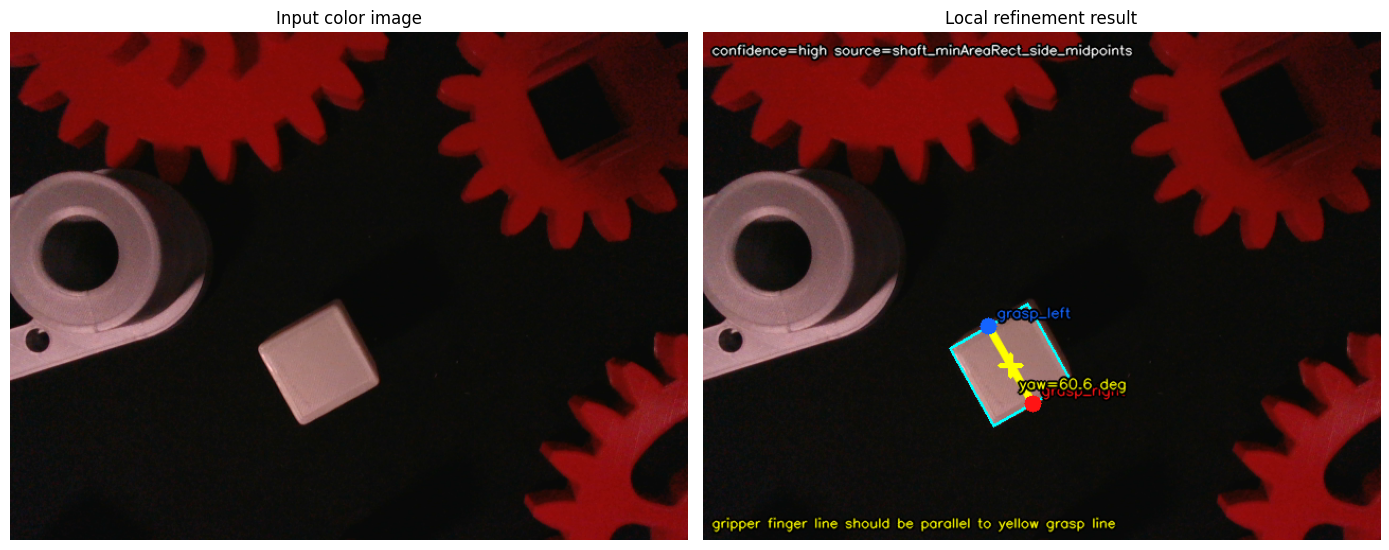

In [12]:
def save_local_outputs(
    result_dict,
    annotated_image,
    debug_images,
    json_path=OUTPUT_JSON,
    csv_path=OUTPUT_CSV,
    annotated_path=OUTPUT_ANNOTATED,
):
    json_path, csv_path, annotated_path = map(
        Path, (json_path, csv_path, annotated_path)
    )
    json_path.parent.mkdir(parents=True, exist_ok=True)
    with json_path.open("w", encoding="utf-8") as file:
        json.dump(result_dict, file, ensure_ascii=False, allow_nan=False, indent=2)

    rows = []
    for name, pixel in result_dict.get("pixel_points", {}).items():
        camera = result_dict.get("camera_points", {}).get(name, {})
        rows.append({
            "timestamp_sec": result_dict.get("timestamp_sec"),
            "target_type": result_dict.get("target_type"),
            "result_type": result_dict.get("result_type"),
            "point_name": name,
            "u": pixel.get("u"),
            "v": pixel.get("v"),
            "radius_px": pixel.get("radius_px"),
            "yaw_deg": result_dict.get("yaw_deg"),
            "depth_valid": camera.get("depth_valid"),
            "depth_m": camera.get("depth_m"),
            "depth_source": camera.get("depth_source"),
            "top_surface_depth_m": result_dict.get("top_surface_depth_m"),
            "top_surface_area_px": result_dict.get("top_surface_area_px"),
            "camera_x_m": camera.get("camera_x_m"),
            "camera_y_m": camera.get("camera_y_m"),
            "camera_z_m": camera.get("camera_z_m"),
            "camera_frame_id": camera.get("camera_frame_id", CAMERA_FRAME_ID),
            "confidence": result_dict.get("confidence"),
            "rule_note": result_dict.get("rule_note"),
        })
    fieldnames = [
        "timestamp_sec", "target_type", "result_type", "point_name",
        "u", "v", "radius_px", "yaw_deg", "depth_valid", "depth_m",
        "depth_source", "top_surface_depth_m", "top_surface_area_px",
        "camera_x_m", "camera_y_m", "camera_z_m",
        "camera_frame_id", "confidence", "rule_note",
    ]
    with csv_path.open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    if not cv2.imwrite(str(annotated_path), annotated_image):
        raise OSError(f"Could not save {annotated_path}")
    for name, image in debug_images.items():
        if isinstance(image, np.ndarray) and image.ndim in (2, 3):
            cv2.imwrite(str(json_path.parent / f"{name}.png"), image)
    return {
        "json": str(json_path),
        "csv": str(csv_path),
        "annotated": str(annotated_path),
    }


color_image_bgr, depth_image_m, intrinsics = load_selected_input()
result_dict, annotated_image, debug_images = run_local_refinement(
    color_image_bgr, depth_image_m, intrinsics, TARGET_TYPE
)
saved_paths = save_local_outputs(result_dict, annotated_image, debug_images)

print(json.dumps(result_dict, ensure_ascii=False, indent=2))
print("Saved:", saved_paths)
if intrinsics is None:
    print(
        "NOTE: pixel detection ran, but camera XYZ is invalid because true "
        "color intrinsics were not supplied."
    )

figure, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(color_image_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Input color image")
axes[1].imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
axes[1].set_title("Local refinement result")
for axis in axes:
    axis.axis("off")
figure.tight_layout()
plt.show()


### Operational reminder

- The right-side depth colormap in old screenshots is visualization only.
- Real 3D coordinates must use aligned raw depth in meters.
- Base-hole pixel coordinates use the black-hole centers, but hole depth uses the surrounding silver-ring median.
- All XYZ values are in `camera_color_optical_frame`, never robot base frame.

In [ ]:
# RealSense D435i live local RGB-D grasp-refinement viewer.
# Run this cell after all function cells above have been executed.

import time


def run_realsense_local_refinement_live(target_type=TARGET_TYPE):
    """Show the existing local detector on aligned live RGB-D and keep the latest result in memory."""
    try:
        import pyrealsense2 as rs_live
    except ImportError:
        print(
            "pyrealsense2 is not installed. Install the RealSense Python "
            "package before running this cell."
        )
        return

    if target_type not in VALID_TARGET_TYPES:
        print(
            f"Unsupported TARGET_TYPE={target_type!r}. "
            f"Choose one of: {sorted(VALID_TARGET_TYPES)}"
        )
        return

    window_name = "RealSense Local Grasp Refinement Live"
    pipeline = rs_live.pipeline()
    config = rs_live.config()
    config.enable_stream(
        rs_live.stream.color, 640, 480, rs_live.format.bgr8, 30
    )
    config.enable_stream(
        rs_live.stream.depth, 640, 480, rs_live.format.z16, 30
    )

    pipeline_started = False
    paused = False
    display_mode_index = 0
    previous_gray = None
    stable_frame_count = 0
    previous_time = None
    fps = 0.0
    last_base_views = {}
    last_available_modes = []
    last_mode_name = "annotated_result"
    latest_result = None
    latest_annotated = None
    latest_debug_images = None
    last_status = {
        "motion_score": 0.0,
        "state": "MOVING",
        "confidence": "unknown",
        "depth_valid": False,
    }

    try:
        try:
            profile = pipeline.start(config)
            pipeline_started = True
            color_sensor = profile.get_device().first_color_sensor()
            if color_sensor is not None:
                if color_sensor.supports(rs_live.option.power_line_frequency):
                    color_sensor.set_option(rs_live.option.power_line_frequency, 1)
                if color_sensor.supports(rs_live.option.brightness):
                    color_sensor.set_option(rs_live.option.brightness, -60)
            fixed_settings = globals().get("apply_fixed_realsense_rgbd_settings")
            if callable(fixed_settings):
                fixed_settings(profile, rs_live)
            create_depth_filters = globals().get("create_fixed_realsense_depth_filters")
            depth_filters = (
                create_depth_filters(rs_live) if callable(create_depth_filters) else []
            )
            align_to_color = rs_live.align(rs_live.stream.color)
            depth_scale = float(
                profile.get_device()
                .first_depth_sensor()
                .get_depth_scale()
            )
        except Exception as exc:
            print(
                "Could not start RealSense D435i. Check that the camera is "
                f"connected and not used by another process. Details: {exc}"
            )
            return

        print(
            f"Local live target: {target_type}. "
            "Controls: q/ESC quit, space pause/resume, d cycle debug views."
        )
        cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)

        # Allow auto-exposure to settle before evaluating motion and detection.
        for _ in range(max(1, int(LIVE_WARMUP_FRAMES))):
            pipeline.wait_for_frames(timeout_ms=5000)

        while True:
            if not paused:
                frames = pipeline.wait_for_frames(timeout_ms=5000)
                aligned_frames = align_to_color.process(frames)
                color_frame = aligned_frames.get_color_frame()
                depth_frame = aligned_frames.get_depth_frame()
                if not color_frame or not depth_frame:
                    print("Aligned color/depth frame unavailable; retrying.")
                    continue
                apply_depth_filters = globals().get("apply_fixed_realsense_depth_filters")
                if depth_filters and callable(apply_depth_filters):
                    depth_frame = apply_depth_filters(depth_frame, depth_filters)

                color_bgr = np.asanyarray(color_frame.get_data()).copy()
                depth_raw = np.asanyarray(depth_frame.get_data())
                depth_image_m = (
                    depth_raw.astype(np.float32) * depth_scale
                )
                color_intr = (
                    color_frame.profile
                    .as_video_stream_profile()
                    .intrinsics
                )
                intrinsics = {
                    "fx": float(color_intr.fx),
                    "fy": float(color_intr.fy),
                    "ppx": float(color_intr.ppx),
                    "ppy": float(color_intr.ppy),
                }

                result, annotated, debug_images = run_local_refinement(
                    color_bgr,
                    depth_image_m,
                    intrinsics,
                    target_type,
                )
                latest_result = result
                latest_annotated = annotated.copy()
                latest_debug_images = {
                    name: image.copy() if isinstance(image, np.ndarray) else image
                    for name, image in debug_images.items()
                }

                gray = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2GRAY)
                if previous_gray is None:
                    motion_score = 0.0
                    stable_frame_count = 0
                else:
                    motion_score = float(
                        cv2.mean(
                            cv2.absdiff(gray, previous_gray)
                        )[0]
                    )
                    stable_frame_count = (
                        stable_frame_count + 1
                        if motion_score < 2.0
                        else 0
                    )
                previous_gray = gray
                state = (
                    "STABLE"
                    if stable_frame_count >= 10
                    else "MOVING"
                )

                now = time.perf_counter()
                if previous_time is not None:
                    instant_fps = 1.0 / max(
                        now - previous_time, 1e-6
                    )
                    fps = (
                        instant_fps
                        if fps <= 0.0
                        else 0.85 * fps + 0.15 * instant_fps
                    )
                previous_time = now

                base_views = {
                    "annotated_result": annotated,
                    "color_image": color_bgr,
                }
                for name, image in debug_images.items():
                    if (
                        isinstance(image, np.ndarray)
                        and image.size > 0
                    ):
                        base_views[name] = image

                # This depth colormap is display-only. Detection and XYZ use
                # aligned metric depth_image_m above. Use the same fixed range
                # as realsense_depth_parameter_tuning.ipynb for fair comparison.
                display_min_m = globals().get("FIXED_DEPTH_DISPLAY_MIN_M", 0.15)
                display_max_m = globals().get("FIXED_DEPTH_DISPLAY_MAX_M", 1.20)
                valid_depth = (
                    np.isfinite(depth_image_m)
                    & (depth_image_m > display_min_m)
                    & (depth_image_m < display_max_m)
                )
                clipped_depth = np.clip(depth_image_m, display_min_m, display_max_m)
                depth_display = np.uint8(
                    255.0 * (clipped_depth - display_min_m)
                    / max(display_max_m - display_min_m, 1e-6)
                )
                depth_colormap = cv2.applyColorMap(depth_display, cv2.COLORMAP_TURBO)
                depth_colormap[~valid_depth] = (0, 0, 0)
                base_views["depth_colormap_display_only"] = depth_colormap

                preferred_modes = [
                    "annotated_result",
                    "color_image",
                    "black_background_workspace_mask",
                    "black_background_masked_input",
                    "red_mask",
                    "gear_component_mask",
                    "black_mask",
                    "shaft_mask",
                    "shaft_black_mask",
                    "object_mask",
                    "black_marker_mask",
                    "black_marker_search_mask",
                    "black_marker_candidates",
                    "selected_black_markers",
                    "base_roi_candidates",
                    "base_principal_point",
                    "base_mask",
                    "hole_search_mask",
                    "depth_invalid_mask",
                    "depth_boss_candidates_mask",
                    "depth_hole_candidates_mask",
                    "final_hole_mask",
                    "valid_depth_mask",
                    "top_surface_mask",
                    "top_surface_components",
                    "selected_grasp_components",
                    "selected_contours_mask",
                    "depth_colormap_display_only",
                ]
                available_modes = [
                    name
                    for name in preferred_modes
                    if name in base_views
                ]
                for name in base_views:
                    if name not in available_modes:
                        available_modes.append(name)
                display_mode_index %= len(available_modes)

                last_base_views = base_views
                last_available_modes = available_modes
                last_mode_name = available_modes[display_mode_index]
                last_status = {
                    "motion_score": motion_score,
                    "state": state,
                    "confidence": result.get(
                        "confidence", "unknown"
                    ),
                    "depth_valid": bool(
                        result.get("depth_valid", False)
                    ),
                }

            if not last_base_views:
                continue

            if not paused and last_available_modes:
                display_mode_index %= len(last_available_modes)
                last_mode_name = last_available_modes[
                    display_mode_index
                ]
            view = last_base_views[last_mode_name]
            if view.ndim == 2:
                view = cv2.cvtColor(view, cv2.COLOR_GRAY2BGR)
            else:
                view = view.copy()

            state = last_status["state"]
            status_color = (
                (40, 220, 40)
                if state == "STABLE"
                else (0, 165, 255)
            )
            status_text = (
                f"FPS {fps:5.1f}  target {target_type}  "
                f"{state}  motion {last_status['motion_score']:.2f}"
            )
            result_text = (
                f"confidence {last_status['confidence']}  "
                f"depth_valid {last_status['depth_valid']}  "
                f"view {last_mode_name}"
            )
            cv2.putText(
                view,
                status_text,
                (10, 24),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (0, 0, 0),
                3,
                cv2.LINE_AA,
            )
            cv2.putText(
                view,
                status_text,
                (10, 24),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                status_color,
                1,
                cv2.LINE_AA,
            )
            cv2.putText(
                view,
                result_text,
                (10, 47),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.46,
                (255, 255, 255),
                1,
                cv2.LINE_AA,
            )
            if paused:
                cv2.putText(
                    view,
                    "PAUSED",
                    (10, 72),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 0, 255),
                    2,
                    cv2.LINE_AA,
                )

            cv2.imshow(window_name, view)
            key = cv2.waitKey(1 if not paused else 30) & 0xFF
            if key in (ord("q"), 27):
                break
            if key == ord(" "):
                paused = not paused
                print(
                    "Local live view paused."
                    if paused
                    else "Local live view resumed."
                )
            elif key == ord("d") and last_available_modes:
                display_mode_index = (
                    display_mode_index + 1
                ) % len(last_available_modes)
                last_mode_name = last_available_modes[
                    display_mode_index
                ]

    except KeyboardInterrupt:
        print("Local live detection interrupted.")
    except Exception as exc:
        print(f"RealSense local live detection stopped: {exc}")
    finally:
        global last_live_result, last_live_annotated_image, last_live_debug_images, result_dict
        if latest_result is not None:
            last_live_result = latest_result
            last_live_annotated_image = latest_annotated
            last_live_debug_images = latest_debug_images
            result_dict = latest_result
            print("Latest live result stored in `last_live_result` and `result_dict`.")
        if pipeline_started:
            pipeline.stop()
        cv2.destroyAllWindows()
        print("RealSense local live detection closed.")


run_realsense_local_refinement_live(TARGET_TYPE)


Applying fixed RealSense RGB-D settings
RGB enable_auto_exposure: set to 0.0
RGB auto_exposure_priority: set to 0.0
RGB power_line_frequency: set to 1.0
RGB exposure: set to 200.0
RGB gain: set to 96.0
RGB enable_auto_white_balance: set to 0.0
RGB white_balance: set to 4600.0
RGB brightness: set to 0.0
RGB contrast: set to 45.0
RGB saturation: set to 58.0
RGB sharpness: set to 35.0
RGB gamma: set to 300.0
Depth enable_auto_exposure: set to 0.0
Depth exposure: set to 6000.0
Depth gain: set to 16.0
Depth emitter_enabled: set to 1.0
Depth laser_power: set to 150.0
Depth visual_preset: set to 4.0
Fixed depth filters: spatial, temporal
Local live target: shaft_small. Controls: q/ESC quit, space pause/resume, d cycle debug views.


QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/jingyun/anaconda3/envs/xinyu_zhuo/lib/python3.10/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFon

Local live view paused.
Local live view resumed.
Local live view paused.
Local live view resumed.


In [ ]:
# Display selected local target points in pixel, camera, and panda_link0/base coordinates.
# Run this after a successful local detection. Fill T_BASE_GRIPPER_FOR_LINK0
# with the synchronized robot pose captured at the same time as the RGB-D image.

from pathlib import Path
import json
import numpy as np
import pandas as pd

HAND_EYE_RESULT_PATH = Path("cam_calibration/config/hand_eye_result.json")
T_BASE_GRIPPER_FOR_LINK0 = None  # Replace with synchronized 4x4 T_base_gripper.
GRIPPER_BASE_YAW_OFFSET_DEG_FOR_LINK0 = 90.0

T_BASE_GRIPPER_FOR_LINK0 = np.array([
    [0.997364098,  0.023870181, -0.068520587,  0.328011652],
    [0.032552663, -0.991170276,  0.128537188, -0.172737825],
    [-0.064847363, -0.130428904, -0.989334686,  0.435382792],
    [0.000000000,  0.000000000,  0.000000000,  1.000000000],
], dtype=np.float64)

# Paste one synchronized robot pose below. Do not keep multiple active definitions.

CENTER_CANDIDATES_BY_TARGET = {
    "gear_small": ["gear_center"],
    "gear_large": ["gear_center"],
    "gear_compound": ["gear_center"],
    "shaft_small": ["rect_center"],
    "shaft_large": ["rect_center"],
    "screw": ["screw_center", "top_surface_center"],
    "base": ["top_surface_center", "gear_center", "rect_center", "screw_center"],
}
FALLBACK_CENTER_CANDIDATES = [
    "gear_center", "rect_center", "screw_center", "top_surface_center", "grasp_midpoint",
]


def _select_current_local_result_for_link0():
    try:
        return last_live_result, "in-memory last_live_result"
    except NameError:
        pass
    try:
        return result_dict, "in-memory result_dict"
    except NameError:
        pass
    if not OUTPUT_JSON.exists():
        raise FileNotFoundError(
            f"没有找到 {OUTPUT_JSON}，请先运行 local detection cell 生成 result_dict。"
        )
    return json.loads(OUTPUT_JSON.read_text(encoding="utf-8-sig")), str(OUTPUT_JSON)


def _validate_homogeneous_transform(T, name):
    matrix = np.asarray(T, dtype=np.float64)
    if matrix.shape != (4, 4) or not np.all(np.isfinite(matrix)):
        raise ValueError(f"{name} must be a finite 4x4 matrix")
    if not np.allclose(matrix[3], [0.0, 0.0, 0.0, 1.0], atol=1e-6):
        raise ValueError(f"{name} has an invalid homogeneous last row")
    rotation = matrix[:3, :3]
    if not np.allclose(rotation.T @ rotation, np.eye(3), atol=1e-3):
        raise ValueError(f"{name} rotation is not orthonormal")
    if not np.isclose(np.linalg.det(rotation), 1.0, atol=1e-3):
        raise ValueError(f"{name} rotation determinant must be +1")
    return matrix



def _load_t_gripper_camera_for_link0(path):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    if "T_gripper_camera" not in data:
        raise KeyError(f"{path} does not contain T_gripper_camera")
    return _validate_homogeneous_transform(data["T_gripper_camera"], "T_gripper_camera")


def _pick_center_point_name(result):
    pixel_points = result.get("pixel_points", {}) or {}
    target_type = result.get("target_type")
    for name in CENTER_CANDIDATES_BY_TARGET.get(target_type, []):
        if name in pixel_points:
            return name
    for name in FALLBACK_CENTER_CANDIDATES:
        if name in pixel_points:
            return name
    return None


def _camera_xyz_from_table_row(table, point_name):
    matches = table[table["point_name"] == point_name]
    if matches.empty:
        raise ValueError(f"{point_name} is missing from the displayed point table")
    row = matches.iloc[0]
    xyz = row[["camera_x_m", "camera_y_m", "camera_z_m"]].to_numpy(dtype=np.float64)
    if not np.all(np.isfinite(xyz)):
        raise ValueError(f"{point_name} has no valid camera XYZ")
    return xyz


def _compute_grasp_yaw_summary(point_table, yaw_offset_deg=0.0):
    left = point_table[point_table["point_name"] == "grasp_left"]
    right = point_table[point_table["point_name"] == "grasp_right"]
    if left.empty or right.empty:
        return None
    left_base = left.iloc[0][["link0_x_m", "link0_y_m", "link0_z_m"]].to_numpy(dtype=np.float64)
    right_base = right.iloc[0][["link0_x_m", "link0_y_m", "link0_z_m"]].to_numpy(dtype=np.float64)
    if not np.all(np.isfinite(left_base)) or not np.all(np.isfinite(right_base)):
        return None
    line_base = right_base - left_base
    line_xy_length = float(np.hypot(line_base[0], line_base[1]))
    if line_xy_length < 1e-6:
        raise ValueError("transformed grasp line has near-zero length in link0/base XY")
    yaw_directed = float(np.degrees(np.arctan2(line_base[1], line_base[0])))
    yaw_directed = float(((yaw_directed + yaw_offset_deg + 180.0) % 360.0) - 180.0)
    yaw_axis = float(((yaw_directed + 90.0) % 180.0) - 90.0)
    midpoint_base = 0.5 * (left_base + right_base)
    return {
        "grasp_midpoint_link0_x_m": float(midpoint_base[0]),
        "grasp_midpoint_link0_y_m": float(midpoint_base[1]),
        "grasp_midpoint_link0_z_m": float(midpoint_base[2]),
        "grasp_line_vector_link0_x_m": float(line_base[0]),
        "grasp_line_vector_link0_y_m": float(line_base[1]),
        "grasp_line_vector_link0_z_m": float(line_base[2]),
        "grasp_line_length_link0_xy_m": line_xy_length,
        "yaw_link0_deg_directed": yaw_directed,
        "yaw_link0_deg_axis": yaw_axis,
        "yaw_offset_deg": float(yaw_offset_deg),
    }


current_result, source_name = _select_current_local_result_for_link0()
center_name = _pick_center_point_name(current_result)
is_base_target = current_result.get("target_type") == "base"
if is_base_target:
    selected_names = ["hole_large", "hole_small", "hole_screw"]
else:
    selected_names = []
    if center_name is not None:
        selected_names.append(center_name)
    for name in ["grasp_left", "grasp_right"]:
        if name not in selected_names:
            selected_names.append(name)

pixel_points = current_result.get("pixel_points", {}) or {}
camera_points = current_result.get("camera_points", {}) or {}
rows = []
for name in selected_names:
    pixel = pixel_points.get(name, {}) or {}
    camera = camera_points.get(name, {}) or {}
    row = {
        "point_name": name,
        "role": "base_hole" if is_base_target else ("target_center" if name == center_name else "grasp"),
        "u_px": pixel.get("u"),
        "v_px": pixel.get("v"),
        "depth_valid": camera.get("depth_valid"),
        "depth_m": camera.get("depth_m"),
        "camera_x_m": camera.get("camera_x_m"),
        "camera_y_m": camera.get("camera_y_m"),
        "camera_z_m": camera.get("camera_z_m"),
        "link0_x_m": None,
        "link0_y_m": None,
        "link0_z_m": None,
        "camera_frame_id": camera.get("camera_frame_id", CAMERA_FRAME_ID),
        "link0_frame_id": "panda_link0",
        "valid_link0": False,
        "reason": None,
    }
    if name not in pixel_points and name not in camera_points:
        row["reason"] = "point not found in current_result"
    elif any(row[key] is None for key in ["camera_x_m", "camera_y_m", "camera_z_m"]):
        row["reason"] = "missing camera XYZ"
    rows.append(row)

point_link0_table = pd.DataFrame(rows)

print("Source:", source_name)
print("target_type:", current_result.get("target_type"))
print("result_type:", current_result.get("result_type"))
print("status:", current_result.get("status"))
print("Transform: P_link0 = T_BASE_GRIPPER_FOR_LINK0 @ T_gripper_camera @ P_camera")

if T_BASE_GRIPPER_FOR_LINK0 is None:
    print("未填写 T_BASE_GRIPPER_FOR_LINK0：下表先显示 pixel/camera 坐标；填写同步机器人位姿后会计算 link0 坐标和 yaw。")
else:
    T_base_gripper_for_link0 = _validate_homogeneous_transform(
        T_BASE_GRIPPER_FOR_LINK0, "T_BASE_GRIPPER_FOR_LINK0"
    )
    T_gripper_camera_for_link0 = _load_t_gripper_camera_for_link0(HAND_EYE_RESULT_PATH)
    T_base_camera_for_link0 = T_base_gripper_for_link0 @ T_gripper_camera_for_link0

    for idx, row in point_link0_table.iterrows():
        camera_xyz = row[["camera_x_m", "camera_y_m", "camera_z_m"]].to_numpy(dtype=np.float64)
        if not np.all(np.isfinite(camera_xyz)):
            continue
        P_link0 = T_base_camera_for_link0 @ np.r_[camera_xyz, 1.0]
        point_link0_table.loc[idx, "link0_x_m"] = float(P_link0[0])
        point_link0_table.loc[idx, "link0_y_m"] = float(P_link0[1])
        point_link0_table.loc[idx, "link0_z_m"] = float(P_link0[2])
        point_link0_table.loc[idx, "valid_link0"] = bool(np.all(np.isfinite(P_link0[:3])))
        if not bool(point_link0_table.loc[idx, "valid_link0"]):
            point_link0_table.loc[idx, "reason"] = "non-finite link0 coordinate"

if point_link0_table.empty:
    if is_base_target:
        print("当前 base 结果没有 hole_large/hole_small/hole_screw 可显示。请确认 base_holes 检测成功且 result_dict 已更新。")
    else:
        print("当前结果没有目标中心点或 grasp_left/grasp_right 可显示。请确认检测成功且 result_dict 已更新。")
else:
    display(point_link0_table)

if T_BASE_GRIPPER_FOR_LINK0 is not None and not point_link0_table.empty:
    if is_base_target:
        base_hole_rows = []
        for _, hole_row in point_link0_table.iterrows():
            target_position = hole_row[["link0_x_m", "link0_y_m", "link0_z_m"]].to_numpy(dtype=np.float64)
            if not np.all(np.isfinite(target_position)):
                continue
            base_hole_rows.append({
                "point_name": hole_row["point_name"],
                "target_link0_x_m": float(target_position[0]),
                "target_link0_y_m": float(target_position[1]),
                "target_link0_z_m": float(target_position[2]),
                "yaw_link0_deg_directed": None,
                "yaw_link0_deg_axis": None,
                "yaw_offset_deg": None,
                "note": "base hole insertion target has position only; yaw is intentionally None",
            })
        if not base_hole_rows:
            print("base 三个孔的 link0 坐标不完整，暂不能输出插入位置。")
        else:
            display(pd.DataFrame(base_hole_rows))
            print("\nReady for move_to_link0_pose.py manual test:")
            for item in base_hole_rows:
                target_position = [
                    item["target_link0_x_m"],
                    item["target_link0_y_m"],
                    item["target_link0_z_m"],
                ]
                print(f"# {item['point_name']}")
                print(
                    "target_position = "
                    f"[{target_position[0]:.6f}, {target_position[1]:.6f}, {target_position[2]:.6f}]"
                )
                print("target_yaw_link0_deg = None")
                print("target_quat_xyzw = None")
    else:
        yaw_summary = _compute_grasp_yaw_summary(
            point_link0_table, GRIPPER_BASE_YAW_OFFSET_DEG_FOR_LINK0
        )
        if yaw_summary is None:
            print("grasp_left/grasp_right 的 link0 坐标不完整，暂不能计算 yaw。")
        else:
            display(pd.DataFrame([yaw_summary]))

            target_position = [
                yaw_summary["grasp_midpoint_link0_x_m"],
                yaw_summary["grasp_midpoint_link0_y_m"],
                yaw_summary["grasp_midpoint_link0_z_m"],
            ]
            yaw_rad = np.deg2rad(yaw_summary["yaw_link0_deg_axis"])
            target_quat_xyzw = [
                float(np.cos(0.5 * yaw_rad)),
                float(np.sin(0.5 * yaw_rad)),
                0.0,
                0.0,
            ]
            print("\nReady for move_to_link0_pose.py manual test:")
            print(
                "target_position = "
                f"[{target_position[0]:.6f}, {target_position[1]:.6f}, {target_position[2]:.6f}]"
            )
            print(
                "target_quat_xyzw = "
                f"[{target_quat_xyzw[0]:.6f}, {target_quat_xyzw[1]:.6f}, "
                f"{target_quat_xyzw[2]:.1f}, {target_quat_xyzw[3]:.1f}]"
            )


Source: in-memory last_live_result
target_type: shaft_small
result_type: grasp
status: ok
Transform: P_link0 = T_BASE_GRIPPER_FOR_LINK0 @ T_gripper_camera @ P_camera


,point_name,role,u_px,v_px,depth_valid,depth_m,camera_x_m,camera_y_m,camera_z_m,link0_x_m,link0_y_m,link0_z_m,camera_frame_id,link0_frame_id,valid_link0,reason
0,rect_center,target_center,290.268585,315.255249,True,0.201,-0.011818,0.018589,0.201,0.28374,-0.189767,0.174143,camera_color_optical_frame,panda_link0,True,None
1,grasp_left,grasp,253.473328,335.952576,True,0.202,-0.024140,0.025588,0.202,0.291384,-0.201355,0.171127,camera_color_optical_frame,panda_link0,True,None
2,grasp_right,grasp,327.063843,294.557922,True,0.202,0.000386,0.011775,0.202,0.276138,-0.178037,0.175152,camera_color_optical_frame,panda_link0,True,None


,grasp_midpoint_link0_x_m,grasp_midpoint_link0_y_m,grasp_midpoint_link0_z_m,grasp_line_vector_link0_x_m,grasp_line_vector_link0_y_m,grasp_line_vector_link0_z_m,grasp_line_length_link0_xy_m,yaw_link0_deg_directed,yaw_link0_deg_axis,yaw_offset_deg
0,0.283761,-0.189696,0.173139,-0.015245,0.023318,0.004024,0.027859,-146.823084,33.176916,90.0



Ready for move_to_link0_pose.py manual test:
target_position = [0.283761, -0.189696, 0.173139]
target_quat_xyzw = [0.958380, 0.285495, 0.0, 0.0]
